# Fuentes complementarias, variables candidatas y modelo de referencia, 2023–2025

Caracterización de los factores que afectan la producción de oro en Colombia, 2023–2025. Cuaderno de resultados: el título de cada celda dice qué calcula. Requiere el panel del cuaderno 01 en `06_panel/` y las fuentes descargadas con `scripts/02_descarga_complementos.py`; escribe sus salidas en `06_panel/` y `07_figuras/`.

## 0. Configuración, funciones auxiliares y lectura del panel del cuaderno 01

In [1]:
import json
import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
AZUL, DORADO, TEAL, GRIS = "#1F3864", "#BF8F00", "#2E7D77", "#9E9E9E"
ANIOS = [2023, 2024, 2025]
ONZA_TROY_G = 31.1034768
TOPE_BAREQ_G_ANIO = 35 * 12

def encontrar_raiz():
    p = Path.cwd().resolve()
    for c in [p] + list(p.parents):
        if (c / "02_produccion_regalias").exists() and (c / "05_delictiva").exists():
            return c
    raise FileNotFoundError("No encuentro BDATOS-ORO con la carpeta 05_delictiva: corre antes scripts/02_descarga_complementos.py")

RAIZ = encontrar_raiz(); SAL = RAIZ / "06_panel"
print("Raíz del repositorio:", RAIZ)
CHECKS = []

def check(bloque, nombre, ok, detalle=""):
    CHECKS.append((bloque, nombre, "OK" if ok else "REVISAR", str(detalle)))
    print(f"[{'OK' if ok else 'REVISAR':7}] {nombre}" + (f" — {detalle}" if detalle != "" else ""))

def perfil(df):
    ej = {c: (df[c].dropna().iloc[0] if df[c].notna().any() else None) for c in df.columns}
    return pd.DataFrame({"tipo": df.dtypes.astype(str), "n_no_nulos": df.notna().sum(), "pct_nulos": (df.isna().mean() * 100).round(2), "n_unicos": df.nunique(), "ejemplo": pd.Series(ej)})

def resumen_num(s, nombre=None):
    s = pd.to_numeric(s, errors="coerce"); q = s.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    return pd.Series({"n": s.notna().sum(), "nulos": s.isna().sum(), "ceros": (s == 0).sum(), "media": s.mean(), "desv_est": s.std(), "cv": (s.std() / s.mean()) if s.mean() else np.nan,
                      "min": s.min(), "p5": q[0.05], "p25": q[0.25], "mediana": q[0.5], "p75": q[0.75], "p95": q[0.95], "max": s.max(), "asimetria": s.skew(), "curtosis": s.kurt()}, name=nombre or s.name)

def tabla_resumen(df, cols):
    return pd.concat([resumen_num(df[c], c) for c in cols], axis=1).T

def normaliza(t):
    if pd.isna(t):
        return ""
    return re.sub(r"[^A-Z0-9]", "", unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode().upper())

DEPTOS = {"05": "Antioquia", "08": "Atlántico", "11": "Bogotá, D.C.", "13": "Bolívar", "15": "Boyacá", "17": "Caldas", "18": "Caquetá", "19": "Cauca", "20": "Cesar", "23": "Córdoba",
          "25": "Cundinamarca", "27": "Chocó", "41": "Huila", "44": "La Guajira", "47": "Magdalena", "50": "Meta", "52": "Nariño", "54": "Norte de Santander", "63": "Quindío", "66": "Risaralda",
          "68": "Santander", "70": "Sucre", "73": "Tolima", "76": "Valle del Cauca", "81": "Arauca", "85": "Casanare", "86": "Putumayo", "88": "San Andrés", "91": "Amazonas", "94": "Guainía",
          "95": "Guaviare", "97": "Vaupés", "99": "Vichada"}

panel = pd.read_csv(SAL / "panel_municipal_2023_2025.csv", dtype={"codigo_dane": str})
pq = pd.read_csv(SAL / "panel_municipal_trimestral_2023_2025.csv", dtype={"codigo_dane": str})
UNIVERSO = sorted(panel.codigo_dane.unique())
ficha = json.load(open(RAIZ / "ficha_descarga_complementos.json", encoding="utf-8"))
print(f"Panel del notebook 01: {panel.shape[0]} filas, {len(UNIVERSO)} municipios; ficha de descarga del {ficha.get('fecha_descarga')}")

Raíz del repositorio: /home/claude/jdnieto28-hub/tesis
Panel del notebook 01: 591 filas, 197 municipios; ficha de descarga del 2026-10-06


## 1. Inventario de las fuentes nuevas: archivo, fuente, grano, ventana y tamaño

In [2]:
INVENTARIO = [
    ("05 Delictiva", "05_delictiva/homicidio_municipal_mensual_2023_2025.csv", "Policía Nacional (datos.gov.co m8fd-ahd9)", "municipio × mes", "2023–2025"),
    ("05 Delictiva", "05_delictiva/extorsion_municipal_mensual_2023_2025.csv", "Policía Nacional (datos.gov.co q2ib-t9am)", "municipio × mes", "2023–2025"),
    ("11 Población", "11_poblacion/dane_poblacion_municipal_2023_2025.csv", "DANE, proyecciones post-censo 2018 (jul-2025)", "municipio × año", "2023–2025"),
    ("12 RUCOM", "12_titulos_rucom/rucom_titulos_oro.csv", "ANM RUCOM (datos.gov.co 42ha-fhvj)", "título × municipio × mineral", "foto ene-2025"),
    ("12 RUCOM", "12_titulos_rucom/rucom_solicitudes_legalizacion_oro.csv", "ANM RUCOM (datos.gov.co 7amp-4swy)", "solicitud × municipio × mineral", "foto ene-2025"),
    ("12 RUCOM", "12_titulos_rucom/rucom_subcontratos_formalizacion_oro.csv", "ANM RUCOM (datos.gov.co xzu3-gnau)", "subcontrato × municipio × mineral", "foto ene-2025"),
    ("12 RUCOM", "12_titulos_rucom/rucom_figuras_oro_municipio.csv", "derivada de las tres anteriores", "municipio", "foto"),
    ("12 RUCOM", "12_titulos_rucom/rmn_anotaciones_titulos_2023_2025.csv", "ANM Registro Minero Nacional (datos.gov.co si2v-pbq5)", "anotación", "2023–2025"),
    ("13 Territorio", "13_territorio/mgn_area_municipal_km2.csv", "DANE MGN 2024", "municipio", "fija"),
    ("13 Territorio", "13_territorio/municipios_pdet.csv", "ART (datos.gov.co idrk-ba8y)", "municipio", "fija"),
    ("01 Precio", "01_precio/upme_precio_base_regalias_opp_mensual_2025.csv", "UPME, página de precios base", "nacional × mes", "mar–dic 2025"),
    ("06 Panel", "06_panel/complementos_municipio_anual_2023_2025.csv", "derivada (script 02)", "municipio × año", "2023–2025"),
]
filas = []
for bloque, rel, fuente, grano, ventana in INVENTARIO:
    ruta = RAIZ / rel
    if not ruta.exists():
        filas.append((bloque, rel, fuente, grano, ventana, "NO EXISTE", None, None)); continue
    df = pd.read_csv(ruta, dtype=str)
    filas.append((bloque, rel, fuente, grano, ventana, round(ruta.stat().st_size / 1024, 1), len(df), df.shape[1]))
inventario = pd.DataFrame(filas, columns=["bloque", "archivo", "fuente", "grano", "ventana", "KB", "filas", "columnas"])
check("Inventario", "Todas las fuentes nuevas están en el repositorio", (inventario.KB != "NO EXISTE").all(), f"{(inventario.KB == 'NO EXISTE').sum()} faltantes")
inventario

[OK     ] Todas las fuentes nuevas están en el repositorio — 0 faltantes


,bloque,archivo,fuente,grano,ventana,KB,filas,columnas
0,05 Delictiva,05_delictiva/homicidio_municipal_mensual_2023_2025.csv,Policía Nacional (datos.gov.co m8fd-ahd9),municipio × mes,2023–2025,398.70,11720,6
1,05 Delictiva,05_delictiva/extorsion_municipal_mensual_2023_2025.csv,Policía Nacional (datos.gov.co q2ib-t9am),municipio × mes,2023–2025,326.60,9578,6
2,11 Población,11_poblacion/dane_poblacion_municipal_2023_2025.csv,"DANE, proyecciones post-censo 2018 (jul-2025)",municipio × año,2023–2025,194.50,3369,8
3,12 RUCOM,12_titulos_rucom/rucom_titulos_oro.csv,ANM RUCOM (datos.gov.co 42ha-fhvj),título × municipio × mineral,foto ene-2025,133.70,1509,7
4,12 RUCOM,12_titulos_rucom/rucom_solicitudes_legalizacion_oro.csv,ANM RUCOM (datos.gov.co 7amp-4swy),solicitud × municipio × mineral,foto ene-2025,89.40,912,6
5,12 RUCOM,12_titulos_rucom/rucom_subcontratos_formalizacion_oro.csv,ANM RUCOM (datos.gov.co xzu3-gnau),subcontrato × municipio × mineral,foto ene-2025,20.30,201,8
6,12 RUCOM,12_titulos_rucom/rucom_figuras_oro_municipio.csv,derivada de las tres anteriores,municipio,foto,3.40,159,8
7,12 RUCOM,12_titulos_rucom/rmn_anotaciones_titulos_2023_2025.csv,ANM Registro Minero Nacional (datos.gov.co si2v-pbq5),anotación,2023–2025,"3,282.10",12988,10
8,13 Territorio,13_territorio/mgn_area_municipal_km2.csv,DANE MGN 2024,municipio,fija,33.10,1121,3
9,13 Territorio,13_territorio/municipios_pdet.csv,ART (datos.gov.co idrk-ba8y),municipio,fija,9.00,170,6


### 1.1 Conexión de las 17 tablas: llave, unicidad, cobertura del universo y balance de los tres paneles

In [3]:
def _leer(rel, **kw):
    return pd.read_csv(RAIZ / rel, dtype=str, encoding="utf-8-sig", **kw)

def _cod(df, col):
    return df[col].astype(str).str.strip().str.zfill(5)

FUENTES = [
    ("ANM_REGALIAS_TRIM", "02_produccion_regalias/anm_regalias_oro_trimestral.csv", ["codigo_dane", "a_o_liquidado", "trimestre"], "registro de liquidación (varios por municipio × trimestre)", "suma de registros", "codigo_dane", "2023–2025 (corte ago-2026)", lambda d: d.a_o_liquidado.astype(int).between(2023, 2025), "anual, trimestral"),
    ("ANM_ORO_MENSUAL", "02_produccion_regalias/anm_oro_municipio_mensual_2012_2026.csv", ["cod_dane", "anio", "mes"], "municipio × mes", "directa", "cod_dane", "2023–2025 (descarga 8-oct-2026)", lambda d: d.anio.astype(int).between(2023, 2025), "mensual"),
    ("SIMCI_EXPLOTADOR", "09_produccion_explotador/produccion_oro_municipal_explotador_simci_2017_2025.csv", ["codigo_municipio", "anio", "trimestre", "explotador"], "municipio × año × explotador (consolidado anual)", "suma de registros", "codigo_municipio", "2023–2025, consolidado anual", lambda d: d.anio.astype(int).between(2023, 2025) & (d.trimestre.str.lower().str.contains("consol")), "anual"),
    ("EVOA_MUNICIPIO", "03_evoa/arcgis_simci/01_evoa_municipio_ha_2014_2023.csv", ["codigo_municipio", "anio"], "municipio × año", "directa", "codigo_municipio", "2023 (y promedio 2021–2023)", lambda d: d.anio.astype(int) == 2023, "anual (fija)"),
    ("EVOA_FIGURA_LEY", "03_evoa/arcgis_simci/05_evoa_municipio_clases_figura_ley_2021_2023.csv", ["codigo_municipio", "anio"], "municipio × año", "directa", "codigo_municipio", "2023", lambda d: d.anio.astype(int) == 2023, "anual (fija)"),
    ("RUCOM_BAREQUEROS", "04_rucom/rucom_barequeros_metales_preciosos_municipio.csv", ["codigo_dane"], "municipio (padrón vigente)", "directa", "codigo_dane", "foto 2-sep-2026", None, "anual, mensual (fija)"),
    ("RUCOM_FIGURAS_ORO", "12_titulos_rucom/rucom_figuras_oro_municipio.csv", ["codigo_dane"], "municipio (corte ene-2025)", "directa", "codigo_dane", "foto ene-2025", None, "anual (fija)"),
    ("OPERATIVOS_MINAS", "08_operativos/minas_intervenidas_municipal_mensual.csv", ["cod_muni", "anio", "mes"], "municipio × mes", "directa", "cod_muni", "2023–2025", lambda d: d.anio.astype(int).between(2023, 2025), "anual, trimestral, mensual"),
    ("OPERATIVOS_CAPTURAS", "08_operativos/capturas_mineria_ilegal_municipal_mensual.csv", ["cod_muni", "anio", "mes"], "municipio × mes", "directa", "cod_muni", "2023–2025", lambda d: d.anio.astype(int).between(2023, 2025), "anual, trimestral, mensual"),
    ("OPERATIVOS_MAQUINARIA", "08_operativos/incautaciones_maquinaria_municipal_mensual.csv", ["cod_muni", "anio", "mes", "clase_de_bien", "unidad_de_medida"], "municipio × mes × clase de bien", "suma de clases de bien", "cod_muni", "2023–2025", lambda d: d.anio.astype(int).between(2023, 2025), "anual, trimestral, mensual"),
    ("DANE_POBLACION", "11_poblacion/dane_poblacion_municipal_2023_2025.csv", ["cod_muni", "anio"], "municipio × año", "directa", "cod_muni", "2023–2025", None, "anual"),
    ("MGN_AREA", "13_territorio/mgn_area_municipal_km2.csv", ["cod_muni"], "municipio", "directa", "cod_muni", "MGN 2024", None, "anual (fija)"),
    ("ART_PDET", "13_territorio/municipios_pdet.csv", ["cod_muni"], "municipio", "directa", "cod_muni", "fija", None, "anual (fija)"),
    ("PRECIO_ORO_MENSUAL", "01_precio/precio_oro_mensual_usd_onza.csv", ["mes"], "nacional × mes", "promedio de meses", None, "2023–2025", lambda d: d.mes.str[:4].astype(int).between(2023, 2025), "anual, trimestral, mensual"),
    ("TRM_MENSUAL", "01_precio/trm_mensual_promedio.csv", ["anio_mes"], "nacional × mes", "promedio de meses", None, "2023–2025", lambda d: d.anio_mes.str[:4].astype(int).between(2023, 2025), "anual, trimestral, mensual"),
    ("UPME_PRECIO_BASE", "01_precio/upme_precio_base_regalias_opp_mensual_2025.csv", ["mes"], "nacional × mes", "directa", None, "mar–dic 2025", None, "solo control (sección 6)"),
    ("COMTRADE_7108_ANUAL", "10_exportaciones/comtrade_expo_oro_7108_anual_2010_2025.csv", ["anio"], "nacional × año", "directa", None, "2023–2025", lambda d: d.anio.astype(int).between(2023, 2025), "serie nacional"),
]
filas = []
for tabla, rel, llave, grano, regla, colmun, ventana, filtro, destino in FUENTES:
    d = _leer(rel)
    d.columns = [c.strip().lstrip("\ufeff") for c in d.columns]
    dup = int(d.duplicated(llave).sum())
    multip = int(d.groupby(llave).size().max())
    dv = d[filtro(d)] if filtro is not None else d
    if colmun is not None:
        codigos = _cod(dv, colmun)
        n_mun, en_uni = codigos.nunique(), int(codigos[codigos.isin(UNIVERSO)].nunique())
        invalidos = sorted(codigos[~((codigos.str.len() == 5) & codigos.str[:2].isin(DEPTOS))].unique())
    else:
        n_mun = en_uni = None; invalidos = []
    filas.append((tabla, rel, " + ".join(llave), grano, regla, len(d), multip, ventana, len(dv), n_mun, en_uni, (f"{en_uni / len(UNIVERSO) * 100:.0f} %" if en_uni is not None else "nacional"), destino))
    if regla == "suma de registros":
        check("Conexión", f"{tabla}: la llave ({' + '.join(llave)}) repite hasta {multip} registros, que el panel suma; códigos DANE válidos", not invalidos, f"{dup} filas repiten llave" + (f"; códigos inválidos {invalidos}" if invalidos else ""))
    else:
        check("Conexión", f"{tabla}: una fila por llave ({' + '.join(llave)}) y códigos DANE válidos", dup == 0 and not invalidos, f"{dup} duplicados" + (f"; códigos inválidos {invalidos} (fila excluida en el panel)" if invalidos else ""))
conexion = pd.DataFrame(filas, columns=["tabla", "archivo", "llave", "grano_del_archivo", "regla_de_union", "filas_archivo", "max_filas_por_llave", "ventana_usada", "filas_en_ventana", "municipios_en_ventana", "municipios_del_universo", "cobertura_universo", "se_une_al_panel"])
display(conexion.drop(columns=["archivo", "grano_del_archivo"]).set_index("tabla"))

panel_m = pd.read_csv(SAL / "panel_municipal_mensual_2023_2025.csv", dtype={"codigo_dane": str})
check("Conexión", "Panel anual balanceado: 197 municipios × 3 años = 591 filas, sin duplicados", len(panel) == 197 * 3 and not panel.duplicated(["codigo_dane", "anio"]).any())
check("Conexión", "Panel trimestral balanceado: 197 × 12 = 2.364 filas, sin duplicados", len(pq) == 197 * 12 and not pq.duplicated(["codigo_dane", "anio", "trim"]).any())
check("Conexión", "Panel mensual balanceado: 197 × 36 = 7.092 filas, sin duplicados", len(panel_m) == 197 * 36 and not panel_m.duplicated(["codigo_dane", "anio", "mes"]).any())
check("Conexión", "Los tres paneles comparten el mismo universo de 197 códigos DANE", set(panel.codigo_dane) == set(pq.codigo_dane) == set(panel_m.codigo_dane))
ga = panel.groupby("anio").gramos_anm.sum(); gq = pq.groupby("anio").gramos_anm.sum(); gm = panel_m.groupby("anio").gramos_anm.sum()
check("Conexión", "Trimestral agregado por año = anual (misma versión ANM, agosto de 2026)", np.allclose(ga.values, gq.reindex(ga.index).values, rtol=1e-6), {a: f"{v/1e6:.2f} t" for a, v in ga.items()})
dif_m = (gm.reindex(ga.index) - ga) / 1e6
check("Conexión", "Mensual agregado por año = anual", np.allclose(ga.values, gm.reindex(ga.index).values, rtol=1e-3), "difiere en " + ", ".join(f"{a}: {v:+.2f} t" for a, v in dif_m.items()) + " — el mensual viene de la descarga del 8-oct-2026, que ya trae la revisión de 2024")
print("\nMunicipio-periodos del panel con producción positiva: anual {:.1f} %, trimestral {:.1f} %, mensual {:.1f} %".format((panel.gramos_anm > 0).mean() * 100, (pq.gramos_anm > 0).mean() * 100, (panel_m.gramos_anm > 0).mean() * 100))
print("Cardinalidad hacia el panel anual (filas de la fuente por municipio-año del universo, 2023–2025):")
card = {}
anm = _leer("02_produccion_regalias/anm_regalias_oro_trimestral.csv"); anm = anm[anm.a_o_liquidado.astype(int).between(2023, 2025) & _cod(anm, "codigo_dane").isin(UNIVERSO)]
card["ANM_REGALIAS_TRIM → municipio-año"] = anm.groupby([_cod(anm, "codigo_dane"), "a_o_liquidado"]).size().describe()[["min", "50%", "max"]].to_dict()
ops = _leer("08_operativos/minas_intervenidas_municipal_mensual.csv"); ops = ops[ops.anio.astype(int).between(2023, 2025) & _cod(ops, "cod_muni").isin(UNIVERSO)]
card["OPERATIVOS_MINAS → municipio-año"] = ops.groupby([_cod(ops, "cod_muni"), "anio"]).size().describe()[["min", "50%", "max"]].to_dict()
sim = _leer("09_produccion_explotador/produccion_oro_municipal_explotador_simci_2017_2025.csv"); sim = sim[sim.anio.astype(int).between(2023, 2025) & sim.trimestre.str.lower().str.contains("consol") & _cod(sim, "codigo_municipio").isin(UNIVERSO)]
card["SIMCI_EXPLOTADOR → municipio-año"] = sim.groupby([_cod(sim, "codigo_municipio"), "anio"]).size().describe()[["min", "50%", "max"]].to_dict()
display(pd.DataFrame(card).T.rename(columns={"50%": "mediana"}).astype(int))
conexion.to_csv(SAL / "conexion_bases_llaves_2023_2025.csv", index=False)

[OK     ] ANM_REGALIAS_TRIM: la llave (codigo_dane + a_o_liquidado + trimestre) repite hasta 4 registros, que el panel suma; códigos DANE válidos — 7178 filas repiten llave
[OK     ] ANM_ORO_MENSUAL: una fila por llave (cod_dane + anio + mes) y códigos DANE válidos — 0 duplicados


[OK     ] SIMCI_EXPLOTADOR: la llave (codigo_municipio + anio + trimestre + explotador) repite hasta 3 registros, que el panel suma; códigos DANE válidos — 14 filas repiten llave
[OK     ] EVOA_MUNICIPIO: una fila por llave (codigo_municipio + anio) y códigos DANE válidos — 0 duplicados
[OK     ] EVOA_FIGURA_LEY: una fila por llave (codigo_municipio + anio) y códigos DANE válidos — 0 duplicados
[OK     ] RUCOM_BAREQUEROS: una fila por llave (codigo_dane) y códigos DANE válidos — 0 duplicados
[OK     ] RUCOM_FIGURAS_ORO: una fila por llave (codigo_dane) y códigos DANE válidos — 0 duplicados
[OK     ] OPERATIVOS_MINAS: una fila por llave (cod_muni + anio + mes) y códigos DANE válidos — 0 duplicados
[OK     ] OPERATIVOS_CAPTURAS: una fila por llave (cod_muni + anio + mes) y códigos DANE válidos — 0 duplicados
[REVISAR] OPERATIVOS_MAQUINARIA: una fila por llave (cod_muni + anio + mes + clase_de_bien + unidad_de_medida) y códigos DANE válidos — 0 duplicados; códigos inválidos ['760101'] (fi

,llave,regla_de_union,filas_archivo,max_filas_por_llave,ventana_usada,filas_en_ventana,municipios_en_ventana,municipios_del_universo,cobertura_universo,se_une_al_panel
tabla,,,,,,,,,,
ANM_REGALIAS_TRIM,codigo_dane + a_o_liquidado + trimestre,suma de registros,13776,4,2023–2025 (corte ago-2026),2926,167.00,167.00,85 %,"anual, trimestral"
ANM_ORO_MENSUAL,cod_dane + anio + mes,directa,13848,1,2023–2025 (descarga 8-oct-2026),2934,167.00,167.00,85 %,mensual
SIMCI_EXPLOTADOR,codigo_municipio + anio + trimestre + explotador,suma de registros,3615,3,"2023–2025, consolidado anual",619,161.00,160.00,81 %,anual
EVOA_MUNICIPIO,codigo_municipio + anio,directa,1388,1,2023 (y promedio 2021–2023),178,178.00,129.00,65 %,anual (fija)
EVOA_FIGURA_LEY,codigo_municipio + anio,directa,303,1,2023,101,101.00,101.00,51 %,anual (fija)
RUCOM_BAREQUEROS,codigo_dane,directa,174,1,foto 2-sep-2026,174,174.00,120.00,61 %,"anual, mensual (fija)"
RUCOM_FIGURAS_ORO,codigo_dane,directa,159,1,foto ene-2025,159,159.00,122.00,62 %,anual (fija)
OPERATIVOS_MINAS,cod_muni + anio + mes,directa,9223,1,2023–2025,3360,535.00,140.00,71 %,"anual, trimestral, mensual"
OPERATIVOS_CAPTURAS,cod_muni + anio + mes,directa,5207,1,2023–2025,858,311.00,96.00,49 %,"anual, trimestral, mensual"


[OK     ] Panel anual balanceado: 197 municipios × 3 años = 591 filas, sin duplicados
[OK     ] Panel trimestral balanceado: 197 × 12 = 2.364 filas, sin duplicados
[OK     ] Panel mensual balanceado: 197 × 36 = 7.092 filas, sin duplicados
[OK     ] Los tres paneles comparten el mismo universo de 197 códigos DANE
[OK     ] Trimestral agregado por año = anual (misma versión ANM, agosto de 2026) — {2023: '61.33 t', 2024: '56.73 t', 2025: '51.15 t'}
[REVISAR] Mensual agregado por año = anual — difiere en 2023: +0.01 t, 2024: +5.27 t, 2025: +0.15 t — el mensual viene de la descarga del 8-oct-2026, que ya trae la revisión de 2024

Municipio-periodos del panel con producción positiva: anual 64.0 %, trimestral 50.5 %, mensual 39.8 %
Cardinalidad hacia el panel anual (filas de la fuente por municipio-año del universo, 2023–2025):


,min,mediana,max
ANM_REGALIAS_TRIM → municipio-año,1,10,12
OPERATIVOS_MINAS → municipio-año,1,3,12
SIMCI_EXPLOTADOR → municipio-año,1,1,7


### 1.2 Diagrama entidad-relación del repositorio y del panel

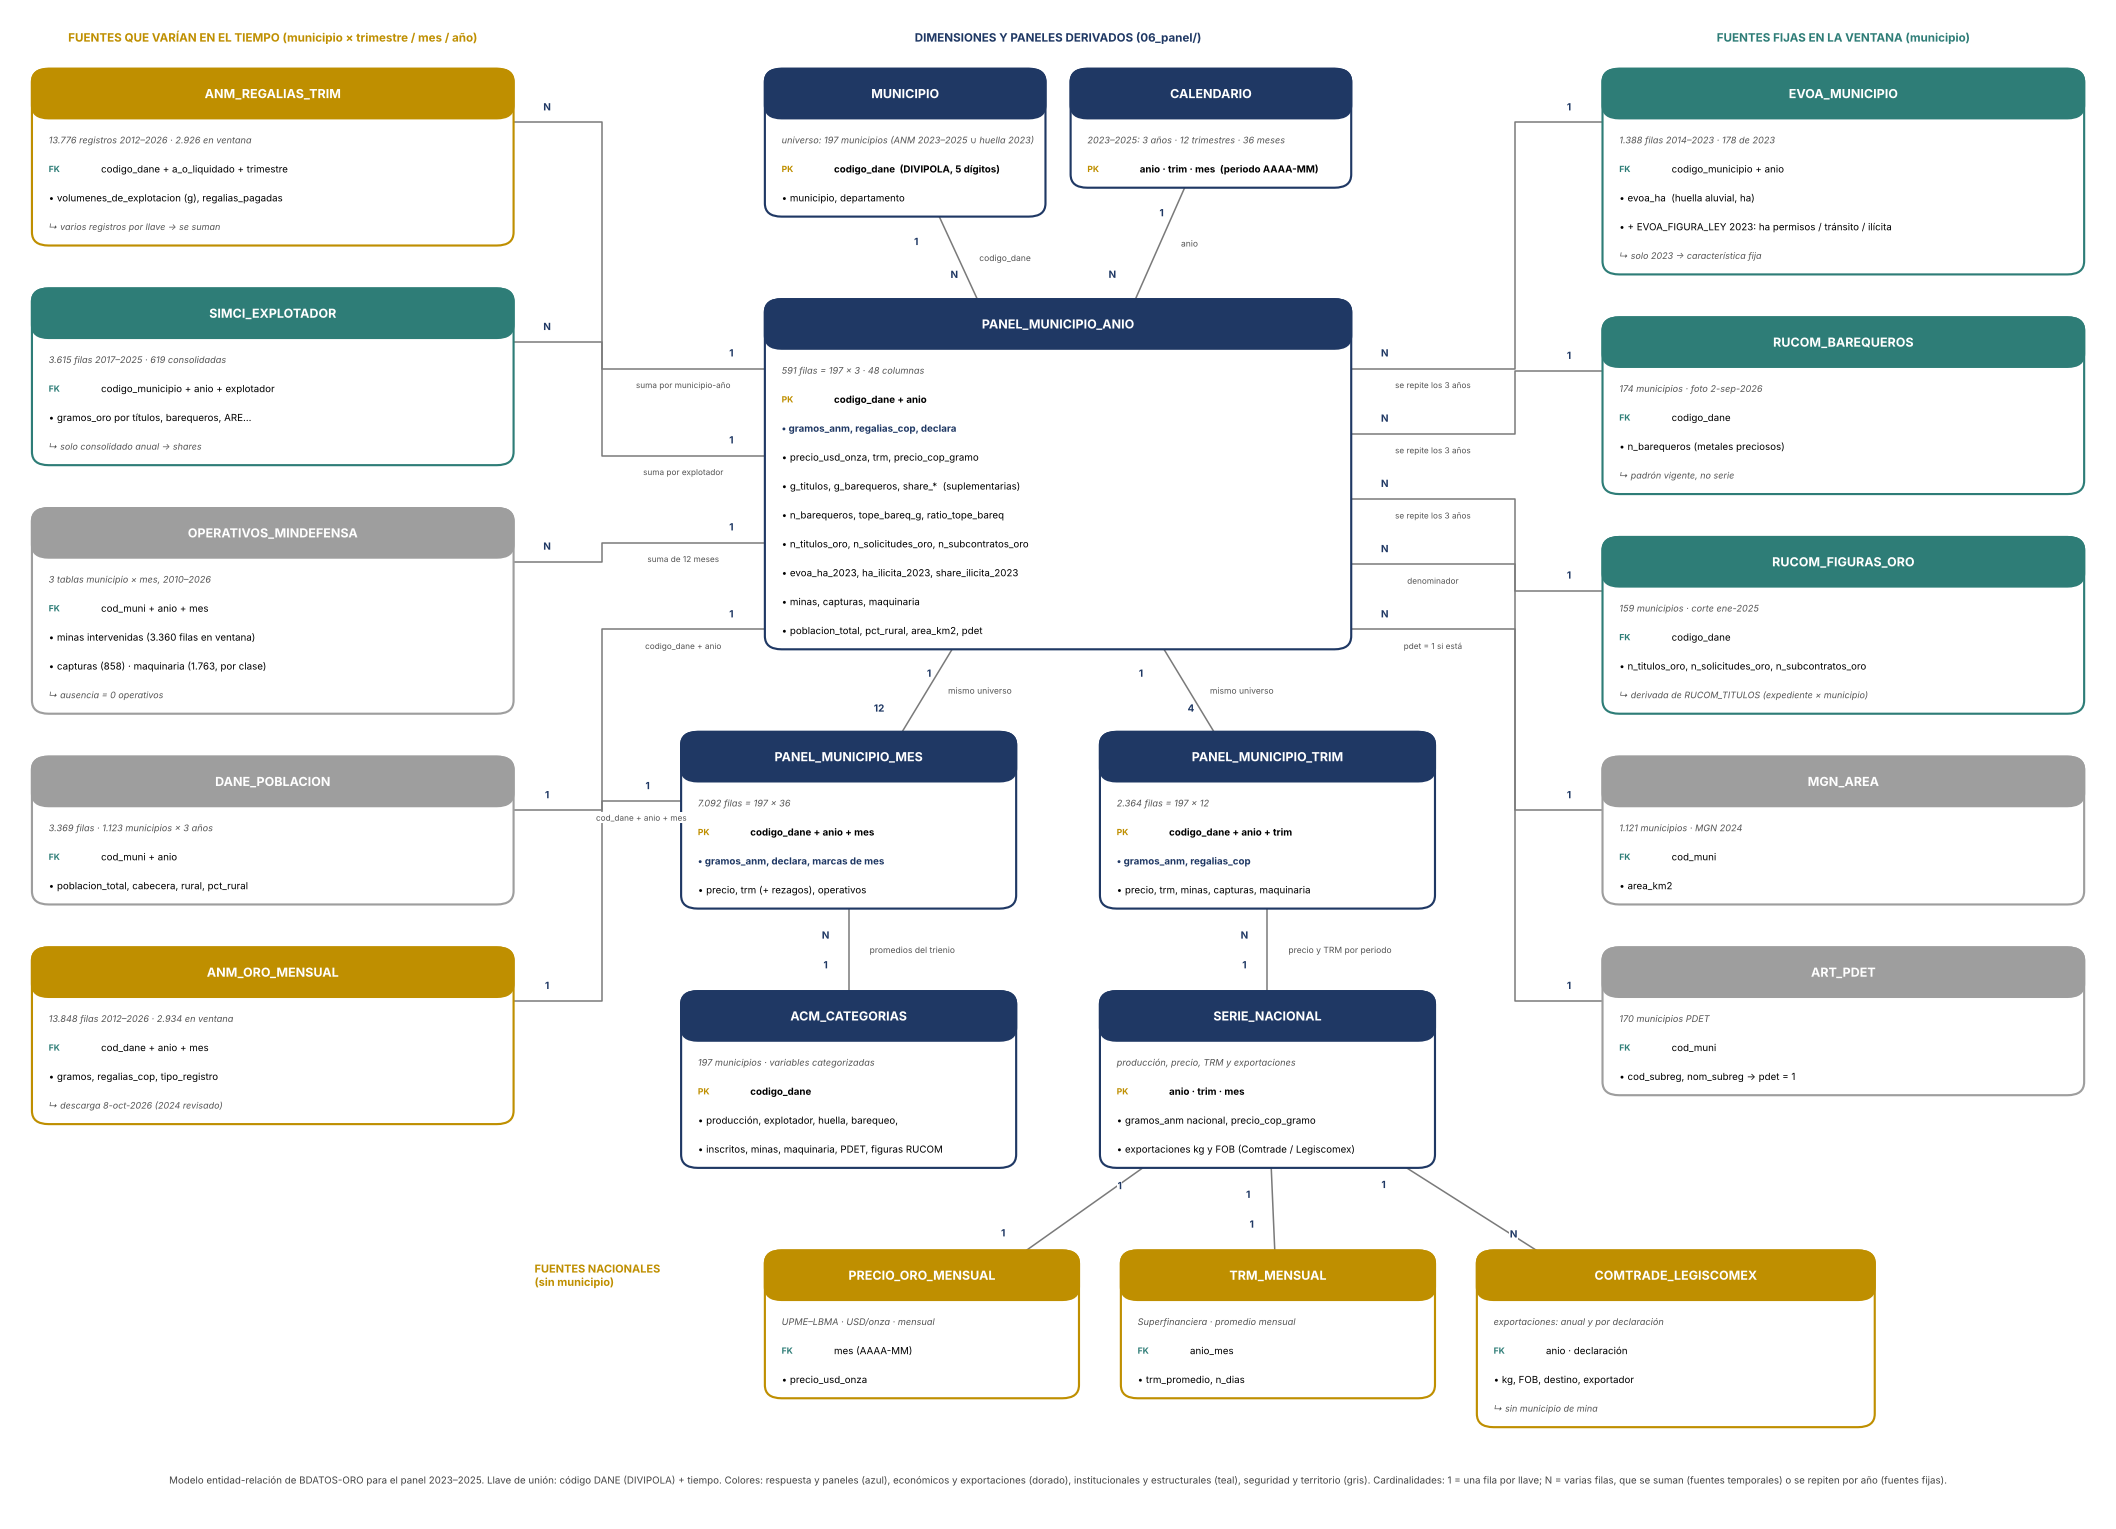

Figura guardada en /home/claude/jdnieto28-hub/tesis/07_figuras/fig_modelo_entidad_relacion_2023_2025.png
[OK     ] El diagrama entidad-relación incluye todas las tablas de la tabla de conexión (salvo UPME, que es solo control)


In [4]:
from matplotlib.patches import FancyBboxPatch

FIG_DIR = RAIZ / "07_figuras"; FIG_DIR.mkdir(exist_ok=True)
_c = conexion.set_index("tabla")

def _n(t, col="filas_en_ventana"):
    v = _c.loc[t, col]
    return f"{int(v):,}".replace(",", ".")

LINEA, CAB, GAP, GAP_CENTRO = 1.75, 3.0, 2.6, 5.0

def _alto(campos):
    return CAB + LINEA * (len(campos) + 1) + 0.7

ENTIDADES = {
    "MUNICIPIO": (AZUL, f"universo: {len(UNIVERSO)} municipios (ANM 2023–2025 ∪ huella 2023)", [("codigo_dane  (DIVIPOLA, 5 dígitos)", "pk"), ("municipio, departamento", "n")]),
    "CALENDARIO": (AZUL, "2023–2025: 3 años · 12 trimestres · 36 meses", [("anio · trim · mes  (periodo AAAA-MM)", "pk")]),
    "PANEL_MUNICIPIO_ANIO": (AZUL, f"{len(panel)} filas = 197 × 3 · 48 columnas", [
        ("codigo_dane + anio", "pk"), ("gramos_anm, regalias_cop, declara", "resp"), ("precio_usd_onza, trm, precio_cop_gramo", "n"),
        ("g_titulos, g_barequeros, share_*  (suplementarias)", "n"), ("n_barequeros, tope_bareq_g, ratio_tope_bareq", "n"), ("n_titulos_oro, n_solicitudes_oro, n_subcontratos_oro", "n"),
        ("evoa_ha_2023, ha_ilicita_2023, share_ilicita_2023", "n"), ("minas, capturas, maquinaria", "n"), ("poblacion_total, pct_rural, area_km2, pdet", "n")]),
    "PANEL_MUNICIPIO_MES": (AZUL, f"{len(panel_m):,} filas = 197 × 36".replace(",", "."), [("codigo_dane + anio + mes", "pk"), ("gramos_anm, declara, marcas de mes", "resp"), ("precio, trm (+ rezagos), operativos", "n")]),
    "PANEL_MUNICIPIO_TRIM": (AZUL, f"{len(pq):,} filas = 197 × 12".replace(",", "."), [("codigo_dane + anio + trim", "pk"), ("gramos_anm, regalias_cop", "resp"), ("precio, trm, minas, capturas, maquinaria", "n")]),
    "ACM_CATEGORIAS": (AZUL, "197 municipios · variables categorizadas", [("codigo_dane", "pk"), ("producción, explotador, huella, barequeo,", "n"), ("inscritos, minas, maquinaria, PDET, figuras RUCOM", "n")]),
    "SERIE_NACIONAL": (AZUL, "producción, precio, TRM y exportaciones", [("anio · trim · mes", "pk"), ("gramos_anm nacional, precio_cop_gramo", "n"), ("exportaciones kg y FOB (Comtrade / Legiscomex)", "n")]),
    "ANM_REGALIAS_TRIM": (DORADO, f"{_n('ANM_REGALIAS_TRIM', 'filas_archivo')} registros 2012–2026 · {_n('ANM_REGALIAS_TRIM')} en ventana", [("codigo_dane + a_o_liquidado + trimestre", "fk"), ("volumenes_de_explotacion (g), regalias_pagadas", "n"), ("varios registros por llave → se suman", "nota")]),
    "SIMCI_EXPLOTADOR": (TEAL, f"{_n('SIMCI_EXPLOTADOR', 'filas_archivo')} filas 2017–2025 · {_n('SIMCI_EXPLOTADOR')} consolidadas", [("codigo_municipio + anio + explotador", "fk"), ("gramos_oro por títulos, barequeros, ARE…", "n"), ("solo consolidado anual → shares", "nota")]),
    "OPERATIVOS_MINDEFENSA": (GRIS, "3 tablas municipio × mes, 2010–2026", [("cod_muni + anio + mes", "fk"), ("minas intervenidas (" + _n('OPERATIVOS_MINAS') + " filas en ventana)", "n"), ("capturas (" + _n('OPERATIVOS_CAPTURAS') + ") · maquinaria (" + _n('OPERATIVOS_MAQUINARIA') + ", por clase)", "n"), ("ausencia = 0 operativos", "nota")]),
    "DANE_POBLACION": (GRIS, f"{_n('DANE_POBLACION')} filas · 1.123 municipios × 3 años", [("cod_muni + anio", "fk"), ("poblacion_total, cabecera, rural, pct_rural", "n")]),
    "ANM_ORO_MENSUAL": (DORADO, f"{_n('ANM_ORO_MENSUAL', 'filas_archivo')} filas 2012–2026 · {_n('ANM_ORO_MENSUAL')} en ventana", [("cod_dane + anio + mes", "fk"), ("gramos, regalias_cop, tipo_registro", "n"), ("descarga 8-oct-2026 (2024 revisado)", "nota")]),
    "EVOA_MUNICIPIO": (TEAL, f"{_n('EVOA_MUNICIPIO', 'filas_archivo')} filas 2014–2023 · {_n('EVOA_MUNICIPIO')} de 2023", [("codigo_municipio + anio", "fk"), ("evoa_ha  (huella aluvial, ha)", "n"), ("+ EVOA_FIGURA_LEY 2023: ha permisos / tránsito / ilícita", "n"), ("solo 2023 → característica fija", "nota")]),
    "RUCOM_BAREQUEROS": (TEAL, f"{_n('RUCOM_BAREQUEROS')} municipios · foto 2-sep-2026", [("codigo_dane", "fk"), ("n_barequeros (metales preciosos)", "n"), ("padrón vigente, no serie", "nota")]),
    "RUCOM_FIGURAS_ORO": (TEAL, f"{_n('RUCOM_FIGURAS_ORO')} municipios · corte ene-2025", [("codigo_dane", "fk"), ("n_titulos_oro, n_solicitudes_oro, n_subcontratos_oro", "n"), ("derivada de RUCOM_TITULOS (expediente × municipio)", "nota")]),
    "MGN_AREA": (GRIS, f"{_n('MGN_AREA')} municipios · MGN 2024", [("cod_muni", "fk"), ("area_km2", "n")]),
    "ART_PDET": (GRIS, f"{_n('ART_PDET')} municipios PDET", [("cod_muni", "fk"), ("cod_subreg, nom_subreg → pdet = 1", "n")]),
    "PRECIO_ORO_MENSUAL": (DORADO, "UPME–LBMA · USD/onza · mensual", [("mes (AAAA-MM)", "fk"), ("precio_usd_onza", "n")]),
    "TRM_MENSUAL": (DORADO, "Superfinanciera · promedio mensual", [("anio_mes", "fk"), ("trm_promedio, n_dias", "n")]),
    "COMTRADE_LEGISCOMEX": (DORADO, "exportaciones: anual y por declaración", [("anio · declaración", "fk"), ("kg, FOB, destino, exportador", "n"), ("sin municipio de mina", "nota")]),
}
COLUMNAS = {  # (x, ancho, y_inicial, entidades de arriba hacia abajo)
    "izq": (1, 23, 96.5, ["ANM_REGALIAS_TRIM", "SIMCI_EXPLOTADOR", "OPERATIVOS_MINDEFENSA", "DANE_POBLACION", "ANM_ORO_MENSUAL"]),
    "der": (76, 23, 96.5, ["EVOA_MUNICIPIO", "RUCOM_BAREQUEROS", "RUCOM_FIGURAS_ORO", "MGN_AREA", "ART_PDET"]),
}
POS = {}
for x, w, y, nombres in COLUMNAS.values():
    for nm in nombres:
        POS[nm] = (x, y, w); y -= _alto(ENTIDADES[nm][2]) + GAP
POS["MUNICIPIO"] = (36, 96.5, 13.4); POS["CALENDARIO"] = (50.6, 96.5, 13.4)
y_panel = 96.5 - _alto(ENTIDADES["MUNICIPIO"][2]) - GAP_CENTRO; POS["PANEL_MUNICIPIO_ANIO"] = (36, y_panel, 28)
y_fila = y_panel - _alto(ENTIDADES["PANEL_MUNICIPIO_ANIO"][2]) - GAP_CENTRO
POS["PANEL_MUNICIPIO_MES"] = (32, y_fila, 16); POS["PANEL_MUNICIPIO_TRIM"] = (52, y_fila, 16)
y_fila2 = y_fila - _alto(ENTIDADES["PANEL_MUNICIPIO_MES"][2]) - GAP_CENTRO
POS["ACM_CATEGORIAS"] = (32, y_fila2, 16); POS["SERIE_NACIONAL"] = (52, y_fila2, 16)
y_nac = y_fila2 - _alto(ENTIDADES["SERIE_NACIONAL"][2]) - GAP_CENTRO
POS["PRECIO_ORO_MENSUAL"] = (36, y_nac, 15); POS["TRM_MENSUAL"] = (53, y_nac, 15); POS["COMTRADE_LEGISCOMEX"] = (70, y_nac, 19)
BUS_IZQ, BUS_DER = 28.2, 71.8   # ejes verticales por los que corren las uniones de las columnas laterales (estilo bus)
RELACIONES = [
    ("MUNICIPIO", "PANEL_MUNICIPIO_ANIO", "1", "N", "codigo_dane", "recta"), ("CALENDARIO", "PANEL_MUNICIPIO_ANIO", "1", "N", "anio", "recta"),
    ("PANEL_MUNICIPIO_ANIO", "PANEL_MUNICIPIO_MES", "1", "12", "mismo universo", "recta"), ("PANEL_MUNICIPIO_ANIO", "PANEL_MUNICIPIO_TRIM", "1", "4", "mismo universo", "recta"),
    ("PANEL_MUNICIPIO_MES", "ACM_CATEGORIAS", "N", "1", "promedios del trienio", "recta"), ("SERIE_NACIONAL", "PANEL_MUNICIPIO_TRIM", "1", "N", "precio y TRM por periodo", "recta"),
    ("ANM_REGALIAS_TRIM", "PANEL_MUNICIPIO_ANIO", "N", "1", "suma por municipio-año", "bus"), ("SIMCI_EXPLOTADOR", "PANEL_MUNICIPIO_ANIO", "N", "1", "suma por explotador", "bus"),
    ("OPERATIVOS_MINDEFENSA", "PANEL_MUNICIPIO_ANIO", "N", "1", "suma de 12 meses", "bus"), ("DANE_POBLACION", "PANEL_MUNICIPIO_ANIO", "1", "1", "codigo_dane + anio", "bus"),
    ("ANM_ORO_MENSUAL", "PANEL_MUNICIPIO_MES", "1", "1", "cod_dane + anio + mes", "bus"),
    ("EVOA_MUNICIPIO", "PANEL_MUNICIPIO_ANIO", "1", "N", "se repite los 3 años", "bus"), ("RUCOM_BAREQUEROS", "PANEL_MUNICIPIO_ANIO", "1", "N", "se repite los 3 años", "bus"),
    ("RUCOM_FIGURAS_ORO", "PANEL_MUNICIPIO_ANIO", "1", "N", "se repite los 3 años", "bus"), ("MGN_AREA", "PANEL_MUNICIPIO_ANIO", "1", "N", "denominador", "bus"), ("ART_PDET", "PANEL_MUNICIPIO_ANIO", "1", "N", "pdet = 1 si está", "bus"),
    ("PRECIO_ORO_MENSUAL", "SERIE_NACIONAL", "1", "1", "", "recta"), ("TRM_MENSUAL", "SERIE_NACIONAL", "1", "1", "", "recta"), ("COMTRADE_LEGISCOMEX", "SERIE_NACIONAL", "N", "1", "", "recta"),
]

def _caja(ax, nombre, x, y, w, color, sub, campos):
    h = _alto(campos); y0 = y - h
    ax.add_patch(FancyBboxPatch((x, y0), w, h, boxstyle="round,pad=0,rounding_size=0.8", fc="white", ec=color, lw=1.4, zorder=3))
    ax.add_patch(FancyBboxPatch((x, y - CAB), w, CAB, boxstyle="round,pad=0,rounding_size=0.8", fc=color, ec=color, lw=1.4, zorder=4))
    ax.text(x + w / 2, y - CAB / 2, nombre, ha="center", va="center", color="white", fontsize=8.2, fontweight="bold", zorder=5)
    ax.text(x + 0.8, y - CAB - LINEA * 0.75, sub, fontsize=6.0, color="#555555", style="italic", va="center", zorder=5)
    for k, (txt, tipo) in enumerate(campos, start=2):
        yy = y - CAB - LINEA * (k - 0.25)
        if tipo in ("pk", "fk"):
            ax.text(x + 0.8, yy, "PK" if tipo == "pk" else "FK", fontsize=5.6, fontweight="bold", color=DORADO if tipo == "pk" else TEAL, va="center", zorder=5)
            ax.text(x + 3.3, yy, txt, fontsize=6.4, va="center", zorder=5, fontweight="bold" if tipo == "pk" else "normal")
        elif tipo == "resp":
            ax.text(x + 0.8, yy, "• " + txt, fontsize=6.4, va="center", zorder=5, color=AZUL, fontweight="bold")
        elif tipo == "nota":
            ax.text(x + 0.8, yy, "↳ " + txt, fontsize=5.9, va="center", zorder=5, color="#555555", style="italic")
        else:
            ax.text(x + 0.8, yy, "• " + txt, fontsize=6.4, va="center", zorder=5)
    return (x, y0, w, h)

def _borde(caja, hacia):
    x, y0, w, h = caja; cx, cy = x + w / 2, y0 + h / 2; tx, ty = hacia
    dx, dy = tx - cx, ty - cy
    if abs(dx) * h > abs(dy) * w:   # sale por un lado
        return (x + w if dx > 0 else x, cy + dy * (w / 2) / abs(dx) if dx else cy)
    return (cx + dx * (h / 2) / abs(dy) if dy else cx, y0 + h if dy > 0 else y0)

fig, ax = plt.subplots(figsize=(20, 14)); ax.set_xlim(0, 100); ax.set_ylim(y_nac - _alto(ENTIDADES["COMTRADE_LEGISCOMEX"][2]) - 5.5, 100); ax.axis("off"); ax.grid(False)
cajas = {n: _caja(ax, n, POS[n][0], POS[n][1], POS[n][2], *v) for n, v in ENTIDADES.items()}

def _card(ax, p, q, txt):
    vx, vy = q[0] - p[0], q[1] - p[1]; nrm = (vx ** 2 + vy ** 2) ** 0.5 or 1; ux, uy = vx / nrm, vy / nrm
    pos = (p[0] - 1.1, p[1] + uy * 1.6) if abs(uy) >= 0.3 else (p[0] + ux * 1.6, p[1] + 0.95)
    ax.text(*pos, txt, fontsize=6.5, color=AZUL, fontweight="bold", ha="center", va="center", zorder=6, bbox=dict(fc="white", ec="none", pad=0.25))

destinos_bus = {}
for o, d, co, cd, et, ruta in RELACIONES:
    if ruta == "bus":
        destinos_bus.setdefault((d, "izq" if POS[o][0] < 50 else "der"), []).append(o)
y_destino = {}
for (d, lado), origenes in destinos_bus.items():
    x, y0, w, h = cajas[d]; k = len(origenes)
    for r, o in enumerate(origenes):
        y_destino[o] = y0 + h - CAB - 1.2 - (h - CAB - 2.4) * (r / max(k - 1, 1))
for o, d, co, cd, et, ruta in RELACIONES:
    bo, bd = cajas[o], cajas[d]
    if ruta == "recta":
        p1 = _borde(bo, (bd[0] + bd[2] / 2, bd[1] + bd[3] / 2)); p2 = _borde(bd, (bo[0] + bo[2] / 2, bo[1] + bo[3] / 2))
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color="#7a7a7a", lw=1.0, zorder=1)
        if et:
            vx, vy = p2[0] - p1[0], p2[1] - p1[1]; nrm = (vx ** 2 + vy ** 2) ** 0.5 or 1
            vert = abs(vy / nrm) >= 0.3
            ax.text((p1[0] + p2[0]) / 2 + (1.0 if vert else 0), (p1[1] + p2[1]) / 2 + (0 if vert else 0.95), et, fontsize=5.6, color="#555555", ha="left" if vert else "center", va="center", zorder=6, bbox=dict(fc="white", ec="none", pad=0.25))
    else:
        izq = POS[o][0] < 50; bus = BUS_IZQ if izq else BUS_DER
        p1 = (bo[0] + bo[2] if izq else bo[0], bo[1] + bo[3] - CAB / 2 - LINEA)   # sale por el costado, a la altura del subtítulo
        p2 = (bd[0] if izq else bd[0] + bd[2], y_destino[o])
        ax.plot([p1[0], bus, bus, p2[0]], [p1[1], p1[1], p2[1], p2[1]], color="#7a7a7a", lw=1.0, zorder=1, solid_joinstyle="round")
        if et:
            ax.text((bus + p2[0]) / 2, p2[1] - 1.0, et, fontsize=5.4, color="#555555", ha="center", va="center", zorder=6, bbox=dict(fc="white", ec="none", pad=0.25))
        p2 = (p2[0], p2[1]); p1 = (p1[0], p1[1])
        _card(ax, p1, (bus, p1[1]), co); _card(ax, p2, (bus, p2[1]), cd); continue
    _card(ax, p1, p2, co); _card(ax, p2, p1, cd)
for xx, txt, col in [(12.5, "FUENTES QUE VARÍAN EN EL TIEMPO (municipio × trimestre / mes / año)", DORADO), (50, "DIMENSIONES Y PANELES DERIVADOS (06_panel/)", AZUL), (87.5, "FUENTES FIJAS EN LA VENTANA (municipio)", TEAL)]:
    ax.text(xx, 98.4, txt, ha="center", va="center", fontsize=7.6, fontweight="bold", color=col)
ax.text(25, y_nac - CAB / 2, "FUENTES NACIONALES\n(sin municipio)", ha="left", va="center", fontsize=7.2, fontweight="bold", color=DORADO)
ax.text(50, y_nac - _alto(ENTIDADES["COMTRADE_LEGISCOMEX"][2]) - 3.2, "Modelo entidad-relación de BDATOS-ORO para el panel 2023–2025. Llave de unión: código DANE (DIVIPOLA) + tiempo. Colores: respuesta y paneles (azul), económicos y exportaciones (dorado), "
        "institucionales y estructurales (teal), seguridad y territorio (gris). Cardinalidades: 1 = una fila por llave; N = varias filas, que se suman (fuentes temporales) o se repiten por año (fuentes fijas).",
        ha="center", va="center", fontsize=6.4, color="#444444", wrap=True)
plt.tight_layout(); fig.savefig(FIG_DIR / "fig_modelo_entidad_relacion_2023_2025.png", dpi=200, bbox_inches="tight"); plt.show()
print("Figura guardada en", FIG_DIR / "fig_modelo_entidad_relacion_2023_2025.png")
check("Conexión", "El diagrama entidad-relación incluye todas las tablas de la tabla de conexión (salvo UPME, que es solo control)", set(_c.index) - {"UPME_PRECIO_BASE", "OPERATIVOS_MINAS", "OPERATIVOS_CAPTURAS", "OPERATIVOS_MAQUINARIA", "EVOA_FIGURA_LEY", "COMTRADE_7108_ANUAL"} <= set(ENTIDADES))

## 2. Homicidio y extorsión: validación de la fuente y Spearman de las tasas con el panel (quedan fuera)

== homicidio: (11720, 6)


,tipo,n_no_nulos,pct_nulos,n_unicos,ejemplo
cod_muni,str,11720,0.00,974,05001
departamento,str,11720,0.00,33,ANTIOQUIA
municipio,str,11720,0.00,906,MEDELLIN
anio,int64,11720,0.00,3,2023
mes,int64,11720,0.00,12,1
casos,int64,11720,0.00,89,28


[OK     ] homicidio: código DANE de 5 dígitos con departamento válido
[OK     ] homicidio: sin duplicados municipio-año-mes; casos enteros no negativos
[OK     ] homicidio: los tres años traen 12 meses — {2023: 12, 2024: 12, 2025: 12}
[OK     ] homicidio: la descarga completa reproduce el total de la fuente (ficha) — 344,919 casos en la fuente
[OK     ] homicidio: un solo nombre de municipio por código
Nacional por año: {2023: 13555, 2024: 13497, 2025: 14038} | municipios con algún caso: 974
== extorsion: (9578, 6)


,tipo,n_no_nulos,pct_nulos,n_unicos,ejemplo
cod_muni,str,9578,0.00,974,05001
departamento,str,9578,0.00,33,ANTIOQUIA
municipio,str,9578,0.00,910,MEDELLIN
anio,int64,9578,0.00,3,2023
mes,int64,9578,0.00,12,1
casos,int64,9578,0.00,123,83


[OK     ] extorsion: código DANE de 5 dígitos con departamento válido
[OK     ] extorsion: sin duplicados municipio-año-mes; casos enteros no negativos
[OK     ] extorsion: los tres años traen 12 meses — {2023: 12, 2024: 12, 2025: 12}
[OK     ] extorsion: la descarga completa reproduce el total de la fuente (ficha) — 131,206 casos en la fuente
[OK     ] extorsion: un solo nombre de municipio por código
Nacional por año: {2023: 11078, 2024: 13802, 2025: 13417} | municipios con algún caso: 974
homicidio: 190 de 197 municipios del universo tienen algún caso en 2023–2025; municipio-años con casos: 525 de 591
extorsion: 187 de 197 municipios del universo tienen algún caso en 2023–2025; municipio-años con casos: 500 de 591


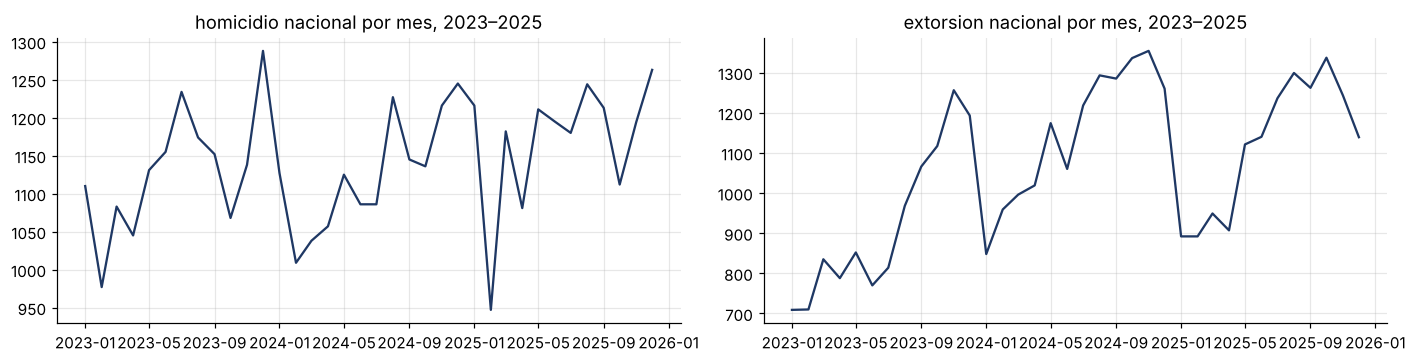

Spearman de las tasas con las variables del panel (591 municipio-años):


,gramos_anm,g_titulos,g_barequeros,evoa_ha_2023,minas,capturas,maquinaria,pct_rural
tasa_homicidio_10k,0.07,0.15,0.00,0.21,0.05,0.06,0.17,-0.13
tasa_extorsion_10k,0.06,0.14,-0.03,-0.09,0.15,0.13,0.13,-0.39


Municipios del universo sin ninguna extorsión registrada en tres años: 5 %; sin ningún homicidio: 4 %
[OK     ] Decisión: homicidio y extorsión no se asocian con la producción declarada (|Spearman| < 0,20) y no entran al panel — máx |r| con gramos = 0.07


In [5]:
delic = {}
for nombre in ["homicidio", "extorsion"]:
    d = pd.read_csv(RAIZ / f"05_delictiva/{nombre}_municipal_mensual_2023_2025.csv", dtype={"cod_muni": str})
    print(f"== {nombre}: {d.shape}"); display(perfil(d))
    check("05 Delictiva", f"{nombre}: código DANE de 5 dígitos con departamento válido", (d.cod_muni.str.len() == 5).all() and d.cod_muni.str[:2].isin(DEPTOS).all())
    check("05 Delictiva", f"{nombre}: sin duplicados municipio-año-mes; casos enteros no negativos", not d.duplicated(["cod_muni", "anio", "mes"]).any() and (d.casos >= 0).all() and (d.casos == d.casos.round()).all())
    check("05 Delictiva", f"{nombre}: los tres años traen 12 meses", all(d.loc[d.anio == a, "mes"].nunique() == 12 for a in ANIOS), {a: int(d.loc[d.anio == a, 'mes'].nunique()) for a in ANIOS})
    check("05 Delictiva", f"{nombre}: la descarga completa reproduce el total de la fuente (ficha)", ficha[nombre]["coincide"], f"{ficha[nombre]['total_fuente_sum_cantidad']:,} casos en la fuente")
    check("05 Delictiva", f"{nombre}: un solo nombre de municipio por código", (d.groupby("cod_muni").municipio.nunique() == 1).all())
    nac = d.groupby("anio").casos.sum(); print("Nacional por año:", nac.to_dict(), "| municipios con algún caso:", d.cod_muni.nunique())
    delic[nombre] = d
for nombre, d in delic.items():
    en_uni = d[d.cod_muni.isin(UNIVERSO)]
    print(f"{nombre}: {en_uni.cod_muni.nunique()} de {len(UNIVERSO)} municipios del universo tienen algún caso en 2023–2025; municipio-años con casos: {en_uni.groupby(['cod_muni','anio']).size().shape[0]} de {len(UNIVERSO) * 3}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for a, (nombre, d) in zip(ax, delic.items()):
    m = d.groupby(["anio", "mes"]).casos.sum().reset_index(); m["fecha"] = pd.to_datetime(dict(year=m.anio, month=m.mes, day=1))
    a.plot(m.fecha, m.casos, color=AZUL); a.set_title(f"{nombre} nacional por mes, 2023–2025")
plt.tight_layout(); plt.show()

pob_ev = pd.read_csv(RAIZ / "11_poblacion/dane_poblacion_municipal_2023_2025.csv", dtype={"cod_muni": str}).rename(columns={"cod_muni": "codigo_dane"})
ev = panel[["codigo_dane", "anio", "gramos_anm", "g_titulos", "g_barequeros", "evoa_ha_2023", "minas", "capturas", "maquinaria"]].merge(pob_ev[["codigo_dane", "anio", "poblacion_total", "pct_rural"]], on=["codigo_dane", "anio"], how="left")
for nombre, d in delic.items():
    a = d.rename(columns={"cod_muni": "codigo_dane"}).groupby(["codigo_dane", "anio"]).casos.sum().rename(nombre).reset_index()
    ev = ev.merge(a, on=["codigo_dane", "anio"], how="left"); ev[nombre] = ev[nombre].fillna(0)
    ev[f"tasa_{nombre}_10k"] = ev[nombre] / ev.poblacion_total * 1e4
cols_ev = ["gramos_anm", "g_titulos", "g_barequeros", "evoa_ha_2023", "minas", "capturas", "maquinaria", "pct_rural"]
corr_ev = ev[["tasa_homicidio_10k", "tasa_extorsion_10k"] + cols_ev].corr(method="spearman").loc[["tasa_homicidio_10k", "tasa_extorsion_10k"], cols_ev]
print("Spearman de las tasas con las variables del panel (591 municipio-años):"); display(corr_ev.round(2))
sin_ext = (ev.groupby("codigo_dane").extorsion.sum() == 0).mean() * 100; sin_hom = (ev.groupby("codigo_dane").homicidio.sum() == 0).mean() * 100
print(f"Municipios del universo sin ninguna extorsión registrada en tres años: {sin_ext:.0f} %; sin ningún homicidio: {sin_hom:.0f} %")
r_g = corr_ev.loc[:, "gramos_anm"].abs().max()
check("05 Delictiva", "Decisión: homicidio y extorsión no se asocian con la producción declarada (|Spearman| < 0,20) y no entran al panel", r_g < 0.20, f"máx |r| con gramos = {r_g:.2f}")

## 3. Población DANE: validación, descriptivas e inscritos RUCOM por 100 habitantes

In [6]:
pob = pd.read_csv(RAIZ / "11_poblacion/dane_poblacion_municipal_2023_2025.csv", dtype={"cod_muni": str})
display(perfil(pob))
check("11 Población", "Código de 5 dígitos, sin duplicados municipio-año, tres años por municipio", (pob.cod_muni.str.len() == 5).all() and not pob.duplicated(["cod_muni", "anio"]).any() and (pob.groupby("cod_muni").anio.nunique() == 3).all())
check("11 Población", "Cabecera + rural = total en todas las filas", ((pob.poblacion_cabecera + pob.poblacion_rural - pob.poblacion_total).abs() <= 1).all())
check("11 Población", "Todos los municipios del panel tienen población en los tres años", set(UNIVERSO) <= set(pob.cod_muni), f"faltan: {sorted(set(UNIVERSO) - set(pob.cod_muni))}")
print("Población nacional por año:", pob.groupby("anio").poblacion_total.sum().astype(int).to_dict())
pu = pob[pob.cod_muni.isin(UNIVERSO)]
display(tabla_resumen(pu, ["poblacion_total", "pct_rural"]))
rb = panel.drop_duplicates("codigo_dane")[["codigo_dane", "municipio", "n_barequeros"]].merge(pob[pob.anio == 2024][["cod_muni", "poblacion_total"]], left_on="codigo_dane", right_on="cod_muni")
rb["inscritos_por_100_hab"] = rb.n_barequeros / rb.poblacion_total * 100
print("Municipios con más inscritos por cada 100 habitantes (2024):"); display(rb.nlargest(8, "inscritos_por_100_hab")[["codigo_dane", "municipio", "n_barequeros", "poblacion_total", "inscritos_por_100_hab"]])

,tipo,n_no_nulos,pct_nulos,n_unicos,ejemplo
cod_muni,str,3369,0.00,1123,05001
departamento,str,3369,0.00,33,Antioquia
municipio,str,3369,0.00,1040,Medellín
anio,int64,3369,0.00,3,2023
poblacion_total,float64,3369,0.00,3221,"2,518,480.00"
poblacion_cabecera,float64,3369,0.00,2977,"2,469,958.00"
poblacion_rural,float64,3369,0.00,3086,"48,522.00"
pct_rural,float64,3365,0.12,2718,1.93


[OK     ] Código de 5 dígitos, sin duplicados municipio-año, tres años por municipio
[OK     ] Cabecera + rural = total en todas las filas
[OK     ] Todos los municipios del panel tienen población en los tres años — faltan: []
Población nacional por año: {2023: 52117067, 2024: 52613753, 2025: 53057212}


,n,nulos,ceros,media,desv_est,cv,min,p5,p25,mediana,p75,p95,max,asimetria,curtosis
poblacion_total,591.00,0.00,1.00,"54,743.47","194,120.67",3.55,0.00,"5,156.50","11,095.50","19,624.00","37,926.50","144,430.00","2,528,343.00",10.81,132.18
pct_rural,590.00,1.00,0.00,54.63,23.35,0.43,1.92,12.37,38.51,55.86,73.04,91.21,100.00,-0.26,-0.73


Municipios con más inscritos por cada 100 habitantes (2024):


,codigo_dane,municipio,n_barequeros,poblacion_total,inscritos_por_100_hab
138,27810,Union Panamericana,"9,386.00","7,202.00",130.32
124,27413,Lloro,"8,077.00","10,316.00",78.30
17,05154,Caucasia,"29,209.00","93,572.00",31.22
113,23682,San Jose de Ure,"4,716.00","15,244.00",30.94
127,27450,Medio San Juan,"2,955.00","11,112.00",26.59
119,27160,Certegui,"1,519.00","5,986.00",25.38
118,27135,El Canton del San Pablo,"1,623.00","6,486.00",25.02
116,27050,Atrato,609.00,"6,409.00",9.50


## 4. Figuras de oro del RUCOM y anotaciones del RMN: validación y cruce con los gramos por títulos

In [7]:
tit = pd.read_csv(RAIZ / "12_titulos_rucom/rucom_titulos_oro.csv", dtype=str)
sol = pd.read_csv(RAIZ / "12_titulos_rucom/rucom_solicitudes_legalizacion_oro.csv", dtype=str)
sub = pd.read_csv(RAIZ / "12_titulos_rucom/rucom_subcontratos_formalizacion_oro.csv", dtype=str)
fig_m = pd.read_csv(RAIZ / "12_titulos_rucom/rucom_figuras_oro_municipio.csv", dtype={"codigo_dane": str})
an = pd.read_csv(RAIZ / "12_titulos_rucom/rmn_anotaciones_titulos_2023_2025.csv", dtype=str)
for nombre, d in [("títulos", tit), ("solicitudes", sol), ("subcontratos", sub)]:
    print(f"== {nombre}: {len(d)} filas, {d.codigo_expediente.nunique()} expedientes, {d.codigo_dane.nunique()} municipios; minerales: {d.mineral.value_counts().to_dict()}")
    check("12 RUCOM", f"{nombre}: código DANE de 5 dígitos con departamento válido", (d.codigo_dane.str.len() == 5).all() and d.codigo_dane.str[:2].isin(DEPTOS).all())
    if d.duplicated().any():
        print(f"     {d.duplicated().sum()} filas idénticas repetidas en la fuente (no afectan: los conteos usan expedientes únicos)")
print("\nUn mismo expediente puede cubrir varios municipios (una fila por municipio y mineral):")
display(tit.groupby("codigo_expediente").codigo_dane.nunique().value_counts().sort_index().rename("expedientes").to_frame().T)
display(perfil(fig_m))
check("12 RUCOM", "Tabla por municipio: una fila por municipio, conteos enteros no negativos", not fig_m.codigo_dane.duplicated().any() and (fig_m.drop(columns="codigo_dane") >= 0).all().all())

an["fecha"] = pd.to_datetime(an.fecha, errors="coerce"); an["anio"] = an.fecha.dt.year
print("\nAnotaciones RMN en la ventana:", len(an), "| por año:", an.anio.value_counts().sort_index().to_dict(), "| expedientes:", an.codigo_expediente.nunique())
print("Tipos de anotación más frecuentes:"); display(an.tipo_de_anotacion.value_counts().head(8))
con_an = tit.codigo_expediente.isin(an.codigo_expediente)
check("12 RUCOM", "Los títulos de oro del RUCOM tienen anotación registral en 2023–2025 (≥ 95 %)", con_an.groupby(tit.codigo_expediente).any().mean() >= 0.95, f"{con_an.groupby(tit.codigo_expediente).any().mean()*100:.1f} % de los expedientes")

decl = panel.groupby("codigo_dane")[["g_titulos", "g_barequeros", "g_otros", "gramos_anm"]].sum().reset_index()
x = decl.merge(fig_m, on="codigo_dane", how="outer").fillna(0)
x_uni = x[x.codigo_dane.isin(UNIVERSO)]
a = ((x_uni.g_titulos > 0) & (x_uni.n_titulos_oro > 0)).sum(); b = (x_uni.g_titulos > 0).sum(); c = ((x_uni.g_titulos == 0) & (x_uni.n_titulos_oro > 0)).sum()
print(f"\nMunicipios del universo que declaran gramos por títulos: {b}; de ellos con al menos un título de oro autorizado en el RUCOM: {a} ({a/b*100:.0f} %)")
print(f"Municipios con título autorizado y sin gramos por títulos en 2023–2025: {c}")
check("12 RUCOM", "Al menos el 70 % de los municipios que declaran por títulos tienen un título de oro autorizado en el RUCOM", a / b >= 0.70, f"{a/b*100:.0f} %")
fuera = fig_m[~fig_m.codigo_dane.isin(UNIVERSO)]
print(f"Municipios con alguna figura de oro autorizada fuera del universo del panel: {len(fuera)} (no declaran ni tienen huella 2023)")
display(tabla_resumen(x_uni, ["n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro", "n_titulos_oro_con_anotacion_2023_2025"]))

== títulos: 1509 filas, 268 expedientes, 124 municipios; minerales: {'MINERALES DE ORO Y SUS CONCENTRADOS': 569, 'ORO': 549, 'ORO ALUVION': 266, 'MINERALES DE ORO Y PLATINO, Y SUS CONCENTRADOS': 71, 'ORO VETA': 52, 'ORO FILON': 2}
[OK     ] títulos: código DANE de 5 dígitos con departamento válido
== solicitudes: 912 filas, 112 expedientes, 70 municipios; minerales: {'MINERALES DE ORO Y SUS CONCENTRADOS': 806, 'MINERALES DE ORO Y PLATINO, Y SUS CONCENTRADOS': 105, 'ORO': 1}
[OK     ] solicitudes: código DANE de 5 dígitos con departamento válido
     619 filas idénticas repetidas en la fuente (no afectan: los conteos usan expedientes únicos)
== subcontratos: 201 filas, 174 expedientes, 45 municipios; minerales: {'MINERALES DE ORO Y SUS CONCENTRADOS': 95, 'ORO': 65, 'MINERALES DE ORO Y PLATINO, Y SUS CONCENTRADOS': 41}
[OK     ] subcontratos: código DANE de 5 dígitos con departamento válido

Un mismo expediente puede cubrir varios municipios (una fila por municipio y mineral):


codigo_dane,1,2,3,4,7
expedientes,204,50,12,1,1


,tipo,n_no_nulos,pct_nulos,n_unicos,ejemplo
codigo_dane,str,159,0.00,159,05004
n_titulos_oro,int64,159,0.00,14,1
n_titulares_titulos_oro,int64,159,0.00,26,3
n_solicitudes_oro,int64,159,0.00,8,0
n_titulares_solicitudes_oro,int64,159,0.00,14,0
n_subcontratos_oro,int64,159,0.00,15,0
n_titulares_subcontratos_oro,int64,159,0.00,16,0
n_titulos_oro_con_anotacion_2023_2025,int64,159,0.00,30,3


[OK     ] Tabla por municipio: una fila por municipio, conteos enteros no negativos

Anotaciones RMN en la ventana: 12988 | por año: {2023: 7598, 2024: 1410, 2025: 3980} | expedientes: 6762
Tipos de anotación más frecuentes:


tipo_de_anotacion
ACLARACION/MODIFICACION DE TITULO              6750
APROBACIÓN INSTRUMENTO TÉCNICO                 2706
SUSPENSION POR FUERZA MAYOR O CASO FORTUITO     959
CESION  DE DERECHOS                             374
ACLARACIÓN ANOTACIÓN                            302
SUBCONTRATO DE FORMALIZACIÓN                    275
ACLARACION DE NOMBRES/RAZON SOCIAL              217
AUTORIZACION TEMPORAL                           191
Name: count, dtype: int64

[OK     ] Los títulos de oro del RUCOM tienen anotación registral en 2023–2025 (≥ 95 %) — 99.6 % de los expedientes

Municipios del universo que declaran gramos por títulos: 80; de ellos con al menos un título de oro autorizado en el RUCOM: 71 (89 %)
Municipios con título autorizado y sin gramos por títulos en 2023–2025: 29
[OK     ] Al menos el 70 % de los municipios que declaran por títulos tienen un título de oro autorizado en el RUCOM — 89 %
Municipios con alguna figura de oro autorizada fuera del universo del panel: 37 (no declaran ni tienen huella 2023)


,n,nulos,ceros,media,desv_est,cv,min,p5,p25,mediana,p75,p95,max,asimetria,curtosis
n_titulos_oro,197.00,0.00,97.00,1.61,3.16,1.96,0.00,0.00,0.00,1.00,2.00,7.00,26.00,4.33,25.10
n_solicitudes_oro,197.00,0.00,141.00,0.60,1.48,2.48,0.00,0.00,0.00,0.00,1.00,3.00,15.00,5.63,46.51
n_subcontratos_oro,197.00,0.00,155.00,0.94,2.72,2.90,0.00,0.00,0.00,0.00,0.00,6.00,18.00,3.98,17.34
n_titulos_oro_con_anotacion_2023_2025,197.00,0.00,98.00,6.69,27.68,4.14,0.00,0.00,0.00,1.00,4.00,23.20,353.00,10.51,127.13


## 5. Área MGN 2024 y municipios PDET: validación y cobertura del universo

In [8]:
area = pd.read_csv(RAIZ / "13_territorio/mgn_area_municipal_km2.csv", dtype={"cod_muni": str})
pdet = pd.read_csv(RAIZ / "13_territorio/municipios_pdet.csv", dtype={"cod_muni": str})
check("13 Territorio", "Área: una fila por municipio, área positiva, suma cercana al área continental de Colombia (1,14 millones de km²)", not area.cod_muni.duplicated().any() and (area.area_km2 > 0).all() and abs(area.area_km2.sum() - 1_141_748) / 1_141_748 < 0.01, f"suma = {area.area_km2.sum():,.0f} km²")
check("13 Territorio", "Todos los municipios del panel tienen área", set(UNIVERSO) <= set(area.cod_muni), f"faltan: {sorted(set(UNIVERSO) - set(area.cod_muni))}")
check("13 Territorio", "PDET: 170 municipios con código válido y sin duplicados", len(pdet) == 170 and not pdet.cod_muni.duplicated().any() and pdet.cod_muni.str[:2].isin(DEPTOS).all())
print(f"Municipios PDET dentro del universo del panel: {pdet.cod_muni.isin(UNIVERSO).sum()} de 170 ({pdet.cod_muni.isin(UNIVERSO).sum()/len(UNIVERSO)*100:.0f} % del universo)")
print("Subregiones PDET con más municipios del universo:"); display(pdet[pdet.cod_muni.isin(UNIVERSO)].nom_subreg.value_counts().head(6))
nm = panel.drop_duplicates("codigo_dane")[["codigo_dane", "municipio"]].merge(area, left_on="codigo_dane", right_on="cod_muni")
dif = nm[[not (normaliza(a).startswith(normaliza(b)) or normaliza(b).startswith(normaliza(a))) for a, b in zip(nm.municipio, nm.municipio_mgn)]]
check("13 Territorio", "Nombres del MGN coherentes con los del panel para el mismo código", len(dif) == 0, f"{len(dif)} distintos: {dif[['codigo_dane', 'municipio', 'municipio_mgn']].values.tolist()[:5]}")

[OK     ] Área: una fila por municipio, área positiva, suma cercana al área continental de Colombia (1,14 millones de km²) — suma = 1,140,974 km²
[REVISAR] Todos los municipios del panel tienen área — faltan: ['27493']
[OK     ] PDET: 170 municipios con código válido y sin duplicados
Municipios PDET dentro del universo del panel: 66 de 170 (34 % del universo)
Subregiones PDET con más municipios del universo:


nom_subreg
BAJO CAUCA Y NORDESTE ANTIOQUEÑO    12
CHOCÓ                               11
SUR DE BOLÍVAR                       6
ALTO PATÍA Y NORTE DEL CAUCA         6
PACÍFICO Y FRONTERA NARIÑENSE        6
PUTUMAYO                             6
Name: count, dtype: int64

[REVISAR] Nombres del MGN coherentes con los del panel para el mismo código — 2 distintos: [['23670', 'San Andres Sotavento', 'SAN ANDRÉS DE SOTAVENTO'], ['73443', 'Mariquita', 'SAN SEBASTIÁN DE MARIQUITA']]


## 6. Precio base UPME 2025: cociente con el precio internacional y tasa implícita de regalía

In [9]:
pb = pd.read_csv(RAIZ / "01_precio/upme_precio_base_regalias_opp_mensual_2025.csv")
precio = pd.read_csv(RAIZ / "01_precio/precio_oro_mensual_usd_onza.csv"); trm = pd.read_csv(RAIZ / "01_precio/trm_mensual_promedio.csv")
pm = precio.merge(trm[["anio_mes", "trm_promedio"]], left_on="mes", right_on="anio_mes"); pm["precio_cop_gramo"] = pm.precio_usd_onza * pm.trm_promedio / ONZA_TROY_G
pm = pm.sort_values("mes"); pm["precio_cop_gramo_mes_anterior"] = pm.precio_cop_gramo.shift(1)
cmpb = pb.merge(pm[["mes", "precio_cop_gramo", "precio_cop_gramo_mes_anterior"]], on="mes", how="left")
cmpb["base_sobre_internacional"] = cmpb.precio_base_oro_cop_g / cmpb.precio_cop_gramo
cmpb["base_sobre_internacional_mes_anterior"] = cmpb.precio_base_oro_cop_g / cmpb.precio_cop_gramo_mes_anterior   # la UPME liquida con el promedio del mes anterior
display(cmpb.round(3))
print(f"Cociente base / internacional: mismo mes media {cmpb.base_sobre_internacional.mean():.3f} (desv {cmpb.base_sobre_internacional.std():.3f}); mes anterior media {cmpb.base_sobre_internacional_mes_anterior.mean():.3f} (desv {cmpb.base_sobre_internacional_mes_anterior.std():.3f})")
check("01 Precio", "Precio base UPME ≈ 80 % del precio internacional en COP/g del mes anterior (0,75–0,85 en todos los meses)", cmpb.base_sobre_internacional_mes_anterior.dropna().between(0.75, 0.85).all(),
      f"rango = [{cmpb.base_sobre_internacional_mes_anterior.min():.3f}; {cmpb.base_sobre_internacional_mes_anterior.max():.3f}]")
pb["anio"] = pb.mes.str[:4].astype(int); pb["trim"] = (pb.mes.str[5:7].astype(int) - 1) // 3 + 1
pbt = pb.groupby(["anio", "trim"], as_index=False).precio_base_oro_cop_g.mean()
t = pq.merge(pbt, on=["anio", "trim"], how="inner"); t = t[t.gramos_anm > 0].copy(); t["tasa_con_precio_base"] = t.regalias_cop / (t.gramos_anm * t.precio_base_oro_cop_g)
display(resumen_num(t.tasa_con_precio_base, "tasa_regalia_con_precio_base_2025T2_T4").to_frame().T)
check("01 Precio", "Con el precio base real la tasa mediana de regalía queda cerca del 4 % (0,035–0,045)", 0.035 <= t.tasa_con_precio_base.median() <= 0.045, f"mediana = {t.tasa_con_precio_base.median():.4f}")
print("Municipios con tasa mediana < 2 % en 2025 T2–T4 (régimen de liquidación distinto):"); display(t.groupby(["codigo_dane", "municipio"]).tasa_con_precio_base.median().pipe(lambda s: s[s < 0.02]).sort_values().to_frame())

,mes,precio_base_oro_cop_g,precio_base_plata_cop_g,precio_base_platino_cop_g,precio_cop_gramo,precio_cop_gramo_mes_anterior,base_sobre_internacional,base_sobre_internacional_mes_anterior
0,2025-03,"307,665.03","3,388.20","103,959.87","396,457.42","384,704.53",0.78,0.80
1,2025-04,"317,291.05","3,556.24","104,247.46","442,130.66","396,457.42",0.72,0.80
2,2025-05,"352,594.94","3,547.32","105,351.09","447,050.87","442,130.66",0.79,0.80
3,2025-06,"354,360.49","3,547.32","105,351.09","443,402.21","447,050.87",0.80,0.79
4,2025-07,"354,650.55","3,803.00","131,144.84","434,889.65","443,402.21",0.81,0.80
5,2025-08,"347,499.98","3,925.87","144,771.42","438,545.15","434,889.65",0.79,0.80
6,2025-09,"350,498.17","3,970.96","138,983.60","461,631.23","438,545.15",0.76,0.80
7,2025-10,"369,938.53","4,316.67","144,333.71","506,443.43","461,631.23",0.73,0.80
8,2025-11,"404,822.77","4,931.18","161,564.12","496,684.02","506,443.43",0.81,0.80
9,2025-12,"397,348.00","4,918.61","152,174.22","526,118.81","496,684.02",0.76,0.80


Cociente base / internacional: mismo mes media 0.775 (desv 0.034); mes anterior media 0.799 (desv 0.002)
[OK     ] Precio base UPME ≈ 80 % del precio internacional en COP/g del mes anterior (0,75–0,85 en todos los meses) — rango = [0.793; 0.801]


,n,nulos,ceros,media,desv_est,cv,min,p5,p25,mediana,p75,p95,max,asimetria,curtosis
tasa_regalia_con_precio_base_2025T2_T4,351.00,0.00,0.00,0.09,0.63,6.61,0.00,0.02,0.04,0.04,0.04,0.09,10.98,15.71,264.63


[OK     ] Con el precio base real la tasa mediana de regalía queda cerca del 4 % (0,035–0,045) — mediana = 0.0393
Municipios con tasa mediana < 2 % en 2025 T2–T4 (régimen de liquidación distinto):


,,tasa_con_precio_base
codigo_dane,municipio,
05736,Segovia,0.00
05040,Anori,0.01
05212,Copacabana,0.01
05088,Bello,0.02


## 7. Panel ampliado: unión de las variables nuevas al panel del cuaderno 01 (591 × 48)

In [10]:
comp = pd.read_csv(SAL / "complementos_municipio_anual_2023_2025.csv", dtype={"codigo_dane": str})
compq = pd.read_csv(SAL / "complementos_municipio_trimestral_2023_2025.csv", dtype={"codigo_dane": str})
DESCARTADAS = [c for c in comp.columns if "homicid" in c or "extors" in c]
comp = comp.drop(columns=DESCARTADAS); compq = compq.drop(columns=[c for c in compq.columns if "homicid" in c or "extors" in c])
print("Columnas descartadas (homicidio y extorsión):", DESCARTADAS)
amp = panel.merge(comp.drop(columns=["subregion_pdet"]), on=["codigo_dane", "anio"], how="left").merge(comp.drop_duplicates("codigo_dane")[["codigo_dane", "subregion_pdet"]], on="codigo_dane", how="left")
for c in ["n_titulos_oro", "n_titulares_titulos_oro", "n_solicitudes_oro", "n_titulares_solicitudes_oro", "n_subcontratos_oro", "n_titulares_subcontratos_oro", "n_titulos_oro_con_anotacion_2023_2025", "pdet"]:
    amp[c] = amp[c].fillna(0).astype(int)
amp["evoa_ha_por_100km2"] = amp.evoa_ha_2023 / amp.area_km2 * 100
amp["minas_por_100km2"] = amp.minas / amp.area_km2 * 100
amp["inscritos_por_10k"] = amp.n_barequeros / amp.poblacion_total * 1e4
amp["figuras_oro_rucom"] = amp.n_titulos_oro + amp.n_solicitudes_oro + amp.n_subcontratos_oro
ampq = pq.merge(compq, on=["codigo_dane", "anio", "trim"], how="left")
print("Panel ampliado:", amp.shape, "| trimestral:", ampq.shape)
check("Panel", "Panel ampliado conserva las 591 filas y 197 municipios del notebook 01, sin duplicados", len(amp) == len(panel) and amp.codigo_dane.nunique() == len(UNIVERSO) and not amp.duplicated(["codigo_dane", "anio"]).any())
check("Panel", "Población y área sin nulos en el panel ampliado", amp.poblacion_total.notna().all() and amp.area_km2.notna().all())
check("Panel", "El panel ampliado no contiene variables de homicidio ni extorsión", not any(("homicid" in c or "extors" in c) for c in list(amp.columns) + list(ampq.columns)))
nuevas = ["poblacion_total", "pct_rural", "area_km2", "evoa_ha_por_100km2", "minas_por_100km2", "inscritos_por_10k", "n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro", "figuras_oro_rucom", "pdet"]
mv = pd.DataFrame({"nulos": amp[nuevas].isna().sum(), "pct_nulos": (amp[nuevas].isna().mean() * 100).round(1), "ceros": (amp[nuevas] == 0).sum(), "pct_ceros": ((amp[nuevas] == 0).mean() * 100).round(1)})
print("Nulos y ceros de las variables nuevas (591 municipio-años):"); display(mv)
print("Municipios con valor > 0 (%), por año:"); display(amp.groupby("anio")[["n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro", "pdet"]].apply(lambda d: (d > 0).mean() * 100).round(0).T)

Columnas descartadas (homicidio y extorsión): ['homicidios', 'tasa_homicidio_10k', 'extorsiones', 'tasa_extorsion_10k']
Panel ampliado: (591, 48) | trimestral: (2364, 15)
[OK     ] Panel ampliado conserva las 591 filas y 197 municipios del notebook 01, sin duplicados
[REVISAR] Población y área sin nulos en el panel ampliado
[OK     ] El panel ampliado no contiene variables de homicidio ni extorsión
Nulos y ceros de las variables nuevas (591 municipio-años):


,nulos,pct_nulos,ceros,pct_ceros
poblacion_total,0,0.00,1,0.20
pct_rural,1,0.20,0,0.00
area_km2,3,0.50,0,0.00
evoa_ha_por_100km2,3,0.50,285,48.20
minas_por_100km2,3,0.50,297,50.30
inscritos_por_10k,1,0.20,230,38.90
n_titulos_oro,0,0.00,291,49.20
n_solicitudes_oro,0,0.00,423,71.60
n_subcontratos_oro,0,0.00,465,78.70
figuras_oro_rucom,0,0.00,225,38.10


Municipios con valor > 0 (%), por año:


anio,2023,2024,2025
n_titulos_oro,51.00,51.00,51.00
n_solicitudes_oro,28.00,28.00,28.00
n_subcontratos_oro,21.00,21.00,21.00
pdet,34.00,34.00,34.00


### 7.1 Descriptivas de las variables nuevas y medianas por tipo predominante

,n,nulos,ceros,media,desv_est,cv,min,p5,p25,mediana,p75,p95,max,asimetria,curtosis
pct_rural,590.00,1.00,0.00,54.63,23.35,0.43,1.92,12.37,38.51,55.86,73.04,91.21,100.00,-0.26,-0.73
area_km2,588.00,3.00,0.00,"1,256.02","2,155.68",1.72,36.86,115.47,293.55,621.42,"1,358.99","3,616.46","15,970.20",4.69,25.18
evoa_ha_por_100km2,588.00,3.00,285.00,62.05,207.75,3.35,0.00,0.00,0.00,0.27,14.64,298.16,"1,689.58",5.75,38.24
minas_por_100km2,588.00,3.00,297.00,3.20,15.96,4.99,0.00,0.00,0.00,0.00,1.03,10.67,237.71,10.98,141.82
inscritos_por_10k,590.00,1.00,230.00,218.25,"1,160.90",5.32,0.00,0.00,0.00,1.19,17.59,658.24,"13,153.03",8.59,83.51
n_titulos_oro,591.00,0.00,291.00,1.61,3.15,1.95,0.00,0.00,0.00,1.00,2.00,7.00,26.00,4.31,24.65
n_solicitudes_oro,591.00,0.00,423.00,0.60,1.48,2.47,0.00,0.00,0.00,0.00,1.00,3.00,15.00,5.60,45.70
n_subcontratos_oro,591.00,0.00,465.00,0.94,2.72,2.89,0.00,0.00,0.00,0.00,0.00,6.00,18.00,3.96,17.02


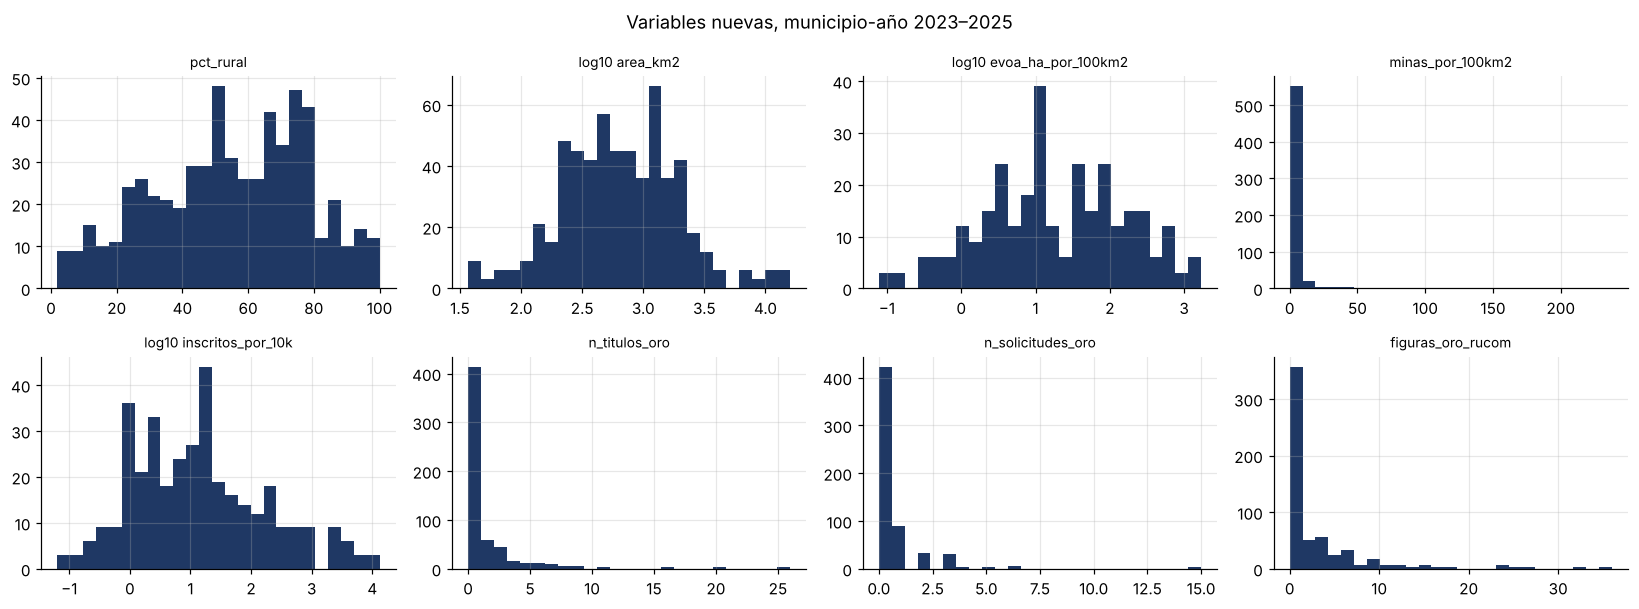

Inscritos por 10.000 habitantes más altos (municipio-año):


,codigo_dane,municipio,anio,n_barequeros,poblacion_total,inscritos_por_10k,tipo_predominante
414,27810,Union Panamericana,2023,"9,386.00","7,136.00","13,153.03",aluvión con barequeo
415,27810,Union Panamericana,2024,"9,386.00","7,202.00","13,032.49",aluvión con barequeo
416,27810,Union Panamericana,2025,"9,386.00","7,272.00","12,907.04",aluvión con barequeo
372,27413,Lloro,2023,"8,077.00","10,241.00","7,886.93",aluvión con barequeo
373,27413,Lloro,2024,"8,077.00","10,316.00","7,829.59",aluvión con barequeo
374,27413,Lloro,2025,"8,077.00","10,407.00","7,761.12",aluvión con barequeo



Medianas por tipo predominante:


,municipios,pct_rural,huella_por_100km2,titulos_rucom,pdet
tipo_predominante,,,,,
aluvión con barequeo,96,57.54,0.00,0.00,0.29
aluvión con títulos,12,52.46,109.69,6.00,0.67
huella sin declaración,31,52.82,5.08,0.00,0.68
otros,17,66.67,3.75,1.00,0.24
registro sin volumen ni huella,6,48.49,0.00,0.00,0.00
veta / títulos,35,54.03,0.00,2.00,0.14


In [11]:
cols_desc = ["pct_rural", "area_km2", "evoa_ha_por_100km2", "minas_por_100km2", "inscritos_por_10k", "n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro"]
desc = tabla_resumen(amp, cols_desc); display(desc)
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6))
for ax, c in zip(axes.ravel(), ["pct_rural", "area_km2", "evoa_ha_por_100km2", "minas_por_100km2", "inscritos_por_10k", "n_titulos_oro", "n_solicitudes_oro", "figuras_oro_rucom"]):
    s = amp[c]; s = np.log10(s[s > 0]) if c in ("area_km2", "evoa_ha_por_100km2", "inscritos_por_10k") else s
    ax.hist(s.dropna(), bins=25, color=AZUL); ax.set_title(("log10 " if c in ("area_km2", "evoa_ha_por_100km2", "inscritos_por_10k") else "") + c, fontsize=9)
plt.suptitle("Variables nuevas, municipio-año 2023–2025"); plt.tight_layout(); plt.show()
print("Inscritos por 10.000 habitantes más altos (municipio-año):"); display(amp.nlargest(6, "inscritos_por_10k")[["codigo_dane", "municipio", "anio", "n_barequeros", "poblacion_total", "inscritos_por_10k", "tipo_predominante"]])
print("\nMedianas por tipo predominante:")
display(amp.groupby("tipo_predominante").agg(municipios=("codigo_dane", "nunique"), pct_rural=("pct_rural", "median"),
                                              huella_por_100km2=("evoa_ha_por_100km2", "median"), titulos_rucom=("n_titulos_oro", "median"), pdet=("pdet", "mean")).round(2))

### 7.2 Spearman de las variables nuevas con las del panel

Correlación de las variables nuevas con las del panel (Spearman):


,gramos_anm,g_titulos,g_barequeros,share_barequeo,ratio_tope_bareq,evoa_ha_2023,share_ilicita_2023,minas,capturas,maquinaria
pct_rural,0.05,-0.04,-0.01,-0.01,-0.05,0.09,-0.01,-0.30,-0.19,-0.18
evoa_ha_por_100km2,0.33,0.18,0.36,0.04,0.35,0.99,-0.50,0.04,-0.05,0.33
inscritos_por_10k,0.44,0.23,0.46,0.14,0.31,0.36,-0.32,0.12,0.05,0.20
n_titulos_oro,0.47,0.66,0.10,-0.53,0.10,0.20,-0.49,0.11,0.15,0.05
n_solicitudes_oro,0.46,0.33,0.31,-0.16,0.34,0.47,-0.34,0.05,-0.06,0.19
n_subcontratos_oro,0.42,0.45,0.22,-0.23,0.19,0.27,-0.44,0.31,0.23,0.24
pdet,0.04,0.02,0.07,0.04,0.06,0.51,-0.07,-0.10,0.02,0.10


Entre las nuevas:


,pct_rural,evoa_ha_por_100km2,inscritos_por_10k,n_titulos_oro,n_solicitudes_oro,n_subcontratos_oro,pdet
pct_rural,1.00,0.08,0.07,-0.05,0.14,-0.10,0.05
evoa_ha_por_100km2,0.08,1.00,0.39,0.22,0.47,0.27,0.46
inscritos_por_10k,0.07,0.39,1.00,0.23,0.28,0.14,0.13
n_titulos_oro,-0.05,0.22,0.23,1.00,0.33,0.46,0.06
n_solicitudes_oro,0.14,0.47,0.28,0.33,1.00,0.30,0.17
n_subcontratos_oro,-0.10,0.27,0.14,0.46,0.30,1.00,0.09
pdet,0.05,0.46,0.13,0.06,0.17,0.09,1.00


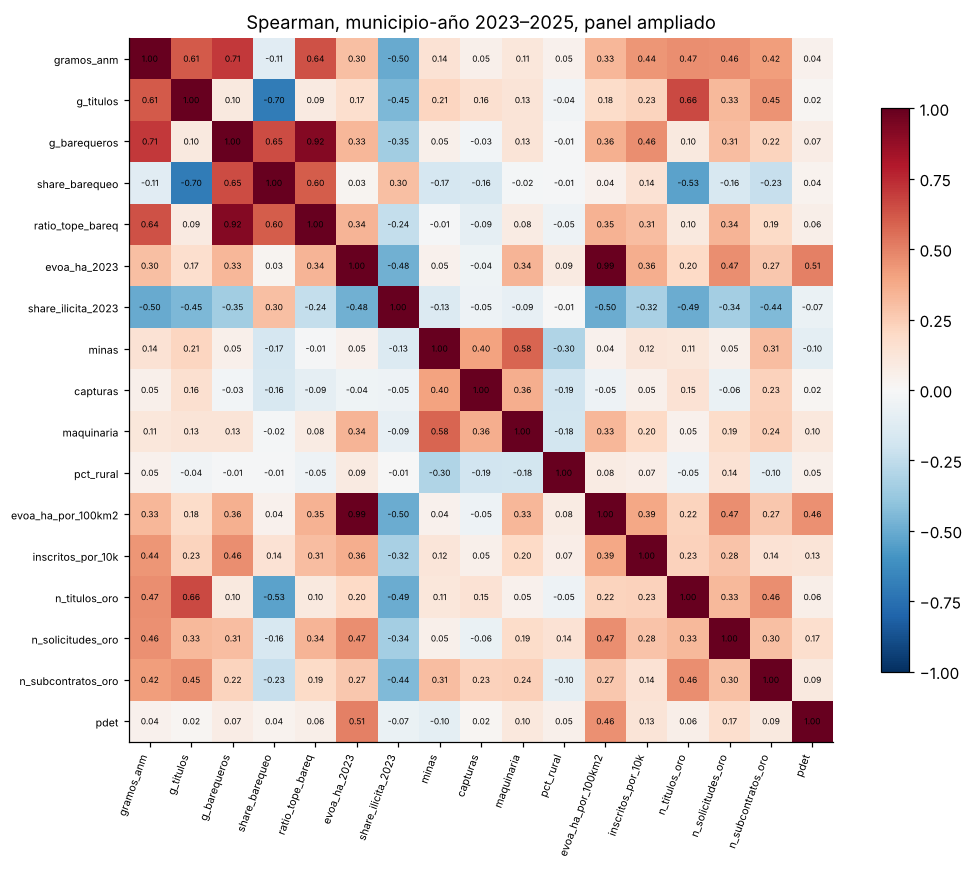

In [12]:
cc = ["gramos_anm", "g_titulos", "g_barequeros", "share_barequeo", "ratio_tope_bareq", "evoa_ha_2023", "share_ilicita_2023", "minas", "capturas", "maquinaria",
      "pct_rural", "evoa_ha_por_100km2", "inscritos_por_10k", "n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro", "pdet"]
corr = amp[cc].corr(method="spearman")
print("Correlación de las variables nuevas con las del panel (Spearman):"); display(corr.loc[cc[10:], cc[:10]].round(2))
print("Entre las nuevas:"); display(corr.loc[cc[10:], cc[10:]].round(2))
fig, ax = plt.subplots(figsize=(10, 8)); im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cc))); ax.set_xticklabels(cc, rotation=70, ha="right", fontsize=7); ax.set_yticks(range(len(cc))); ax.set_yticklabels(cc, fontsize=7)
for i in range(len(cc)):
    for j in range(len(cc)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=5.5)
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Spearman, municipio-año 2023–2025, panel ampliado"); plt.tight_layout(); plt.show()

### 7.3 Categorías nuevas para el ACM (PDET, figuras RUCOM) y archivos de salida

In [13]:
cat = pd.read_csv(SAL / "acm_categorias_municipio_2023_2025.csv", dtype={"codigo_dane": str})
m = amp.groupby("codigo_dane").agg(pdet=("pdet", "first"), figuras=("figuras_oro_rucom", "first")).reset_index()
m["pdet_cat"] = np.where(m.pdet == 1, "PDET", "no PDET"); m["figuras_rucom"] = pd.cut(m.figuras, [-1, 0, 3, np.inf], labels=["ninguna", "1 a 3", "más de 3"]).astype(str)
cat2 = cat.merge(m[["codigo_dane", "pdet_cat", "figuras_rucom"]], on="codigo_dane", how="left")
VARS2 = ["pdet_cat", "figuras_rucom"]
frec = pd.concat([cat2[v].value_counts().rename_axis("categoria").reset_index(name="municipios").assign(variable=v) for v in VARS2]); frec["pct"] = (frec.municipios / len(cat2) * 100).round(1)
display(frec[["variable", "categoria", "municipios", "pct"]].reset_index(drop=True))
raras = frec[frec.pct < 5]
check("ACM", "Ninguna categoría nueva por debajo del 5 % de los municipios", len(raras) == 0, f"{len(raras)} raras: {raras[['variable', 'categoria', 'municipios']].values.tolist()}")
print("Tipo predominante × figuras de oro autorizadas en el RUCOM:"); display(pd.crosstab(cat2.explotador, cat2.figuras_rucom))

DICC2 = pd.DataFrame([
    ("poblacion_total", "denominador", "DANE PPED 2018–2042", "población proyectada del año", "—"), ("pct_rural", "estructurales", "DANE", "población en centros poblados y rural disperso / total × 100", "—"),
    ("area_km2", "estructurales", "DANE MGN 2024", "área del municipio", "—"), ("evoa_ha_por_100km2", "estructurales", "derivada", "huella 2023 / área × 100", "0 sin huella"), ("minas_por_100km2", "seguridad (Estado)", "derivada", "minas intervenidas / área × 100", "0 sin eventos"),
    ("inscritos_por_10k", "institucionales", "derivada", "barequeros inscritos / población × 10.000", "0 sin inscritos"), ("n_titulos_oro", "institucionales", "ANM RUCOM 42ha-fhvj", "títulos de oro con explotador autorizado (foto ene-2025)", "0"),
    ("n_solicitudes_oro", "institucionales", "ANM RUCOM 7amp-4swy", "solicitudes de legalización de oro autorizadas", "0"), ("n_subcontratos_oro", "institucionales", "ANM RUCOM xzu3-gnau", "subcontratos de formalización de oro autorizados", "0"),
    ("n_titulos_oro_con_anotacion_2023_2025", "institucionales (control)", "ANM RMN si2v-pbq5", "títulos de oro con anotación registral en la ventana", "0"), ("figuras_oro_rucom", "institucionales", "derivada", "títulos + solicitudes + subcontratos", "0"),
    ("pdet", "estructurales (contexto)", "ART idrk-ba8y", "1 si el municipio es PDET", "0"), ("subregion_pdet", "estructurales (contexto)", "ART", "subregión PDET", "NaN si no es PDET"),
], columns=["variable", "familia", "fuente", "definicion", "regla_de_ausencia"])
amp.to_csv(SAL / "panel_municipal_2023_2025_ampliado.csv", index=False); ampq.to_csv(SAL / "panel_municipal_trimestral_2023_2025_ampliado.csv", index=False)
DICC2.to_csv(SAL / "panel_municipal_2023_2025_ampliado_diccionario_nuevas.csv", index=False); cat2.to_csv(SAL / "acm_categorias_municipio_2023_2025_ampliado.csv", index=False)
desc.to_csv(SAL / "caracterizacion_descriptivas_complementos_2023_2025.csv"); mv.to_csv(SAL / "caracterizacion_valores_perdidos_complementos_2023_2025.csv")
print("Guardado en", SAL); display(DICC2)

,variable,categoria,municipios,pct
0,pdet_cat,no PDET,131,66.50
1,pdet_cat,PDET,66,33.50
2,figuras_rucom,ninguna,75,38.10
3,figuras_rucom,1 a 3,70,35.50
4,figuras_rucom,más de 3,52,26.40


[OK     ] Ninguna categoría nueva por debajo del 5 % de los municipios — 0 raras: []
Tipo predominante × figuras de oro autorizadas en el RUCOM:


figuras_rucom,1 a 3,más de 3,ninguna
explotador,,,
barequeros,28,21,47
otros,9,6,2
sin declaración,11,1,25
títulos,22,24,1


Guardado en /home/claude/jdnieto28-hub/tesis/06_panel


,variable,familia,fuente,definicion,regla_de_ausencia
0,poblacion_total,denominador,DANE PPED 2018–2042,población proyectada del año,—
1,pct_rural,estructurales,DANE,población en centros poblados y rural disperso / total × 100,—
2,area_km2,estructurales,DANE MGN 2024,área del municipio,—
3,evoa_ha_por_100km2,estructurales,derivada,huella 2023 / área × 100,0 sin huella
4,minas_por_100km2,seguridad (Estado),derivada,minas intervenidas / área × 100,0 sin eventos
5,inscritos_por_10k,institucionales,derivada,barequeros inscritos / población × 10.000,0 sin inscritos
6,n_titulos_oro,institucionales,ANM RUCOM 42ha-fhvj,títulos de oro con explotador autorizado (foto ene-2025),0
7,n_solicitudes_oro,institucionales,ANM RUCOM 7amp-4swy,solicitudes de legalización de oro autorizadas,0
8,n_subcontratos_oro,institucionales,ANM RUCOM xzu3-gnau,subcontratos de formalización de oro autorizados,0
9,n_titulos_oro_con_anotacion_2023_2025,institucionales (control),ANM RMN si2v-pbq5,títulos de oro con anotación registral en la ventana,0


## 8. Variables candidatas según la Tabla 3: lista, papel y transformación

In [14]:
amp = amp.copy()
amp["declara"] = (amp.gramos_anm > 0).astype(int)
CANDIDATAS = pd.DataFrame([
    ("gramos_anm", "Respuesta (ANM)", "sí", "respuesta de la parte de volumen", "log(1 + g)", "municipio-año"),
    ("declara", "Respuesta (derivada de ANM)", "sí", "respuesta de la parte de participación", "binaria", "municipio-año"),
    ("regalias_cop", "Económica (ANM)", "sí", "descriptiva; función de la producción", "log(1 + COP)", "municipio-año"),
    ("precio_usd_onza", "Económica (UPME-LBMA)", "solo en el tiempo", "factor; por interacción con el perfil y rezagos", "ninguna (nacional)", "año"),
    ("trm", "Económica (Superfinanciera)", "solo en el tiempo", "factor; por interacción y rezagos", "ninguna (nacional)", "año"),
    ("precio_cop_gramo", "Económica (derivada)", "solo en el tiempo", "factor; por interacción y rezagos", "ninguna (nacional)", "año"),
    ("share_barequeo", "Institucional (SIMCI)", "sí", "suplementaria (deriva de la respuesta)", "proporción", "municipio-año"),
    ("n_barequeros", "Institucional (ANM-RUCOM)", "no (padrón vigente)", "factor activo, en categorías gruesas", "log(1 + n); categorías 0 / 1–50 / >50", "municipio"),
    ("inscritos_por_10k", "Institucional (derivada)", "no", "factor activo (intensidad)", "log(1 + tasa)", "municipio"),
    ("ratio_tope_bareq", "Institucional (derivada)", "sí", "suplementaria (deriva de la respuesta)", "razón", "municipio-año"),
    ("n_titulos_oro", "Institucional (ANM-RUCOM)", "no (corte ene-2025)", "factor activo", "log(1 + n)", "municipio"),
    ("n_solicitudes_oro", "Institucional (ANM-RUCOM)", "no", "factor activo", "log(1 + n)", "municipio"),
    ("n_subcontratos_oro", "Institucional (ANM-RUCOM)", "no", "factor activo", "log(1 + n)", "municipio"),
    ("figuras_oro_rucom", "Institucional (derivada)", "no", "factor activo (suma de las tres figuras)", "log(1 + n); categorías ninguna / 1–3 / >3", "municipio"),
    ("evoa_ha_2023", "Estructural (UNODC-MinMinas, EVOA)", "no (solo 2023)", "factor activo, característica fija", "log(1 + ha)", "municipio"),
    ("evoa_ha_por_100km2", "Estructural (derivada)", "no", "factor activo (intensidad)", "log(1 + ha/100 km²)", "municipio"),
    ("share_ilicita_2023", "Estructural (EVOA)", "no", "factor activo (H4); solo donde hay huella", "proporción; 0 sin huella + huella en log", "municipio"),
    ("tipo_predominante", "Estructural (derivada)", "no", "contraste de perfiles (deriva de la respuesta)", "categórica", "municipio"),
    ("minas", "Seguridad y presencia estatal (MinDefensa)", "sí", "factor activo, contemporáneo y rezagado", "log(1 + n)", "municipio-año"),
    ("capturas", "Seguridad y presencia estatal (MinDefensa)", "sí", "factor activo", "log(1 + n)", "municipio-año"),
    ("maquinaria", "Seguridad y presencia estatal (MinDefensa)", "sí", "factor activo", "log(1 + n)", "municipio-año"),
    ("poblacion_total", "Control territorial (DANE)", "sí, muy poco", "denominador y control", "log(hab)", "municipio-año"),
    ("pct_rural", "Control territorial (DANE)", "sí, muy poco", "control", "porcentaje", "municipio-año"),
    ("area_km2", "Control territorial (DANE-MGN)", "no", "denominador y control", "log(km²)", "municipio"),
    ("pdet", "Control territorial (ART)", "no", "control (binaria)", "binaria", "municipio"),
], columns=["variable", "familia_y_fuente", "varia_2023_2025", "papel_en_el_analisis", "transformacion", "grano"])

ACTIVAS = ["n_barequeros", "n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro", "evoa_ha_2023", "share_ilicita_2023", "minas", "capturas", "maquinaria"]
CONTROLES = ["poblacion_total", "pct_rural", "area_km2", "pdet"]
SUPLEMENTARIAS = ["regalias_cop", "share_barequeo", "ratio_tope_bareq", "tipo_predominante"]
DERIVADAS_DE_LA_RESPUESTA = {"regalias_cop", "share_barequeo", "share_titulos", "ratio_tope_bareq", "tipo_predominante", "explotador_dominante", "g_titulos", "g_barequeros", "g_otros", "gramos_simci", "n_trimestres"}

check("Candidatas", "Todas las variables candidatas existen en el panel ampliado", set(CANDIDATAS.variable) <= set(amp.columns), f"faltan {sorted(set(CANDIDATAS.variable) - set(amp.columns))}")
check("Candidatas", "Ninguna variable derivada de la respuesta figura entre los factores activos o controles", not (set(ACTIVAS + CONTROLES) & DERIVADAS_DE_LA_RESPUESTA))
display(CANDIDATAS.set_index("variable"))
print(f"Factores activos: {len(ACTIVAS)} · controles: {len(CONTROLES)} · suplementarias descritas: {len(SUPLEMENTARIAS)} · nacionales: 3")

[OK     ] Todas las variables candidatas existen en el panel ampliado — faltan []
[OK     ] Ninguna variable derivada de la respuesta figura entre los factores activos o controles


,familia_y_fuente,varia_2023_2025,papel_en_el_analisis,transformacion,grano
variable,,,,,
gramos_anm,Respuesta (ANM),sí,respuesta de la parte de volumen,log(1 + g),municipio-año
declara,Respuesta (derivada de ANM),sí,respuesta de la parte de participación,binaria,municipio-año
regalias_cop,Económica (ANM),sí,descriptiva; función de la producción,log(1 + COP),municipio-año
precio_usd_onza,Económica (UPME-LBMA),solo en el tiempo,factor; por interacción con el perfil y rezagos,ninguna (nacional),año
trm,Económica (Superfinanciera),solo en el tiempo,factor; por interacción y rezagos,ninguna (nacional),año
precio_cop_gramo,Económica (derivada),solo en el tiempo,factor; por interacción y rezagos,ninguna (nacional),año
share_barequeo,Institucional (SIMCI),sí,suplementaria (deriva de la respuesta),proporción,municipio-año
n_barequeros,Institucional (ANM-RUCOM),no (padrón vigente),"factor activo, en categorías gruesas",log(1 + n); categorías 0 / 1–50 / >50,municipio
inscritos_por_10k,Institucional (derivada),no,factor activo (intensidad),log(1 + tasa),municipio


Factores activos: 9 · controles: 4 · suplementarias descritas: 4 · nacionales: 3


### 8.1 Descriptivas en escala original (591 municipio-años / 197 municipios)

In [15]:
mun = amp.sort_values(["codigo_dane", "anio"]).groupby("codigo_dane").first().reset_index()   # una fila por municipio (valores fijos)
VARIAN = ["gramos_anm", "declara", "regalias_cop", "share_barequeo", "ratio_tope_bareq", "minas", "capturas", "maquinaria", "poblacion_total", "pct_rural"]
FIJAS = ["n_barequeros", "inscritos_por_10k", "n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro", "figuras_oro_rucom", "evoa_ha_2023", "evoa_ha_por_100km2", "share_ilicita_2023", "area_km2", "pdet"]

desc_c = pd.concat([tabla_resumen(amp, VARIAN).assign(grano="municipio-año (591)"), tabla_resumen(mun, FIJAS).assign(grano="municipio (197)")])
desc_c.insert(0, "familia", desc_c.index.map(CANDIDATAS.set_index("variable").familia_y_fuente))
cols_orden = ["familia", "grano", "n", "nulos", "ceros", "media", "desv_est", "cv", "min", "p5", "p25", "mediana", "p75", "p95", "max", "asimetria", "curtosis"]
desc_c = desc_c[cols_orden]
print("Descriptivas de las variables candidatas en su escala original:")
display(desc_c)

print("Factores económicos nacionales (promedio anual del panel; idénticos para los 197 municipios):")
display(amp.groupby("anio")[["precio_usd_onza", "trm", "precio_cop_gramo"]].first().round(1))

Descriptivas de las variables candidatas en su escala original:


,familia,grano,n,nulos,ceros,media,desv_est,cv,min,p5,p25,mediana,p75,p95,max,asimetria,curtosis
gramos_anm,Respuesta (ANM),municipio-año (591),591.00,0.00,213.00,"286,326.95","1,205,686.51",4.21,0.00,0.00,0.00,"1,769.24","61,401.86","1,187,625.32","15,381,919.90",7.54,68.52
declara,Respuesta (derivada de ANM),municipio-año (591),591.00,0.00,213.00,0.64,0.48,0.75,0.00,0.00,0.00,1.00,1.00,1.00,1.00,-0.58,-1.67
regalias_cop,Económica (ANM),municipio-año (591),591.00,0.00,203.00,"2,662,362,946.49","11,707,217,557.80",4.40,0.00,0.00,0.00,"24,178,700.85","753,652,814.91","11,903,273,706.18","144,164,527,912.64",8.52,83.17
share_barequeo,Institucional (SIMCI),municipio-año (591),372.00,219.00,118.00,0.55,0.47,0.86,0.00,0.00,0.00,0.81,1.00,1.00,1.00,-0.18,-1.89
ratio_tope_bareq,Institucional (derivada),municipio-año (591),360.00,231.00,171.00,4.15,23.72,5.72,0.00,0.00,0.00,0.02,0.87,15.64,365.25,11.60,159.14
minas,Seguridad y presencia estatal (MinDefensa),municipio-año (591),591.00,0.00,300.00,9.32,27.88,2.99,0.00,0.00,0.00,0.00,6.00,45.00,310.00,6.44,53.60
capturas,Seguridad y presencia estatal (MinDefensa),municipio-año (591),591.00,0.00,423.00,2.91,7.71,2.65,0.00,0.00,0.00,0.00,2.00,16.00,67.00,4.44,24.49
maquinaria,Seguridad y presencia estatal (MinDefensa),municipio-año (591),591.00,0.00,329.00,5.71,19.18,3.36,0.00,0.00,0.00,0.00,3.00,27.00,300.00,8.94,110.59
poblacion_total,Control territorial (DANE),municipio-año (591),591.00,0.00,1.00,"54,743.47","194,120.67",3.55,0.00,"5,156.50","11,095.50","19,624.00","37,926.50","144,430.00","2,528,343.00",10.81,132.18
pct_rural,Control territorial (DANE),municipio-año (591),590.00,1.00,0.00,54.63,23.35,0.43,1.92,12.37,38.51,55.86,73.04,91.21,100.00,-0.26,-0.73


Factores económicos nacionales (promedio anual del panel; idénticos para los 197 municipios):


,precio_usd_onza,trm,precio_cop_gramo
anio,,,
2023,"1,942.70","4,324.20","269,878.10"
2024,"2,387.70","4,074.80","313,908.00"
2025,"3,441.50","4,051.80","445,999.50"


### 8.2 Descriptivas en log(1 + x)

In [16]:
def log1p_cols(df, cols):
    return pd.DataFrame({f"log1p_{c}": np.log1p(df[c]) for c in cols})

tr = pd.concat([log1p_cols(amp, ["gramos_anm", "minas", "capturas", "maquinaria"]), np.log(amp.poblacion_total.replace(0, np.nan)).rename("log_poblacion")], axis=1)
trf = pd.concat([log1p_cols(mun, ["n_barequeros", "n_titulos_oro", "n_solicitudes_oro", "n_subcontratos_oro", "evoa_ha_2023"]), np.log(mun.area_km2).rename("log_area_km2")], axis=1)
desc_t = pd.concat([tabla_resumen(tr, list(tr.columns)).assign(grano="municipio-año (591)"), tabla_resumen(trf, list(trf.columns)).assign(grano="municipio (197)")])
desc_t = desc_t[["grano", "n", "nulos", "ceros", "media", "desv_est", "min", "mediana", "max", "asimetria", "curtosis"]]
print("Las mismas variables en logaritmo (1 + x):")
display(desc_t)
check("Candidatas", "El logaritmo reduce la asimetría de todas las variables de volumen y conteo por debajo de 3", (desc_t.asimetria.abs() < 3).all(), f"máx |asimetría| = {desc_t.asimetria.abs().max():.2f}")

Las mismas variables en logaritmo (1 + x):


,grano,n,nulos,ceros,media,desv_est,min,mediana,max,asimetria,curtosis
log1p_gramos_anm,municipio-año (591),591.00,0.00,213.00,6.38,5.36,0.00,7.48,16.55,-0.04,-1.52
log1p_minas,municipio-año (591),591.00,0.00,300.00,1.07,1.36,0.00,0.00,5.74,1.11,0.30
log1p_capturas,municipio-año (591),591.00,0.00,423.00,0.58,1.02,0.00,0.00,4.22,1.58,1.28
log1p_maquinaria,municipio-año (591),591.00,0.00,329.00,0.85,1.19,0.00,0.00,5.71,1.35,1.05
log_poblacion,municipio-año (591),590.00,1.00,0.00,10.01,1.08,7.58,9.89,14.74,0.91,2.25
log1p_n_barequeros,municipio (197),197.00,0.00,77.00,2.16,2.41,0.00,1.61,10.28,1.01,0.32
log1p_n_titulos_oro,municipio (197),197.00,0.00,97.00,0.61,0.74,0.00,0.69,3.30,1.10,0.70
log1p_n_solicitudes_oro,municipio (197),197.00,0.00,141.00,0.29,0.51,0.00,0.00,2.77,1.83,3.21
log1p_n_subcontratos_oro,municipio (197),197.00,0.00,155.00,0.30,0.67,0.00,0.00,2.94,2.29,4.39
log1p_evoa_ha_2023,municipio (197),197.00,0.00,96.00,2.73,3.04,0.00,1.71,9.07,0.57,-1.18


[OK     ] El logaritmo reduce la asimetría de todas las variables de volumen y conteo por debajo de 3 — máx |asimetría| = 2.29


### 8.3 Varianza entre municipios y dentro de cada municipio (ecuación 4)

In [17]:
def entre_intra(df, col):
    d = df[["codigo_dane", col]].dropna()
    y = d[col].values
    medias = d.groupby("codigo_dane")[col].transform("mean").values
    sst = ((y - y.mean()) ** 2).sum()
    intra = ((y - medias) ** 2).sum()
    entre = sst - intra
    return pd.Series({"n_obs": len(d), "pct_entre_municipios": entre / sst * 100 if sst else np.nan, "pct_intra_municipio": intra / sst * 100 if sst else np.nan})

amp_t = amp.assign(log1p_gramos_anm=np.log1p(amp.gramos_anm), log1p_minas=np.log1p(amp.minas), log1p_capturas=np.log1p(amp.capturas),
                   log1p_maquinaria=np.log1p(amp.maquinaria), log_poblacion=np.log(amp.poblacion_total.replace(0, np.nan)))
var_ei = pd.DataFrame({c: entre_intra(amp_t, c) for c in ["log1p_gramos_anm", "declara", "log1p_minas", "log1p_capturas", "log1p_maquinaria", "log_poblacion", "pct_rural", "precio_usd_onza"]}).T.round(1)
print("Varianza entre municipios frente a varianza dentro de cada municipio (2023–2025):")
display(var_ei)
check("Candidatas", "La varianza de log(1 + gramos) está sobre todo entre municipios (≥ 75 %), como anticipa la sección 3 del documento", var_ei.loc["log1p_gramos_anm", "pct_entre_municipios"] >= 75, f"{var_ei.loc['log1p_gramos_anm', 'pct_entre_municipios']:.1f} % entre")

desc_c.to_csv(SAL / "candidatas_descriptivas_2023_2025.csv")
var_ei.to_csv(SAL / "candidatas_varianza_entre_intra_2023_2025.csv")

Varianza entre municipios frente a varianza dentro de cada municipio (2023–2025):


,n_obs,pct_entre_municipios,pct_intra_municipio
log1p_gramos_anm,591.00,82.40,17.60
declara,591.00,64.80,35.20
log1p_minas,591.00,75.80,24.20
log1p_capturas,591.00,66.30,33.70
log1p_maquinaria,591.00,73.10,26.90
log_poblacion,590.00,99.90,0.10
pct_rural,590.00,99.90,0.10
precio_usd_onza,591.00,-0.00,100.00


[OK     ] La varianza de log(1 + gramos) está sobre todo entre municipios (≥ 75 %), como anticipa la sección 3 del documento — 82.4 % entre


### 8.4 Histogramas de las 16 candidatas

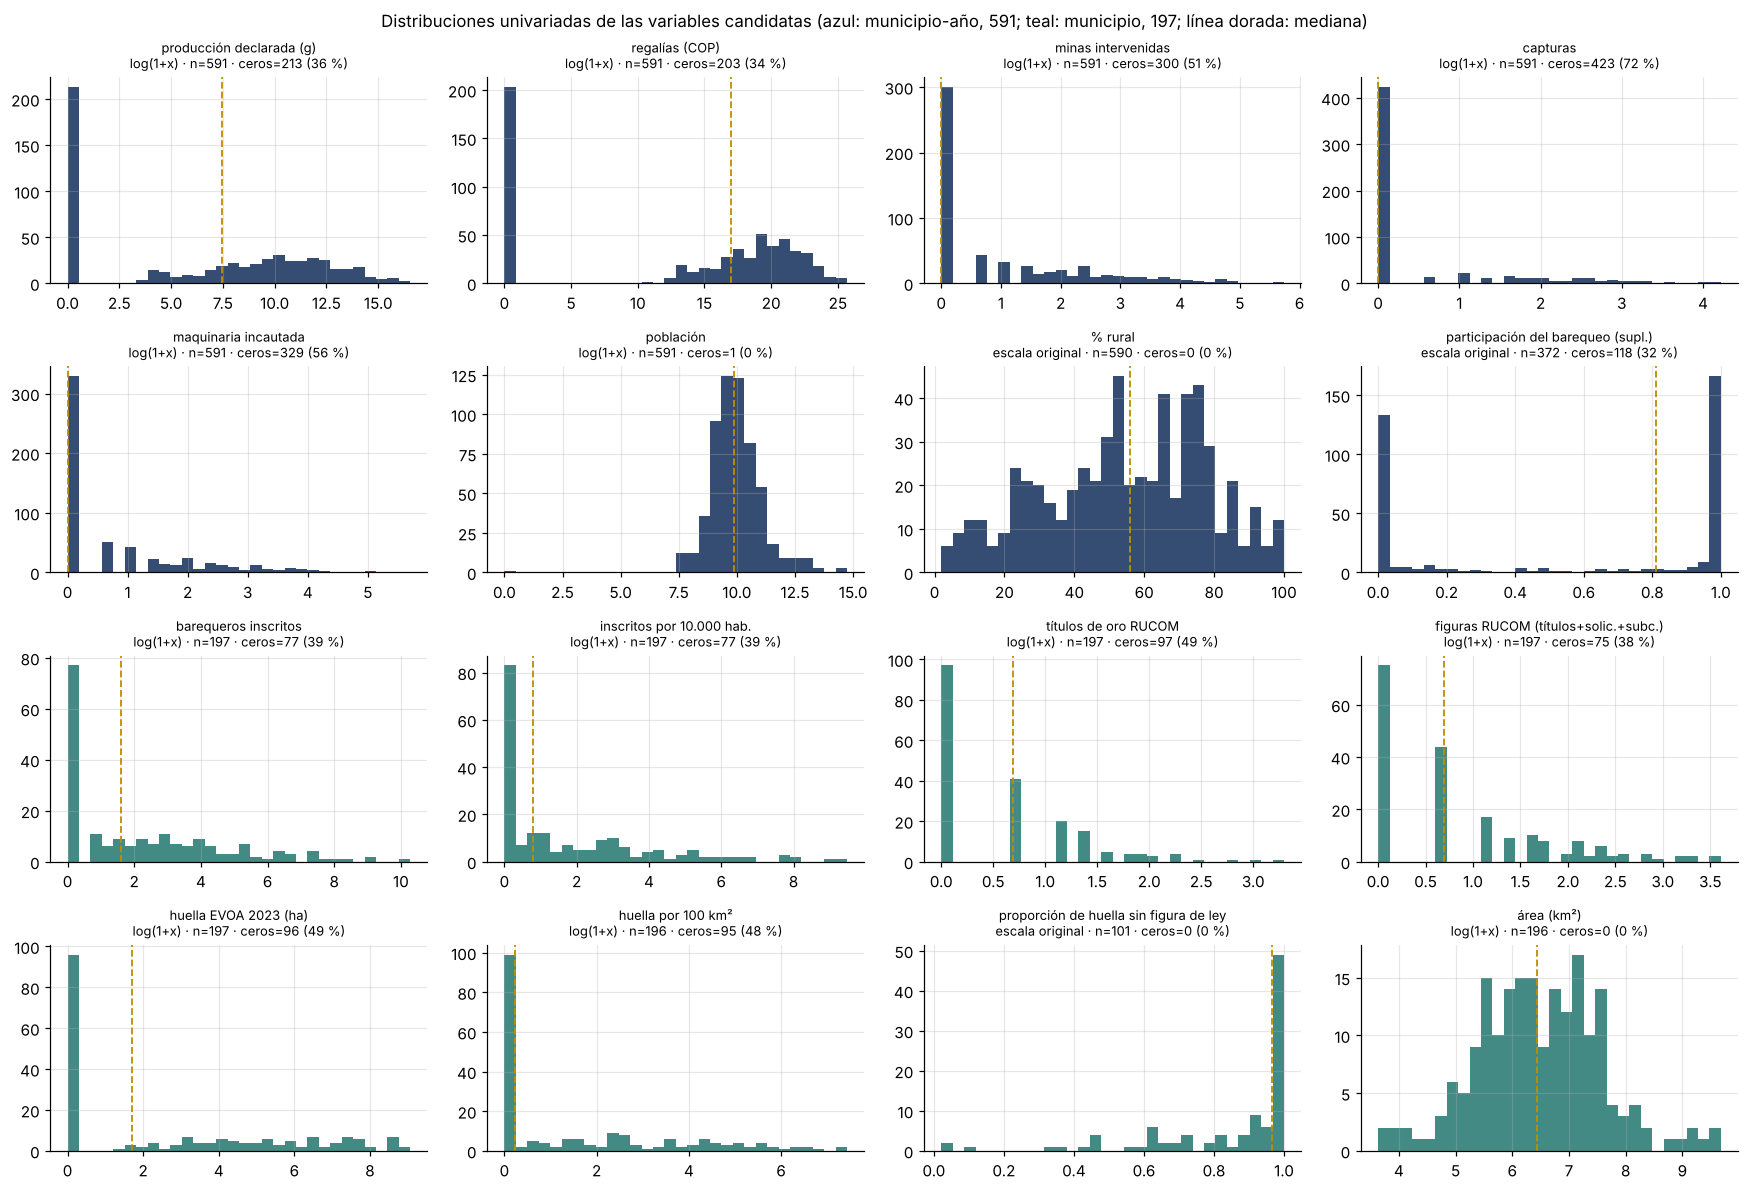

In [18]:
FIG_DIR = RAIZ / "07_figuras"
FIG_DIR.mkdir(exist_ok=True)
PANEL_HIST = [  # (columna, marco, etiqueta, escala)
    ("gramos_anm", amp, "producción declarada (g)", "log1p"), ("regalias_cop", amp, "regalías (COP)", "log1p"), ("minas", amp, "minas intervenidas", "log1p"), ("capturas", amp, "capturas", "log1p"),
    ("maquinaria", amp, "maquinaria incautada", "log1p"), ("poblacion_total", amp, "población", "log1p"), ("pct_rural", amp, "% rural", "lineal"), ("share_barequeo", amp, "participación del barequeo (supl.)", "lineal"),
    ("n_barequeros", mun, "barequeros inscritos", "log1p"), ("inscritos_por_10k", mun, "inscritos por 10.000 hab.", "log1p"), ("n_titulos_oro", mun, "títulos de oro RUCOM", "log1p"), ("figuras_oro_rucom", mun, "figuras RUCOM (títulos+solic.+subc.)", "log1p"),
    ("evoa_ha_2023", mun, "huella EVOA 2023 (ha)", "log1p"), ("evoa_ha_por_100km2", mun, "huella por 100 km²", "log1p"), ("share_ilicita_2023", mun, "proporción de huella sin figura de ley", "lineal"), ("area_km2", mun, "área (km²)", "log1p"),
]
fig, axes = plt.subplots(4, 4, figsize=(16, 11))
for ax, (c, marco, et, esc) in zip(axes.ravel(), PANEL_HIST):
    s = marco[c].dropna()
    ceros = int((s == 0).sum())
    x = np.log1p(s) if esc == "log1p" else s
    ax.hist(x, bins=30, color=AZUL if marco is amp else TEAL, alpha=0.9)
    ax.set_title(f"{et}\n{'log(1+x)' if esc == 'log1p' else 'escala original'} · n={len(s)} · ceros={ceros} ({ceros/len(s)*100:.0f} %)", fontsize=8.5)
    ax.axvline(x.median(), color=DORADO, lw=1.2, ls="--")
plt.suptitle("Distribuciones univariadas de las variables candidatas (azul: municipio-año, 591; teal: municipio, 197; línea dorada: mediana)", fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_candidatas_distribuciones_2023_2025.png", dpi=160, bbox_inches="tight")
plt.show()

### 8.5 Producción declarada por año: municipios en cero y mediana de los positivos

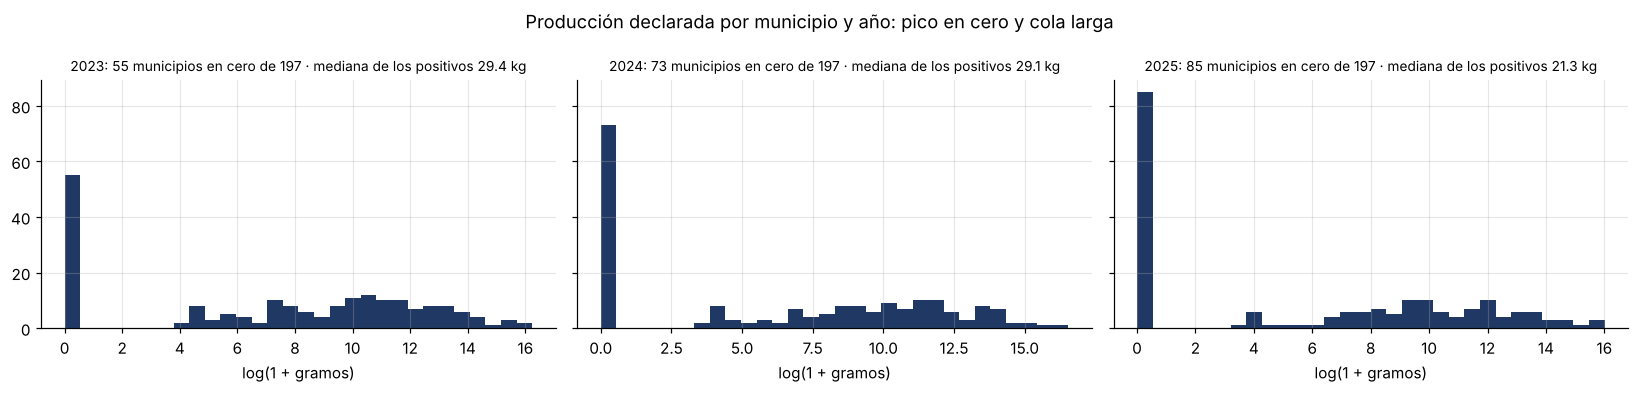

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, a in zip(axes, ANIOS):
    s = np.log1p(amp.loc[amp.anio == a, "gramos_anm"])
    ax.hist(s, bins=30, color=AZUL)
    ax.set_title(f"{a}: {int((s == 0).sum())} municipios en cero de 197 · mediana de los positivos {np.expm1(s[s > 0].median())/1000:,.1f} kg", fontsize=9)
    ax.set_xlabel("log(1 + gramos)")
plt.suptitle("Producción declarada por municipio y año: pico en cero y cola larga")
plt.tight_layout()
plt.show()

### 8.6 Barequeros inscritos en tres categorías frente a declarar en 2023

In [20]:
cat_bareq = pd.cut(mun.n_barequeros, [-1, 0, 50, np.inf], labels=["0 inscritos", "1 a 50", "más de 50"])
tab_b = pd.crosstab(cat_bareq, mun.declara.rename("declara en 2023"))
tab_b["municipios"] = tab_b.sum(axis=1)
tab_b["% del universo"] = (tab_b.municipios / len(mun) * 100).round(1)
print("Barequeros inscritos en categorías gruesas (padrón 2-sep-2026) frente a declarar en 2023:")
display(tab_b)
check("Candidatas", "Ninguna categoría gruesa de barequeros reúne menos del 5 % de los municipios", (tab_b["% del universo"] >= 5).all())

Barequeros inscritos en categorías gruesas (padrón 2-sep-2026) frente a declarar en 2023:


declara en 2023,0,1,municipios,% del universo
n_barequeros,,,,
0 inscritos,33,44,77,39.10
1 a 50,18,62,80,40.60
más de 50,4,36,40,20.30


[OK     ] Ninguna categoría gruesa de barequeros reúne menos del 5 % de los municipios


### 8.7 Dispersión de cada factor frente a log(1 + gramos), con Spearman total y en positivos

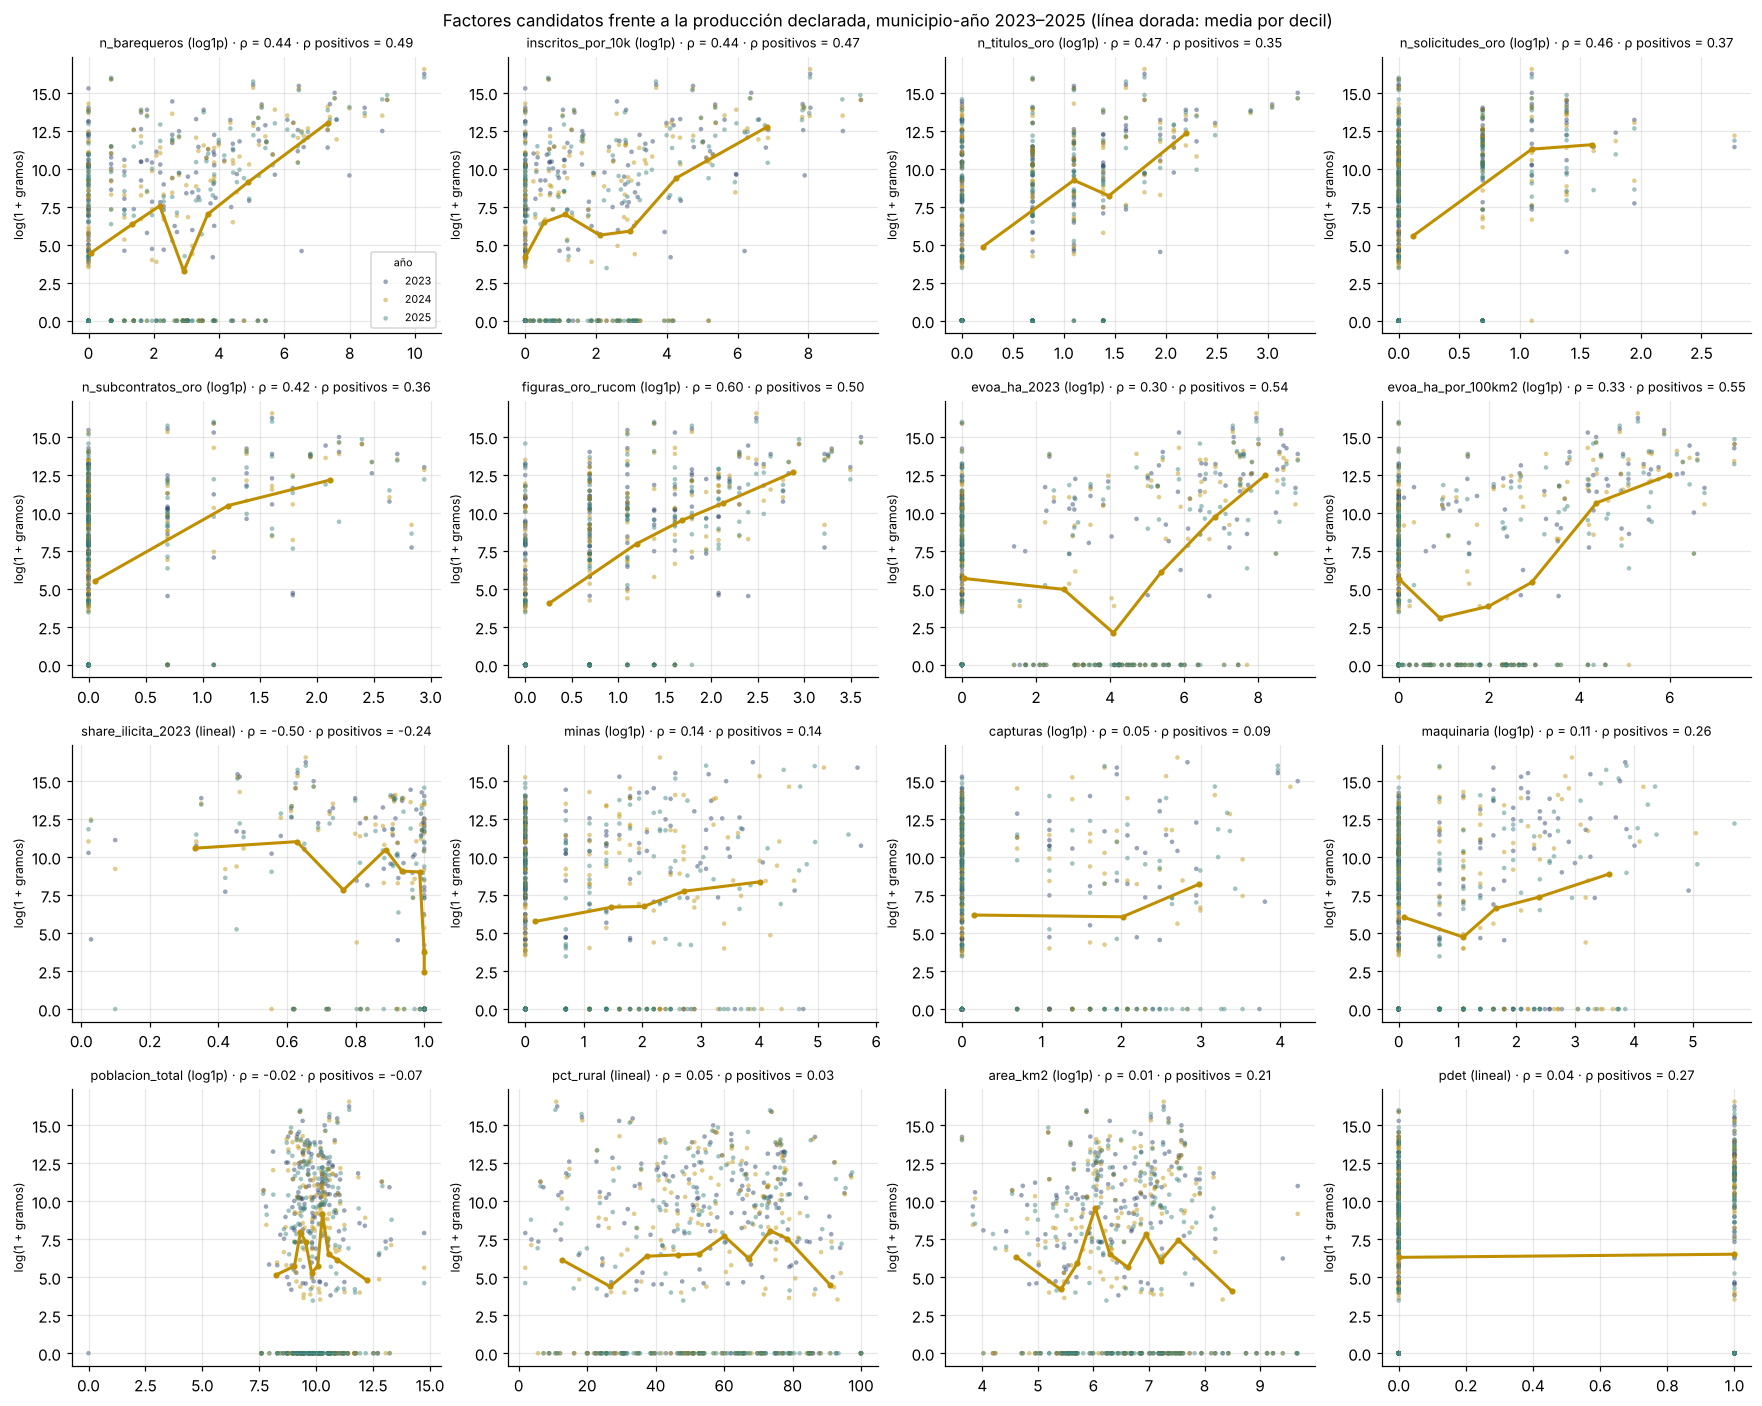

Correlación de rangos con la producción (todas las filas y solo las positivas):


,escala,spearman_con_log_gramos,spearman_solo_positivos,n
variable,,,,
n_barequeros,log1p,0.44,0.49,591
inscritos_por_10k,log1p,0.44,0.47,590
n_titulos_oro,log1p,0.47,0.35,591
n_solicitudes_oro,log1p,0.46,0.38,591
n_subcontratos_oro,log1p,0.42,0.36,591
figuras_oro_rucom,log1p,0.60,0.50,591
evoa_ha_2023,log1p,0.30,0.54,591
evoa_ha_por_100km2,log1p,0.33,0.55,588
share_ilicita_2023,lineal,-0.50,-0.24,303


In [21]:
COLOR_ANIO = {2023: AZUL, 2024: DORADO, 2025: TEAL}
y_log = np.log1p(amp.gramos_anm)
DISP = [("n_barequeros", "log1p"), ("inscritos_por_10k", "log1p"), ("n_titulos_oro", "log1p"), ("n_solicitudes_oro", "log1p"), ("n_subcontratos_oro", "log1p"), ("figuras_oro_rucom", "log1p"),
        ("evoa_ha_2023", "log1p"), ("evoa_ha_por_100km2", "log1p"), ("share_ilicita_2023", "lineal"), ("minas", "log1p"), ("capturas", "log1p"), ("maquinaria", "log1p"),
        ("poblacion_total", "log1p"), ("pct_rural", "lineal"), ("area_km2", "log1p"), ("pdet", "lineal")]

def spearman(a, b):
    """Correlación de rangos sin scipy: Pearson sobre los rangos promedio, ignorando pares con faltantes."""
    d = pd.DataFrame({"a": np.asarray(a, float), "b": np.asarray(b, float)}).dropna()
    return d.a.rank().corr(d.b.rank())

def medias_por_decil(x, y, q=10):
    """Media de y en cada decil de x (los empates, como los ceros, caen en un solo grupo)."""
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    if d.x.nunique() < 3:
        g = d.groupby("x").y.mean()
        return g.index.values, g.values
    d["b"] = pd.qcut(d.x, q, labels=False, duplicates="drop")
    g = d.groupby("b").agg(x=("x", "mean"), y=("y", "mean"))
    return g.x.values, g.y.values

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
filas_rho = []
for ax, (c, esc) in zip(axes.ravel(), DISP):
    x = np.log1p(amp[c]) if esc == "log1p" else amp[c]
    for a in ANIOS:
        m = amp.anio == a
        ax.scatter(x[m], y_log[m], s=9, alpha=0.45, color=COLOR_ANIO[a], label=str(a), edgecolor="none")
    bx, by = medias_por_decil(x, y_log)
    ax.plot(bx, by, color=DORADO, lw=2, marker="o", ms=3, zorder=5)
    rho = spearman(x, y_log)
    rho_pos = spearman(x[amp.gramos_anm > 0], y_log[amp.gramos_anm > 0])
    filas_rho.append((c, esc, rho, rho_pos, int(x.notna().sum())))
    ax.set_title(f"{c} ({'log1p' if esc == 'log1p' else 'lineal'}) · ρ = {rho:.2f} · ρ positivos = {rho_pos:.2f}", fontsize=8.5)
    ax.set_ylabel("log(1 + gramos)", fontsize=8)
axes[0, 0].legend(fontsize=7, title="año", title_fontsize=7)
plt.suptitle("Factores candidatos frente a la producción declarada, municipio-año 2023–2025 (línea dorada: media por decil)", fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_candidatas_dispersion_2023_2025.png", dpi=160, bbox_inches="tight")
plt.show()

rho_tab = pd.DataFrame(filas_rho, columns=["variable", "escala", "spearman_con_log_gramos", "spearman_solo_positivos", "n"]).set_index("variable").round(3)
print("Correlación de rangos con la producción (todas las filas y solo las positivas):")
display(rho_tab)
rho_tab.to_csv(SAL / "candidatas_spearman_con_respuesta_2023_2025.csv")

### 8.8 Matriz de dispersión de los factores principales (197 municipios)

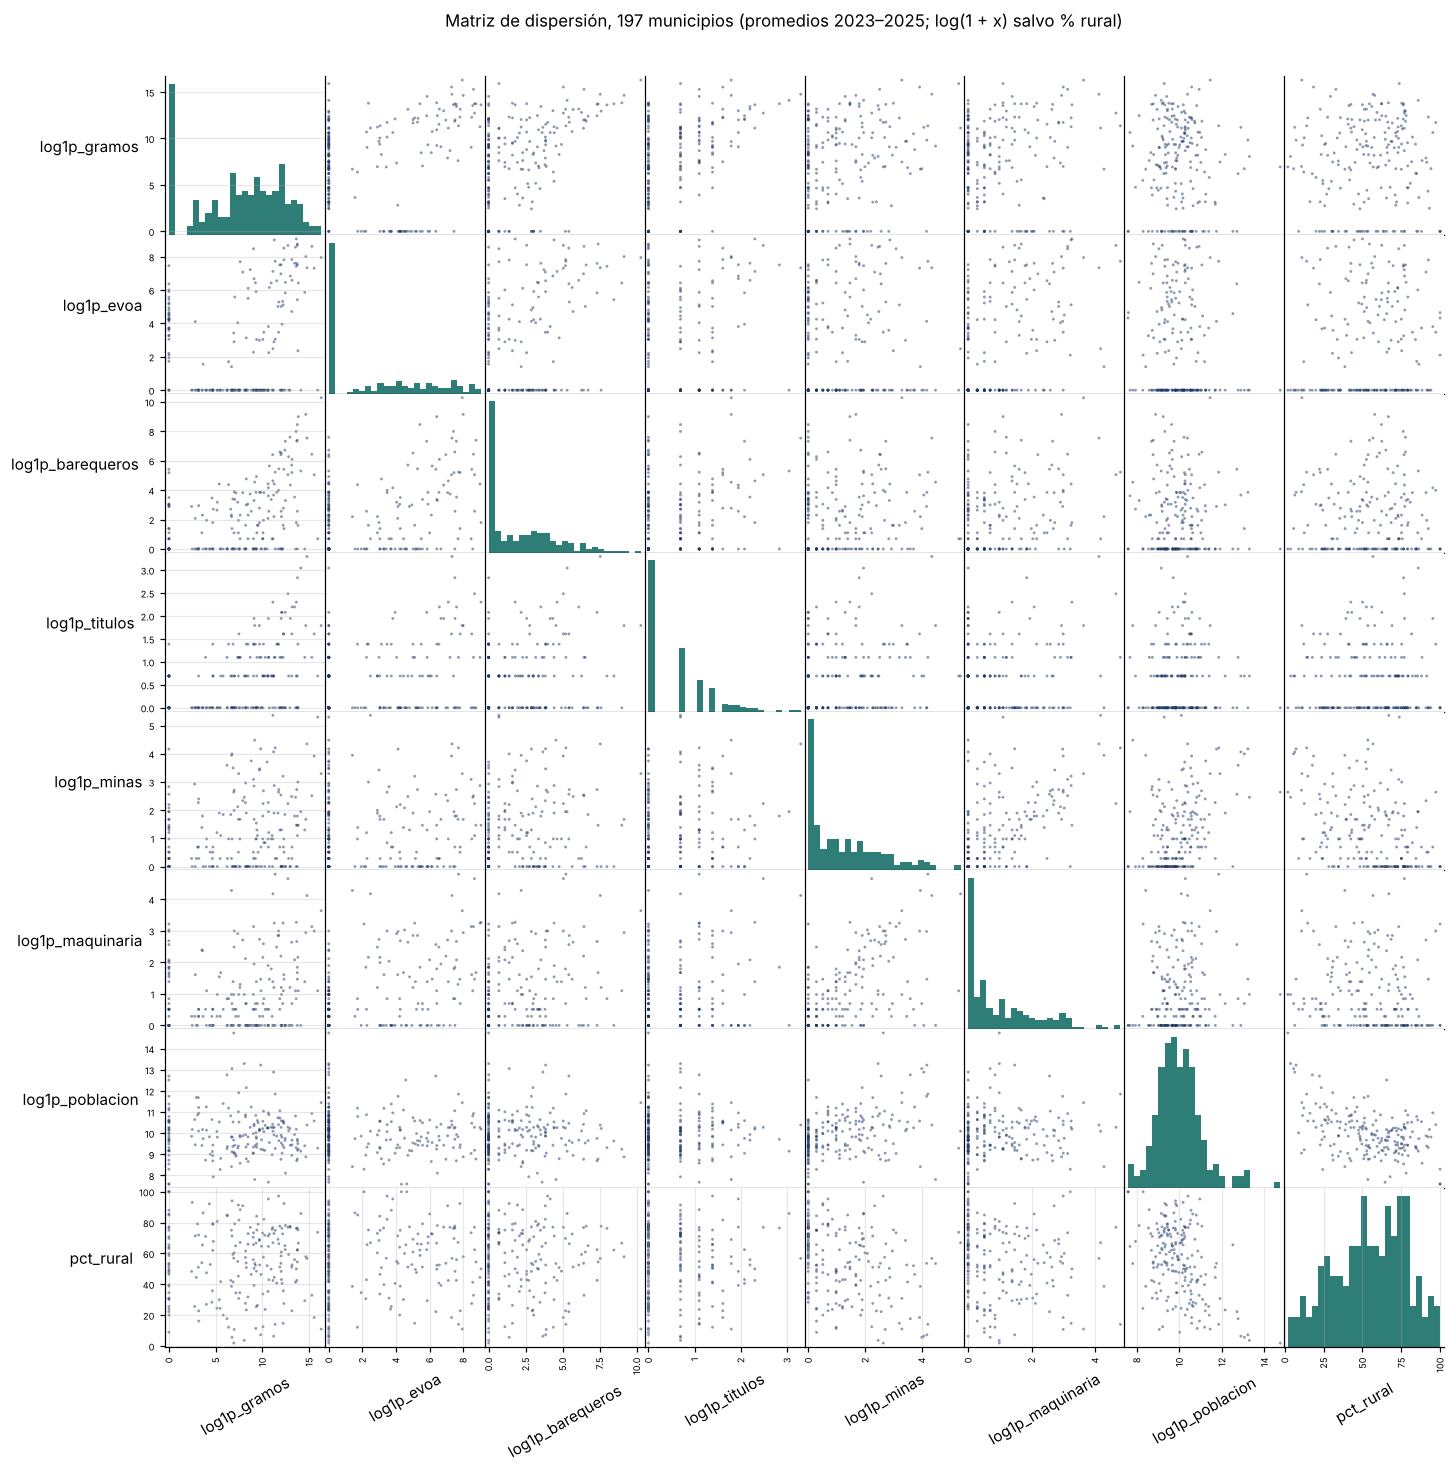

In [22]:
m3 = amp.groupby("codigo_dane").agg(gramos=("gramos_anm", "mean"), evoa=("evoa_ha_2023", "first"), barequeros=("n_barequeros", "first"), titulos=("n_titulos_oro", "first"),
                                    minas=("minas", "mean"), maquinaria=("maquinaria", "mean"), poblacion=("poblacion_total", "mean"), pct_rural=("pct_rural", "mean"))
m3l = np.log1p(m3.drop(columns="pct_rural")).add_prefix("log1p_").join(m3.pct_rural)
axs = pd.plotting.scatter_matrix(m3l, figsize=(15, 15), diagonal="hist", color=AZUL, alpha=0.5, s=14, hist_kwds={"bins": 25, "color": TEAL})
for a in axs.ravel():
    a.xaxis.label.set_rotation(30)
    a.yaxis.label.set_rotation(0)
    a.yaxis.label.set_ha("right")
    a.tick_params(labelsize=6)
plt.suptitle("Matriz de dispersión, 197 municipios (promedios 2023–2025; log(1 + x) salvo % rural)", y=0.92, fontsize=11)
plt.savefig(FIG_DIR / "fig_candidatas_matriz_dispersion_municipio.png", dpi=130, bbox_inches="tight")
plt.show()

### 8.9 Matriz de regresores en la escala de la Tabla 3 (13 columnas; proporción sin figura de ley centrada)

In [23]:
def matriz_regresores(df):
    X = pd.DataFrame(index=df.index)
    X["log1p_evoa_ha_2023"] = np.log1p(df.evoa_ha_2023)
    con_huella = df.share_ilicita_2023.notna()                             # la proporción solo existe donde hay huella
    X["share_ilicita_c"] = np.where(con_huella, df.share_ilicita_2023 - SHARE_MEDIA, 0.0)   # centrada entre los municipios con huella y 0 sin huella
    X["log1p_n_barequeros"] = np.log1p(df.n_barequeros)
    X["log1p_n_titulos_oro"] = np.log1p(df.n_titulos_oro)
    X["log1p_n_solicitudes_oro"] = np.log1p(df.n_solicitudes_oro)
    X["log1p_n_subcontratos_oro"] = np.log1p(df.n_subcontratos_oro)
    X["log1p_minas"] = np.log1p(df.minas)
    X["log1p_capturas"] = np.log1p(df.capturas)
    X["log1p_maquinaria"] = np.log1p(df.maquinaria)
    X["log_poblacion"] = np.log(df.poblacion_total.replace(0, np.nan))
    X["pct_rural"] = df.pct_rural
    X["log_area_km2"] = np.log(df.area_km2)
    X["pdet"] = df.pdet.astype(float)
    return X

SHARE_MEDIA = float(amp.drop_duplicates("codigo_dane").share_ilicita_2023.mean())   # media de la proporción sin figura de ley entre los 101 municipios con huella
REGRESORES = list(matriz_regresores(amp.head(1)).columns)
X_all = matriz_regresores(amp)
y_all = np.log1p(amp.gramos_anm)
print(f"Proporción de huella sin figura de ley: media entre municipios con huella = {SHARE_MEDIA:.3f}; en los modelos entra centrada en ese valor (0 donde no hay huella).")
print(f"Regresores ({len(REGRESORES)}): " + ", ".join(REGRESORES))

Proporción de huella sin figura de ley: media entre municipios con huella = 0.848; en los modelos entra centrada en ese valor (0 donde no hay huella).
Regresores (13): log1p_evoa_ha_2023, share_ilicita_c, log1p_n_barequeros, log1p_n_titulos_oro, log1p_n_solicitudes_oro, log1p_n_subcontratos_oro, log1p_minas, log1p_capturas, log1p_maquinaria, log_poblacion, pct_rural, log_area_km2, pdet


### 8.10 Spearman entre regresores y mapa de calor

Pares de regresores con |Spearman| > 0,6:


'ninguno'

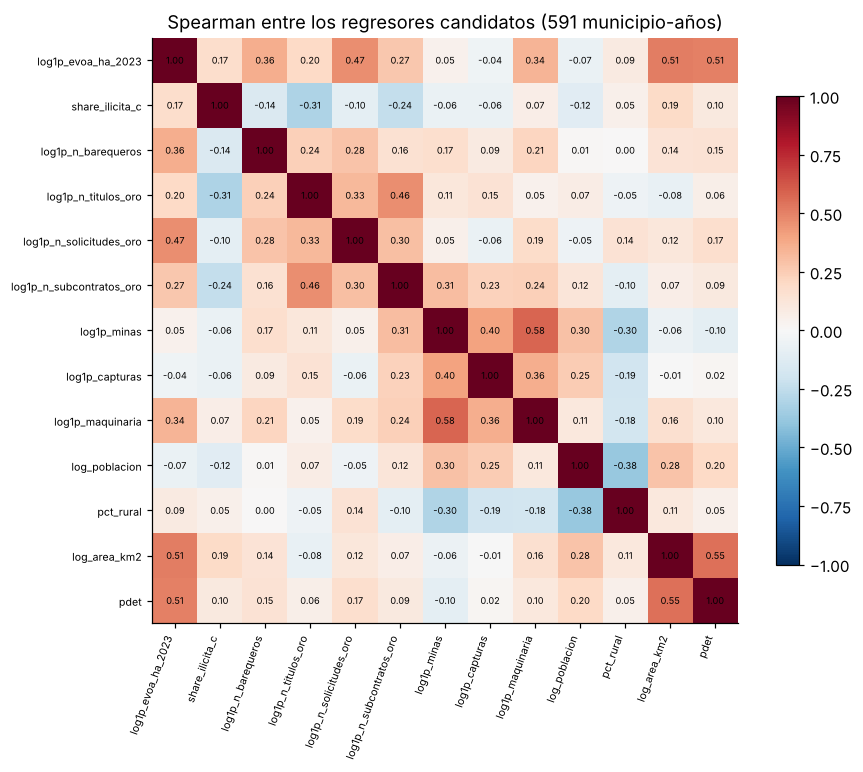

In [24]:
corr_x = X_all.corr(method="spearman")
pares = [(a, b, corr_x.loc[a, b]) for i, a in enumerate(REGRESORES) for b in REGRESORES[i + 1:] if abs(corr_x.loc[a, b]) > 0.6]
print("Pares de regresores con |Spearman| > 0,6:")
display(pd.DataFrame(pares, columns=["variable_1", "variable_2", "spearman"]).round(2) if pares else "ninguno")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr_x.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(REGRESORES)))
ax.set_xticklabels(REGRESORES, rotation=70, ha="right", fontsize=7)
ax.set_yticks(range(len(REGRESORES)))
ax.set_yticklabels(REGRESORES, fontsize=7)
for i in range(len(REGRESORES)):
    for j in range(len(REGRESORES)):
        ax.text(j, i, f"{corr_x.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman entre los regresores candidatos (591 municipio-años)")
plt.tight_layout()
plt.show()

### 8.11 VIF, número de condición y regla de eventos por parámetro

In [25]:
def vif_tabla(X):
    Z = X.dropna()
    Z = (Z - Z.mean()) / Z.std(ddof=0)
    filas = []
    for c in Z.columns:
        otros = Z.drop(columns=c).values
        A = np.column_stack([np.ones(len(Z)), otros])
        beta, *_ = np.linalg.lstsq(A, Z[c].values, rcond=None)
        r2 = 1 - ((Z[c].values - A @ beta) ** 2).sum() / ((Z[c].values - Z[c].values.mean()) ** 2).sum()
        filas.append((c, 1 / (1 - r2) if r2 < 1 else np.inf, r2))
    cond = np.linalg.cond(np.column_stack([np.ones(len(Z)), Z.values]))
    return pd.DataFrame(filas, columns=["regresor", "VIF", "R2_sobre_los_demas"]).set_index("regresor"), cond, len(Z)

vif, numero_condicion, n_vif = vif_tabla(X_all)
print(f"Factores de inflación de la varianza (n = {n_vif} filas completas; número de condición de la matriz estandarizada = {numero_condicion:.1f}):")
display(vif.round(2))
check("Candidatas", "Ningún regresor del conjunto de referencia tiene VIF > 5 y el número de condición es < 30", (vif.VIF < 5).all() and numero_condicion < 30, f"VIF máx = {vif.VIF.max():.2f} ({vif.VIF.idxmax()}); condición = {numero_condicion:.1f}")

n_ceros = int((amp.gramos_anm == 0).sum())
n_nunca = int((amp.groupby("codigo_dane").gramos_anm.sum() == 0).sum())
print(f"Regla de eventos por parámetro (Peduzzi et al., 1996): municipio-años sin declaración = {n_ceros} → admite ~{n_ceros // 10} parámetros en la parte de participación; municipios que nunca declaran = {n_nunca}")

vif.to_csv(SAL / "candidatas_vif_2023_2025.csv")
corr_x.round(3).to_csv(SAL / "candidatas_spearman_entre_regresores_2023_2025.csv")

Factores de inflación de la varianza (n = 588 filas completas; número de condición de la matriz estandarizada = 3.5):


,VIF,R2_sobre_los_demas
regresor,,
log1p_evoa_ha_2023,2.57,0.61
share_ilicita_c,1.24,0.19
log1p_n_barequeros,1.33,0.25
log1p_n_titulos_oro,1.54,0.35
log1p_n_solicitudes_oro,1.53,0.34
log1p_n_subcontratos_oro,1.75,0.43
log1p_minas,2.06,0.51
log1p_capturas,1.33,0.25
log1p_maquinaria,1.98,0.50


[OK     ] Ningún regresor del conjunto de referencia tiene VIF > 5 y el número de condición es < 30 — VIF máx = 2.57 (log1p_evoa_ha_2023); condición = 3.5
Regla de eventos por parámetro (Peduzzi et al., 1996): municipio-años sin declaración = 213 → admite ~21 parámetros en la parte de participación; municipios que nunca declaran = 34


## 9. Modelo de referencia B1: funciones de MCO con errores agrupados por municipio, métricas y AUC

In [26]:
from math import erfc, sqrt

SEMILLA = 2025

def p_normal(t):
    """Valor p bilateral con aproximación normal (con 197 grupos la t de Student es casi idéntica)."""
    return erfc(abs(t) / sqrt(2))

def ols(X, y, grupos=None):
    """Mínimos cuadrados ordinarios. X debe traer la columna de unos.
    grupos: etiquetas de municipio para errores agrupados; si no se dan, errores robustos HC1."""
    X = np.asarray(X, float)
    y = np.asarray(y, float)
    n, k = X.shape
    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    if grupos is None:
        V = XtX_inv @ ((X * e[:, None] ** 2).T @ X) @ XtX_inv * n / (n - k)
        G = None
    else:
        g = pd.factorize(pd.Series(grupos))[0]
        G = g.max() + 1
        S = np.zeros((k, k))
        for j in range(G):
            u = X[g == j].T @ e[g == j]
            S += np.outer(u, u)
        V = XtX_inv @ S @ XtX_inv * (G / (G - 1)) * ((n - 1) / (n - k))
    se = np.sqrt(np.diag(V))
    t = beta / se
    sst = ((y - y.mean()) ** 2).sum()
    sse = (e ** 2).sum()
    r2 = 1 - sse / sst
    return {"beta": beta, "se": se, "t": t, "p": np.array([p_normal(v) for v in t]),
            "r2": r2, "r2_adj": 1 - (1 - r2) * (n - 1) / (n - k),
            "rmse": sqrt(sse / n), "mae": np.abs(e).mean(),
            "resid": e, "fitted": X @ beta, "n": n, "k": k, "G": None if G is None else int(G)}

def tabla_coef(res, nombres):
    """Coeficientes, errores agrupados, t, valor p e intervalos del 95 %."""
    t = pd.DataFrame({"coef": res["beta"], "ee_agrupado": res["se"], "t": res["t"], "p": res["p"]}, index=nombres)
    t["IC95_inf"] = t.coef - 1.96 * t.ee_agrupado
    t["IC95_sup"] = t.coef + 1.96 * t.ee_agrupado
    return t

def metricas(y, yhat, y_ref_media=None):
    """RMSE, MAE y R² de una predicción. y_ref_media fija la media de referencia del R² (útil en validación)."""
    y = np.asarray(y, float)
    yhat = np.asarray(yhat, float)
    e = y - yhat
    m = y.mean() if y_ref_media is None else y_ref_media
    return {"RMSE": sqrt((e ** 2).mean()), "MAE": np.abs(e).mean(), "R2": 1 - (e ** 2).sum() / ((y - m) ** 2).sum()}

def auc_rangos(score, y):
    """Área bajo la curva ROC calculada con rangos (equivale al estadístico de Mann-Whitney)."""
    s = pd.Series(score).rank()
    pos = y == 1
    n1, n0 = pos.sum(), (~pos).sum()
    return (s[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

### 9.1 Datos del modelo: log(1 + gramos), 13 regresores y efectos de año (588 filas)

In [27]:
base = pd.concat(
    [amp.drop(columns=[c for c in amp.columns if c in X_all.columns]).assign(y=np.log1p(amp.gramos_anm)), X_all],
    axis=1,
)
base["anio_2024"] = (base.anio == 2024).astype(float)
base["anio_2025"] = (base.anio == 2025).astype(float)
COLS_X = REGRESORES + ["anio_2024", "anio_2025"]
NOMBRES = ["constante"] + COLS_X

excl = base[base[COLS_X].isna().any(axis=1)]
base = base.dropna(subset=COLS_X).copy()
print(f"Filas usadas: {len(base)} de 591 (excluidas {len(excl)}: {sorted(set(excl.municipio))}, sin área en el MGN 2024 o población cero en 2023)")

X1 = np.column_stack([np.ones(len(base)), base[COLS_X].values])   # matriz de diseño con la constante
print(f"Respuesta: log(1 + gramos_anm) · {len(REGRESORES)} regresores + 2 efectos de año + constante = {X1.shape[1]} parámetros")

papel = ["control" if c in ("log_poblacion", "pct_rural", "log_area_km2", "pdet") else "efecto de año" if c.startswith("anio_") else "factor activo" for c in COLS_X]
display(pd.DataFrame({"regresor": COLS_X, "papel": papel}).set_index("regresor"))

Filas usadas: 588 de 591 (excluidas 3: ['MUNICIPIO NUEVO BELEN DE BAJIRA'], sin área en el MGN 2024 o población cero en 2023)
Respuesta: log(1 + gramos_anm) · 13 regresores + 2 efectos de año + constante = 16 parámetros


,papel
regresor,
log1p_evoa_ha_2023,factor activo
share_ilicita_c,factor activo
log1p_n_barequeros,factor activo
log1p_n_titulos_oro,factor activo
log1p_n_solicitudes_oro,factor activo
log1p_n_subcontratos_oro,factor activo
log1p_minas,factor activo
log1p_capturas,factor activo
log1p_maquinaria,factor activo


### 9.2 Estimación de B1: R² y RMSE frente al modelo nulo, tabla de coeficientes

In [28]:
B1 = ols(X1, base.y, grupos=base.codigo_dane)
coef1 = tabla_coef(B1, NOMBRES)
B0 = metricas(base.y, np.full(len(base), base.y.mean()))   # modelo nulo: solo la media

print(f"B1 · MCO agrupado: log(1 + gramos) ~ 13 factores + efectos de año · n = {B1['n']}, k = {B1['k']}, {B1['G']} municipios")
print(f"R² = {B1['r2']:.3f} · R² ajustado = {B1['r2_adj']:.3f} · RMSE = {B1['rmse']:.2f} · MAE = {B1['mae']:.2f} (en unidades de log; la desv. est. de y es {base.y.std():.2f})")
print(f"Modelo nulo (solo la media): RMSE = {B0['RMSE']:.2f} · MAE = {B0['MAE']:.2f}")
check("Benchmark", "La regresión de referencia mejora al modelo nulo en RMSE al menos un 20 %", B1["rmse"] <= 0.8 * B0["RMSE"], f"{(1 - B1['rmse'] / B0['RMSE']) * 100:.0f} % menos de RMSE")

print("\nCoeficientes (errores estándar agrupados por municipio):")
display(coef1.round(3))

B1 · MCO agrupado: log(1 + gramos) ~ 13 factores + efectos de año · n = 588, k = 16, 196 municipios
R² = 0.461 · R² ajustado = 0.447 · RMSE = 3.93 · MAE = 3.34 (en unidades de log; la desv. est. de y es 5.35)
Modelo nulo (solo la media): RMSE = 5.35 · MAE = 4.86
[OK     ] La regresión de referencia mejora al modelo nulo en RMSE al menos un 20 % — 27 % menos de RMSE

Coeficientes (errores estándar agrupados por municipio):


,coef,ee_agrupado,t,p,IC95_inf,IC95_sup
constante,5.16,2.96,1.75,0.08,-0.64,10.95
log1p_evoa_ha_2023,0.09,0.13,0.67,0.50,-0.17,0.34
share_ilicita_c,-2.49,1.78,-1.40,0.16,-5.97,1.00
log1p_n_barequeros,0.69,0.12,5.59,0.00,0.45,0.93
log1p_n_titulos_oro,1.74,0.41,4.29,0.00,0.95,2.54
log1p_n_solicitudes_oro,1.97,0.55,3.58,0.00,0.89,3.06
log1p_n_subcontratos_oro,1.11,0.51,2.20,0.03,0.12,2.11
log1p_minas,0.47,0.26,1.84,0.07,-0.03,0.98
log1p_capturas,-0.04,0.20,-0.21,0.83,-0.43,0.35
log1p_maquinaria,-0.43,0.24,-1.81,0.07,-0.89,0.04


### 9.3 Gráfico de coeficientes con intervalos del 95 %

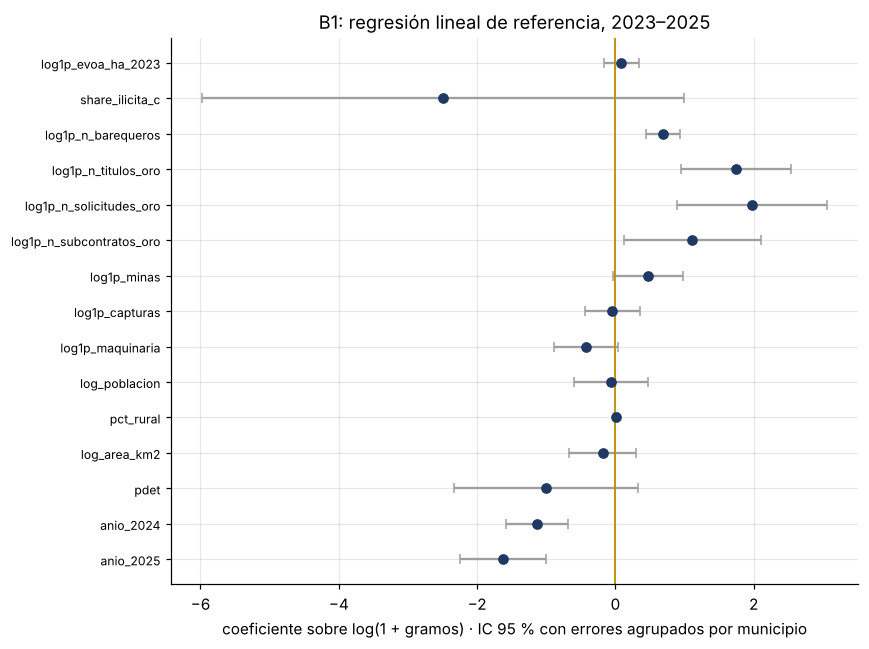

In [29]:
cp = coef1.drop(index="constante").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(cp.coef, range(len(cp)), xerr=1.96 * cp.ee_agrupado, fmt="o", color=AZUL, ecolor=GRIS, capsize=3)
ax.axvline(0, color=DORADO, lw=1.2)
ax.set_yticks(range(len(cp)))
ax.set_yticklabels(cp.index, fontsize=8)
ax.set_xlabel("coeficiente sobre log(1 + gramos) · IC 95 % con errores agrupados por municipio")
ax.set_title("B1: regresión lineal de referencia, 2023–2025")
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_benchmark_coeficientes.png", dpi=160, bbox_inches="tight")
plt.show()

### 9.4 Diagnóstico gráfico: predicho frente a observado, residuos e histograma

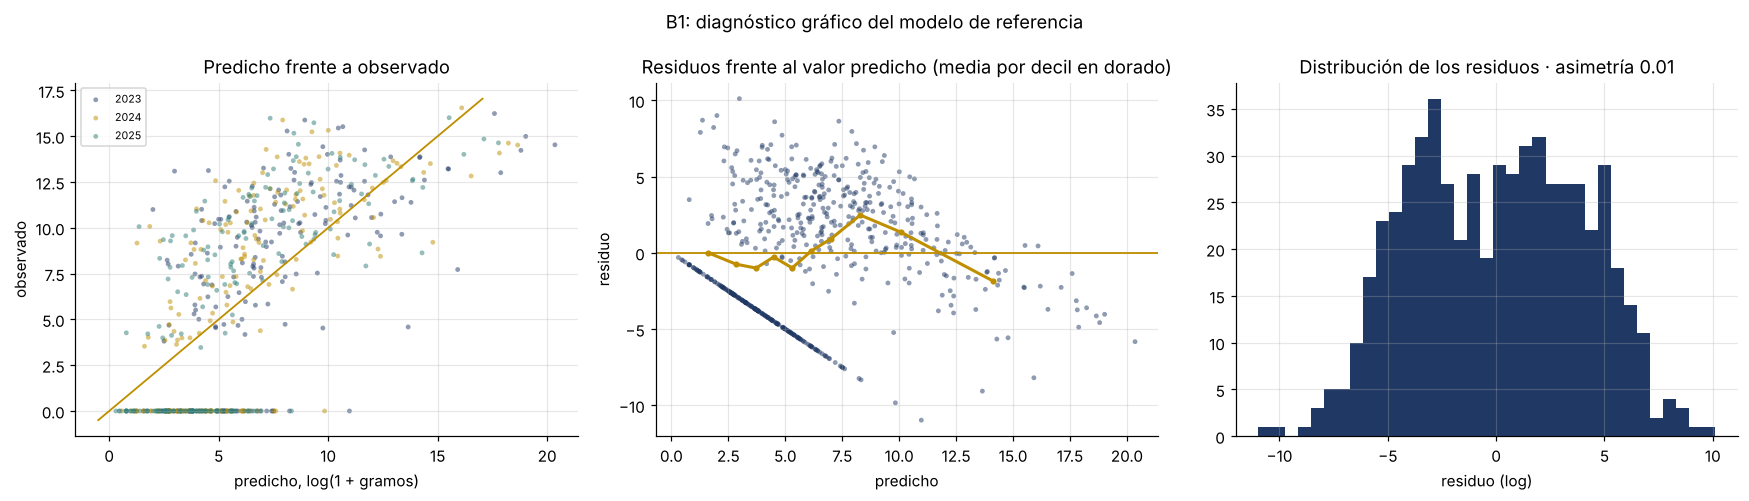

In [30]:
base["ajustado"] = B1["fitted"]
base["residuo"] = B1["resid"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
for a in ANIOS:
    m = base.anio == a
    ax.scatter(base.ajustado[m], base.y[m], s=10, alpha=0.5, color=COLOR_ANIO[a], label=str(a), edgecolor="none")
lim = [min(base.ajustado.min(), 0) - 0.5, base.y.max() + 0.5]
ax.plot(lim, lim, color=DORADO, lw=1.2)
ax.set_xlabel("predicho, log(1 + gramos)")
ax.set_ylabel("observado")
ax.set_title("Predicho frente a observado")
ax.legend(fontsize=7)

ax = axes[1]
ax.scatter(base.ajustado, base.residuo, s=10, alpha=0.5, color=AZUL, edgecolor="none")
ax.axhline(0, color=DORADO, lw=1.2)
bx, by = medias_por_decil(base.ajustado, base.residuo)
ax.plot(bx, by, color=DORADO, lw=2, marker="o", ms=3)
ax.set_xlabel("predicho")
ax.set_ylabel("residuo")
ax.set_title("Residuos frente al valor predicho (media por decil en dorado)")

ax = axes[2]
ax.hist(base.residuo, bins=35, color=AZUL)
ax.set_title(f"Distribución de los residuos · asimetría {base.residuo.skew():.2f}")
ax.set_xlabel("residuo (log)")

plt.suptitle("B1: diagnóstico gráfico del modelo de referencia")
plt.tight_layout()
fig.savefig(FIG_DIR / "fig_benchmark_diagnostico.png", dpi=160, bbox_inches="tight")
plt.show()

### 9.5 Residuos y predicciones en los ceros frente a los positivos

In [31]:
ceros = base[base.gramos_anm == 0]
positivos = base[base.gramos_anm > 0]
print(f"Residuo medio en los municipio-años en cero: {ceros.residuo.mean():+.2f} (n = {len(ceros)}); en los positivos: {positivos.residuo.mean():+.2f} (n = {len(positivos)})")
print(f"Predicción media para los que declaran cero: {ceros.ajustado.mean():.2f} en log (≈ {np.expm1(ceros.ajustado.mean()):,.0f} g); "
      f"para los positivos: {positivos.ajustado.mean():.2f} (≈ {np.expm1(positivos.ajustado.mean())/1000:,.1f} kg).")
print("El modelo lineal no reproduce la masa en cero: es lo que motiva el modelo en dos partes (M1 + M2).")
check("Benchmark", "Los residuos del modelo lineal tienen media distinta por grupo (cero frente a positivos): el benchmark no captura la masa en cero", abs(ceros.residuo.mean() - positivos.residuo.mean()) > 1, f"diferencia de medias = {ceros.residuo.mean() - positivos.residuo.mean():+.2f}")

Residuo medio en los municipio-años en cero: -3.89 (n = 212); en los positivos: +2.19 (n = 376)
Predicción media para los que declaran cero: 3.89 en log (≈ 48 g); para los positivos: 7.76 (≈ 2.4 kg).
El modelo lineal no reproduce la masa en cero: es lo que motiva el modelo en dos partes (M1 + M2).
[OK     ] Los residuos del modelo lineal tienen media distinta por grupo (cero frente a positivos): el benchmark no captura la masa en cero — diferencia de medias = -6.09


### 9.6 Residuo medio por municipio: los extremos

In [32]:
res_mun = (base.groupby(["codigo_dane", "municipio", "departamento"])
           .agg(residuo_medio=("residuo", "mean"), produccion_kg=("gramos_anm", lambda s: s.sum() / 1000), predicho_log=("ajustado", "mean"), tipo=("tipo_predominante", "first"))
           .reset_index()
           .sort_values("residuo_medio"))
print("Municipios que declaran MÁS de lo que los factores observables predicen (residuo medio más alto, 2023–2025):")
display(res_mun.tail(8).iloc[::-1].round(2))
print("Municipios que declaran MENOS de lo que predicen los factores (residuo medio más bajo):")
display(res_mun.head(8).round(2))
print("Lectura obligada: son prioridades de lectura y verificación, no imputaciones de conducta (introducción y etapa 5 del documento).")
res_mun.to_csv(SAL / "benchmark_residuos_por_municipio_2023_2025.csv", index=False)

Municipios que declaran MÁS de lo que los factores observables predicen (residuo medio más alto, 2023–2025):


,codigo_dane,municipio,departamento,residuo_medio,produccion_kg,predicho_log,tipo
59,13212,Cordoba - Bolivar,Bolívar,9.01,532.79,2.07,aluvión con barequeo
12,05113,Buritica,Antioquia,7.85,"24,550.93",8.07,veta / títulos
125,27425,Medio Atrato,Chocó,7.29,664.05,4.90,otros
152,52621,Roberto Payan,Nariño,7.24,578.06,4.01,aluvión con barequeo
47,05858,Vegachi,Antioquia,6.45,"6,134.14",7.48,aluvión con barequeo
121,27245,El Carmen de Atrato,Chocó,6.07,24.43,2.85,aluvión con barequeo
24,05250,El Bagre,Antioquia,5.90,"13,130.37",9.38,aluvión con títulos
134,27745,Sipi,Chocó,5.78,778.11,6.13,aluvión con barequeo


Municipios que declaran MENOS de lo que predicen los factores (residuo medio más bajo):


,codigo_dane,municipio,departamento,residuo_medio,produccion_kg,predicho_log,tipo
45,05854,Valdivia,Antioquia,-7.12,0.00,7.12,huella sin declaración
149,52385,La Llanada,Nariño,-6.92,11.80,10.05,veta / títulos
42,05756,Sonson,Antioquia,-6.57,0.00,6.57,huella sin declaración
105,19809,Timbiqui,Cauca,-6.47,17.87,14.99,otros
151,52427,Magüi,Nariño,-6.43,0.00,6.43,huella sin declaración
181,76109,Buenaventura,Valle del Cauca,-6.36,0.00,6.36,huella sin declaración
80,17380,La Dorada,Caldas,-5.20,1.77,7.70,aluvión con barequeo
150,52418,Los Andes,Nariño,-5.15,0.00,5.15,huella sin declaración


Lectura obligada: son prioridades de lectura y verificación, no imputaciones de conducta (introducción y etapa 5 del documento).


### 9.7 Validación fuera de periodo: 2023–2024 → 2025 frente a persistencia y media

In [33]:
ent = base[base.anio <= 2024]
val = base[base.anio == 2025]
Xe = np.column_stack([np.ones(len(ent)), ent[REGRESORES].values])
Xv = np.column_stack([np.ones(len(val)), val[REGRESORES].values])
Bt = ols(Xe, ent.y, grupos=ent.codigo_dane)
pred_2025 = Xv @ Bt["beta"]

y24 = base[base.anio == 2024].set_index("codigo_dane").y
persist = val.codigo_dane.map(y24).values          # persistencia: lo que el municipio declaró en 2024
m_ref = ent.y.mean()                               # media de entrenamiento

val_tab = pd.DataFrame({
    "B1 sin efectos de año (2023–2024 → 2025)": metricas(val.y, pred_2025, m_ref),
    "persistencia (y_2025 = y_2024)": metricas(val.y, persist, m_ref),
    "media de entrenamiento": metricas(val.y, np.full(len(val), m_ref), m_ref),
}).T.round(3)
print(f"Validación fuera de periodo, 2025 (n = {len(val)}):")
display(val_tab)
check("Benchmark", "Fuera de periodo (2025) la regresión supera a la media de entrenamiento", val_tab.loc["B1 sin efectos de año (2023–2024 → 2025)", "RMSE"] < val_tab.loc["media de entrenamiento", "RMSE"])
print("Nota: la persistencia gana porque el 82 % de la varianza está entre municipios; un modelo sin efecto de municipio no puede superarla. Es el argumento del documento para Mundlak y los efectos de municipio.")

Validación fuera de periodo, 2025 (n = 196):


,RMSE,MAE,R2
B1 sin efectos de año (2023–2024 → 2025),4.06,3.47,0.46
persistencia (y_2025 = y_2024),3.59,2.04,0.58
media de entrenamiento,5.53,5.03,0.00


[OK     ] Fuera de periodo (2025) la regresión supera a la media de entrenamiento
Nota: la persistencia gana porque el 82 % de la varianza está entre municipios; un modelo sin efecto de municipio no puede superarla. Es el argumento del documento para Mundlak y los efectos de municipio.


### 9.8 Validación por cinco bloques de municipios (semilla 2025) y AUC

In [34]:
rng = np.random.default_rng(SEMILLA)
codigos = np.array(sorted(base.codigo_dane.unique()))
rng.shuffle(codigos)
bloques = {c: i % 5 for i, c in enumerate(codigos)}
base["bloque"] = base.codigo_dane.map(bloques)

pred_oof = pd.Series(index=base.index, dtype=float)
for b in range(5):
    tr, te = base[base.bloque != b], base[base.bloque == b]
    Xt = np.column_stack([np.ones(len(tr)), tr[COLS_X].values])
    Xs = np.column_stack([np.ones(len(te)), te[COLS_X].values])
    pred_oof[te.index] = Xs @ ols(Xt, tr.y)["beta"]

oof = metricas(base.y, pred_oof)
ins = metricas(base.y, base.ajustado)
cv_tab = pd.DataFrame({
    "B1 dentro de muestra": ins,
    "B1 fuera de muestra (5 bloques de municipios)": oof,
    "modelo nulo": metricas(base.y, np.full(len(base), base.y.mean())),
}).T.round(3)
print(f"Validación por bloques de municipios (semilla {SEMILLA}):")
display(cv_tab)
check("Benchmark", "La pérdida de ajuste fuera de muestra es moderada (R² fuera de muestra ≥ 0,8 × R² dentro de muestra)", oof["R2"] >= 0.8 * ins["R2"], f"{oof['R2']:.3f} frente a {ins['R2']:.3f}")
print(f"\nEl valor predicho fuera de muestra ordena a los que declaran frente a los que no con AUC = {auc_rangos(pred_oof.values, base.declara.values):.3f}")

Validación por bloques de municipios (semilla 2025):


,RMSE,MAE,R2
B1 dentro de muestra,3.93,3.34,0.46
B1 fuera de muestra (5 bloques de municipios),4.23,3.59,0.37
modelo nulo,5.35,4.86,0.00


[OK     ] La pérdida de ajuste fuera de muestra es moderada (R² fuera de muestra ≥ 0,8 × R² dentro de muestra) — 0.374 frente a 0.461

El valor predicho fuera de muestra ordena a los que declaran frente a los que no con AUC = 0.798


### 9.9 Sensibilidad: sin los 12 municipios principales y sin Antioquia

In [35]:
top12 = amp.groupby("codigo_dane").gramos_anm.sum().nlargest(12).index
variantes = {
    "B1 completo": base,
    "sin los 12 municipios principales": base[~base.codigo_dane.isin(top12)],
    "sin Antioquia": base[base.departamento != "Antioquia"],
}
comp_var = {}
for nombre, d in variantes.items():
    Xd = np.column_stack([np.ones(len(d)), d[COLS_X].values])
    r = ols(Xd, d.y, grupos=d.codigo_dane)
    comp_var[nombre] = pd.Series(np.r_[r["beta"], r["r2"], r["n"]], index=NOMBRES + ["R2", "n"])
print("Coeficientes de B1 en la muestra completa y en las dos submuestras:")
display(pd.DataFrame(comp_var).round(2))

Coeficientes de B1 en la muestra completa y en las dos submuestras:


,B1 completo,sin los 12 municipios principales,sin Antioquia
constante,5.16,3.98,6.22
log1p_evoa_ha_2023,0.09,-0.04,0.04
share_ilicita_c,-2.49,-1.39,-2.42
log1p_n_barequeros,0.69,0.73,0.67
log1p_n_titulos_oro,1.74,1.91,1.26
log1p_n_solicitudes_oro,1.97,2.51,2.67
log1p_n_subcontratos_oro,1.11,1.12,1.16
log1p_minas,0.47,0.26,0.26
log1p_capturas,-0.04,-0.10,-0.09
log1p_maquinaria,-0.43,-0.27,-0.43


### 9.10 Estimador entre grupos (ecuación 23) y estabilidad de los signos

In [36]:
prom = base.groupby("codigo_dane").agg({c: "mean" for c in ["y"] + REGRESORES}).reset_index()
Xb = np.column_stack([np.ones(len(prom)), prom[REGRESORES].values])
Bb = ols(Xb, prom.y)                                        # errores HC1: una fila por municipio
comp_var["entre grupos (197 promedios)"] = pd.Series(np.r_[Bb["beta"], np.nan, np.nan, Bb["r2"], Bb["n"]], index=NOMBRES + ["R2", "n"])
comp = pd.DataFrame(comp_var)
print("Coeficientes por variante (los efectos de año no aplican al estimador entre grupos):")
display(comp.round(2))

signo = comp.drop(index=["constante", "anio_2024", "anio_2025", "R2", "n"]).apply(np.sign)
estables = signo.eq(signo.iloc[:, 0], axis=0).all(axis=1)
print("Variables cuyo signo se mantiene en las cuatro variantes:", ", ".join(estables[estables].index.tolist()))
print("Variables cuyo signo cambia:", ", ".join(estables[~estables].index.tolist()) or "ninguna")
check("Benchmark", "Los coeficientes de las figuras del RUCOM y de los barequeros conservan el signo sin los 12 principales y sin Antioquia", estables[["log1p_n_barequeros", "log1p_n_titulos_oro", "log1p_n_solicitudes_oro", "log1p_n_subcontratos_oro"]].all())

i_h = NOMBRES.index("log1p_evoa_ha_2023")
print(f"\nContraste transversal (entre grupos): R² = {Bb['r2']:.3f} sobre {Bb['n']} municipios; el coeficiente de la huella es {Bb['beta'][i_h]:+.2f} "
      f"(EE HC1 {Bb['se'][i_h]:.2f}, p = {Bb['p'][i_h]:.2f}). Es el piloto que decide si la huella entra como característica fija en M1 y M2.")

coef1.to_csv(SAL / "benchmark_ols_coeficientes_2023_2025.csv")
comp.round(4).to_csv(SAL / "benchmark_sensibilidad_coeficientes_2023_2025.csv")

Coeficientes por variante (los efectos de año no aplican al estimador entre grupos):


,B1 completo,sin los 12 municipios principales,sin Antioquia,entre grupos (197 promedios)
constante,5.16,3.98,6.22,4.75
log1p_evoa_ha_2023,0.09,-0.04,0.04,0.10
share_ilicita_c,-2.49,-1.39,-2.42,-2.54
log1p_n_barequeros,0.69,0.73,0.67,0.68
log1p_n_titulos_oro,1.74,1.91,1.26,1.74
log1p_n_solicitudes_oro,1.97,2.51,2.67,2.01
log1p_n_subcontratos_oro,1.11,1.12,1.16,1.05
log1p_minas,0.47,0.26,0.26,0.84
log1p_capturas,-0.04,-0.10,-0.09,-0.14
log1p_maquinaria,-0.43,-0.27,-0.43,-0.73


Variables cuyo signo se mantiene en las cuatro variantes: share_ilicita_c, log1p_n_barequeros, log1p_n_titulos_oro, log1p_n_solicitudes_oro, log1p_n_subcontratos_oro, log1p_minas, log1p_capturas, log1p_maquinaria, pct_rural, log_area_km2, pdet
Variables cuyo signo cambia: log1p_evoa_ha_2023, log_poblacion
[OK     ] Los coeficientes de las figuras del RUCOM y de los barequeros conservan el signo sin los 12 principales y sin Antioquia

Contraste transversal (entre grupos): R² = 0.548 sobre 196 municipios; el coeficiente de la huella es +0.10 (EE HC1 0.14, p = 0.45). Es el piloto que decide si la huella entra como característica fija en M1 y M2.


### 9.11 Parte 1: modelo lineal de probabilidad de declarar

In [37]:
Bp = ols(X1, base.declara, grupos=base.codigo_dane)
p_hat = Bp["fitted"]
exactitud = ((p_hat >= 0.5) == (base.declara == 1)).mean()
fuera_01 = ((p_hat < 0) | (p_hat > 1)).mean() * 100
print(f"Parte 1 · modelo lineal de probabilidad, declara ~ factores + año: R² = {Bp['r2']:.3f} · exactitud al 0,5 = {exactitud:.3f} · "
      f"AUC = {auc_rangos(p_hat, base.declara.values):.3f} · predicciones fuera de [0, 1]: {fuera_01:.0f} % (límite conocido del modelo lineal; M1 lo evita)")
coef_p = tabla_coef(Bp, NOMBRES)
print("Coeficientes (cambio en la probabilidad de declarar por unidad de la variable):")
display(coef_p.round(3))

Parte 1 · modelo lineal de probabilidad, declara ~ factores + año: R² = 0.290 · exactitud al 0,5 = 0.760 · AUC = 0.849 · predicciones fuera de [0, 1]: 9 % (límite conocido del modelo lineal; M1 lo evita)
Coeficientes (cambio en la probabilidad de declarar por unidad de la variable):


,coef,ee_agrupado,t,p,IC95_inf,IC95_sup
constante,0.42,0.28,1.52,0.13,-0.12,0.96
log1p_evoa_ha_2023,-0.01,0.01,-1.01,0.31,-0.03,0.01
share_ilicita_c,-0.27,0.14,-1.89,0.06,-0.54,0.01
log1p_n_barequeros,0.04,0.01,4.23,0.00,0.02,0.06
log1p_n_titulos_oro,0.13,0.04,3.73,0.00,0.06,0.20
log1p_n_solicitudes_oro,0.19,0.04,4.30,0.00,0.10,0.27
log1p_n_subcontratos_oro,0.07,0.04,1.88,0.06,-0.00,0.15
log1p_minas,0.03,0.02,1.70,0.09,-0.01,0.07
log1p_capturas,-0.02,0.02,-0.91,0.36,-0.05,0.02
log1p_maquinaria,-0.04,0.02,-1.78,0.08,-0.08,0.00


### 9.12 Parte 2: MCO de log(gramos) en los municipio-años positivos

In [38]:
pos = base[base.gramos_anm > 0]
Xpos = np.column_stack([np.ones(len(pos)), pos[COLS_X].values])
Bv = ols(Xpos, np.log(pos.gramos_anm), grupos=pos.codigo_dane)
print(f"Parte 2 · regresión de log(gramos) en los {len(pos)} municipio-años positivos: R² = {Bv['r2']:.3f} · RMSE = {Bv['rmse']:.2f} · MAE = {Bv['mae']:.2f} "
      f"(desv. est. de log gramos = {np.log(pos.gramos_anm).std():.2f})")
coef_v = tabla_coef(Bv, NOMBRES)
display(coef_v.round(3))

Parte 2 · regresión de log(gramos) en los 376 municipio-años positivos: R² = 0.469 · RMSE = 2.19 · MAE = 1.78 (desv. est. de log gramos = 3.01)


,coef,ee_agrupado,t,p,IC95_inf,IC95_sup
constante,9.47,2.08,4.56,0.00,5.40,13.53
log1p_evoa_ha_2023,0.25,0.08,3.10,0.00,0.09,0.41
share_ilicita_c,-0.02,1.00,-0.02,0.99,-1.97,1.94
log1p_n_barequeros,0.38,0.07,5.05,0.00,0.23,0.53
log1p_n_titulos_oro,0.73,0.23,3.25,0.00,0.29,1.18
log1p_n_solicitudes_oro,0.26,0.36,0.72,0.47,-0.45,0.97
log1p_n_subcontratos_oro,0.33,0.29,1.14,0.25,-0.23,0.89
log1p_minas,0.31,0.21,1.45,0.15,-0.11,0.72
log1p_capturas,0.14,0.13,1.07,0.28,-0.12,0.39
log1p_maquinaria,-0.18,0.18,-0.98,0.33,-0.54,0.18


### 9.13 Dos partes combinadas, evaluadas en log(1 + gramos)

In [39]:
p_c = np.clip(p_hat, 0, 1)
esp_dos_partes = p_c * (X1 @ Bv["beta"])
m2p = metricas(base.y, esp_dos_partes)
print(f"Dos partes combinadas (Pr × log-volumen esperado), evaluadas en log(1 + gramos): RMSE = {m2p['RMSE']:.2f} · MAE = {m2p['MAE']:.2f} · R² = {m2p['R2']:.3f} "
      f"(B1: RMSE {B1['rmse']:.2f}, R² {B1['r2']:.3f})")
print("La retransformación a gramos (exp con corrección de Duan) multiplica los errores de los municipios grandes y no se usa aquí como métrica; "
      "M2 trabaja directamente en la media de los gramos con Poisson PML y evita ese paso.")

Dos partes combinadas (Pr × log-volumen esperado), evaluadas en log(1 + gramos): RMSE = 3.92 · MAE = 3.34 · R² = 0.463 (B1: RMSE 3.93, R² 0.461)
La retransformación a gramos (exp con corrección de Duan) multiplica los errores de los municipios grandes y no se usa aquí como métrica; M2 trabaja directamente en la media de los gramos con Poisson PML y evita ese paso.


### 9.14 Tabla resumen de métricas del modelo de referencia

In [40]:
resumen = pd.DataFrame([
    ("B0 nulo (media)", "log(1 + gramos)", len(base), 1, B0["RMSE"], B0["MAE"], 0.0, np.nan, np.nan),
    ("B1 MCO agrupado + año", "log(1 + gramos)", B1["n"], B1["k"], B1["rmse"], B1["mae"], B1["r2"], oof["RMSE"], oof["R2"]),
    ("B1 sin año, 2023–24 → 2025", "log(1 + gramos), 2025", len(val), Bt["k"], val_tab.iloc[0]["RMSE"], val_tab.iloc[0]["MAE"], np.nan, val_tab.iloc[0]["RMSE"], val_tab.iloc[0]["R2"]),
    ("persistencia (2024 → 2025)", "log(1 + gramos), 2025", len(val), 0, val_tab.iloc[1]["RMSE"], val_tab.iloc[1]["MAE"], np.nan, val_tab.iloc[1]["RMSE"], val_tab.iloc[1]["R2"]),
    ("entre grupos (promedios)", "log(1 + gramos) promedio", Bb["n"], Bb["k"], Bb["rmse"], Bb["mae"], Bb["r2"], np.nan, np.nan),
    ("parte 1: lineal de probabilidad", "declara (0/1)", Bp["n"], Bp["k"], Bp["rmse"], Bp["mae"], Bp["r2"], np.nan, np.nan),
    ("parte 2: MCO en positivos", "log(gramos) | gramos > 0", Bv["n"], Bv["k"], Bv["rmse"], Bv["mae"], Bv["r2"], np.nan, np.nan),
    ("dos partes combinadas", "log(1 + gramos)", len(base), Bp["k"] + Bv["k"], m2p["RMSE"], m2p["MAE"], m2p["R2"], np.nan, np.nan),
], columns=["modelo", "respuesta", "n", "parametros", "RMSE", "MAE", "R2", "RMSE_fuera_de_muestra", "R2_fuera_de_muestra"]).set_index("modelo")
print("Tabla de referencia para comparar con M1–M4 (todas las métricas en la escala logarítmica de la respuesta):")
display(resumen.round(3))

resumen.to_csv(SAL / "benchmark_metricas_2023_2025.csv")
coef_p.to_csv(SAL / "benchmark_lpm_declara_coeficientes.csv")
coef_v.to_csv(SAL / "benchmark_ols_positivos_coeficientes.csv")
print("Guardado en 06_panel/: benchmark_metricas_2023_2025.csv, benchmark_ols_coeficientes_2023_2025.csv, benchmark_sensibilidad_coeficientes_2023_2025.csv, "
      "benchmark_residuos_por_municipio_2023_2025.csv, benchmark_lpm_declara_coeficientes.csv, benchmark_ols_positivos_coeficientes.csv")

Tabla de referencia para comparar con M1–M4 (todas las métricas en la escala logarítmica de la respuesta):


,respuesta,n,parametros,RMSE,MAE,R2,RMSE_fuera_de_muestra,R2_fuera_de_muestra
modelo,,,,,,,,
B0 nulo (media),log(1 + gramos),588,1,5.35,4.86,0.00,NaN,NaN
B1 MCO agrupado + año,log(1 + gramos),588,16,3.93,3.34,0.46,4.23,0.37
"B1 sin año, 2023–24 → 2025","log(1 + gramos), 2025",196,14,4.06,3.47,NaN,4.06,0.46
persistencia (2024 → 2025),"log(1 + gramos), 2025",196,0,3.59,2.04,NaN,3.59,0.58
entre grupos (promedios),log(1 + gramos) promedio,196,14,3.27,2.69,0.55,NaN,NaN
parte 1: lineal de probabilidad,declara (0/1),588,16,0.41,0.36,0.29,NaN,NaN
parte 2: MCO en positivos,log(gramos) | gramos > 0,376,16,2.19,1.78,0.47,NaN,NaN
dos partes combinadas,log(1 + gramos),588,32,3.92,3.34,0.46,NaN,NaN


Guardado en 06_panel/: benchmark_metricas_2023_2025.csv, benchmark_ols_coeficientes_2023_2025.csv, benchmark_sensibilidad_coeficientes_2023_2025.csv, benchmark_residuos_por_municipio_2023_2025.csv, benchmark_lpm_declara_coeficientes.csv, benchmark_ols_positivos_coeficientes.csv


### 9.15 Variante sin población ni porcentaje rural: coeficientes

In [41]:
SIN = ["log_poblacion", "pct_rural"]
REGRESORES_B = [r for r in REGRESORES if r not in SIN]
COLS_XB = REGRESORES_B + ["anio_2024", "anio_2025"]
NOMBRES_B = ["constante"] + COLS_XB
X1b = np.column_stack([np.ones(len(base)), base[COLS_XB].values])

B1b = ols(X1b, base.y, grupos=base.codigo_dane)
coef1b = tabla_coef(B1b, NOMBRES_B)
comp_b = coef1.rename(columns=lambda c: c + "_con").join(coef1b.rename(columns=lambda c: c + "_sin"), how="left")
comp_b["dif_coef"] = comp_b.coef_sin - comp_b.coef_con
print(f"B1 con población y % rural: R² {B1['r2']:.3f} · R² aj. {B1['r2_adj']:.3f} · RMSE {B1['rmse']:.3f} · k = {B1['k']}")
print(f"B1b sin ellas:              R² {B1b['r2']:.3f} · R² aj. {B1b['r2_adj']:.3f} · RMSE {B1b['rmse']:.3f} · k = {B1b['k']}")
display(comp_b[["coef_con", "ee_agrupado_con", "p_con", "coef_sin", "ee_agrupado_sin", "p_sin", "dif_coef"]].round(3))

nucleo = ["log1p_n_barequeros", "log1p_n_titulos_oro", "log1p_n_solicitudes_oro", "log1p_n_subcontratos_oro", "log1p_evoa_ha_2023", "share_ilicita_c", "log1p_minas", "log1p_maquinaria"]
max_dif = comp_b.loc[nucleo, "dif_coef"].abs().max()
check("Benchmark", "Quitar población y % rural no mueve ningún coeficiente de los factores activos más de 0,10", max_dif < 0.10, f"máx |diferencia| = {max_dif:.3f} ({comp_b.loc[nucleo, 'dif_coef'].abs().idxmax()})")

B1 con población y % rural: R² 0.461 · R² aj. 0.447 · RMSE 3.926 · k = 16
B1b sin ellas:              R² 0.460 · R² aj. 0.448 · RMSE 3.932 · k = 14


,coef_con,ee_agrupado_con,p_con,coef_sin,ee_agrupado_sin,p_sin,dif_coef
constante,5.16,2.96,0.08,4.99,1.44,0.00,-0.17
log1p_evoa_ha_2023,0.09,0.13,0.50,0.09,0.13,0.46,0.01
share_ilicita_c,-2.49,1.78,0.16,-2.49,1.77,0.16,0.00
log1p_n_barequeros,0.69,0.12,0.00,0.69,0.12,0.00,-0.00
log1p_n_titulos_oro,1.74,0.41,0.00,1.73,0.40,0.00,-0.01
log1p_n_solicitudes_oro,1.97,0.55,0.00,2.03,0.54,0.00,0.06
log1p_n_subcontratos_oro,1.11,0.51,0.03,1.12,0.50,0.03,0.01
log1p_minas,0.47,0.26,0.07,0.42,0.23,0.07,-0.06
log1p_capturas,-0.04,0.20,0.83,-0.06,0.20,0.75,-0.02
log1p_maquinaria,-0.43,0.24,0.07,-0.43,0.23,0.07,0.00


[OK     ] Quitar población y % rural no mueve ningún coeficiente de los factores activos más de 0,10 — máx |diferencia| = 0.060 (log1p_n_solicitudes_oro)


### 9.16 Variante sin población ni porcentaje rural: métricas

In [42]:
pred_oof_b = pd.Series(index=base.index, dtype=float)
for b in range(5):
    tr, te = base[base.bloque != b], base[base.bloque == b]
    Xt = np.column_stack([np.ones(len(tr)), tr[COLS_XB].values])
    Xs = np.column_stack([np.ones(len(te)), te[COLS_XB].values])
    pred_oof_b[te.index] = Xs @ ols(Xt, tr.y)["beta"]
oof_b = metricas(base.y, pred_oof_b)

Btb = ols(np.column_stack([np.ones(len(ent)), ent[REGRESORES_B].values]), ent.y)
pred_2025_b = np.column_stack([np.ones(len(val)), val[REGRESORES_B].values]) @ Btb["beta"]
v25_b = metricas(val.y, pred_2025_b, m_ref)
v25 = metricas(val.y, pred_2025, m_ref)

Bpb = ols(X1b, base.declara, grupos=base.codigo_dane)
Bvb = ols(np.column_stack([np.ones(len(pos)), pos[COLS_XB].values]), np.log(pos.gramos_anm), grupos=pos.codigo_dane)
vif_b, cond_b, _ = vif_tabla(base[REGRESORES_B])

comparacion = pd.DataFrame({
    "con población y % rural": [B1["k"], B1["r2"], B1["r2_adj"], B1["rmse"], oof["R2"], oof["RMSE"], v25["R2"], v25["RMSE"], Bp["r2"], auc_rangos(Bp["fitted"], base.declara.values), Bv["r2"], vif.VIF.max()],
    "sin población ni % rural": [B1b["k"], B1b["r2"], B1b["r2_adj"], B1b["rmse"], oof_b["R2"], oof_b["RMSE"], v25_b["R2"], v25_b["RMSE"], Bpb["r2"], auc_rangos(Bpb["fitted"], base.declara.values), Bvb["r2"], vif_b.VIF.max()],
}, index=["parámetros", "R2", "R2 ajustado", "RMSE", "R2 fuera de muestra (bloques)", "RMSE fuera de muestra (bloques)", "R2 2025 (2023–24 → 2025)", "RMSE 2025",
          "R2 parte 1 (lineal de probabilidad)", "AUC parte 1", "R2 parte 2 (positivos)", "VIF máximo"])
print("Métricas con y sin las dos variables de población:")
display(comparacion.round(3))
check("Benchmark", "Sin población ni % rural el ajuste fuera de muestra no empeora (R² por bloques igual o mayor)", oof_b["R2"] >= oof["R2"] - 0.005, f"{oof_b['R2']:.3f} frente a {oof['R2']:.3f}")

comp_b.round(4).to_csv(SAL / "benchmark_variante_sin_poblacion_coeficientes.csv")
comparacion.round(4).to_csv(SAL / "benchmark_variante_sin_poblacion_metricas.csv")
print("Guardado: benchmark_variante_sin_poblacion_coeficientes.csv y benchmark_variante_sin_poblacion_metricas.csv")

Métricas con y sin las dos variables de población:


,con población y % rural,sin población ni % rural
parámetros,16.00,14.00
R2,0.46,0.46
R2 ajustado,0.45,0.45
RMSE,3.93,3.93
R2 fuera de muestra (bloques),0.37,0.39
RMSE fuera de muestra (bloques),4.23,4.18
R2 2025 (2023–24 → 2025),0.46,0.46
RMSE 2025,4.06,4.06
R2 parte 1 (lineal de probabilidad),0.29,0.29
AUC parte 1,0.85,0.85


[OK     ] Sin población ni % rural el ajuste fuera de muestra no empeora (R² por bloques igual o mayor) — 0.389 frente a 0.374
Guardado: benchmark_variante_sin_poblacion_coeficientes.csv y benchmark_variante_sin_poblacion_metricas.csv


## 10. Lectura del modelo de referencia

**Ajuste.** La regresión lineal explica el 46 % de la varianza de log(1 + gramos) dentro de muestra y el 37 % en municipios que no vio; frente al modelo nulo reduce el error cuadrático medio un 27 %. Fuera de periodo (2025) explica el 46 %, pero la persistencia (repetir lo declarado en 2024) explica el 58 % con cero parámetros: el 82 % de la varianza está entre municipios y un modelo sin efecto de municipio no puede superar a la memoria del propio municipio. Es la razón de los términos de Mundlak en M1 y M2.

**Qué asocia con declarar más.** Con los demás factores fijos, las figuras institucionales: barequeros inscritos (elasticidad 0,7), títulos (1,7), solicitudes de legalización (2,0) y subcontratos (1,1), las cuatro con intervalos lejos de cero y con el mismo signo sin los doce municipios principales, sin Antioquia y en el corte transversal. La huella de 2023 no añade asociación una vez controladas esas figuras (coeficiente 0,09, p = 0,50; en el contraste transversal 0,10, p = 0,45), aunque sí la tiene en los positivos (0,25, p < 0,01): la huella parece decir cuánto se declara donde ya se declara, no quién declara. La proporción sin figura de ley va en la dirección de H4 (−2,5) pero con un intervalo que cruza el cero. Los operativos no aportan: minas +0,5 y maquinaria −0,4, ambos con p ≈ 0,07 y signos opuestos, compatible con que miden acción del Estado y no actividad. Los efectos de año son negativos y grandes (−1,1 en 2024, −1,6 en 2025): con el precio en máximos, la declaración por municipio bajó, y eso ningún factor del panel lo explica.

**El límite del modelo.** A los 212 municipio-años en cero les predice en promedio 3,9 en log (unos 50 gramos) y a los positivos 7,8 (2,4 kilos), con residuos de signo opuesto por grupo; la recta no puede estar en los dos sitios. El modelo lineal de probabilidad ordena bien quién declara (AUC 0,85) pero predice probabilidades fuera de [0, 1] en el 9 % de las filas, y la regresión en positivos explica el 47 % con un error típico de 2,2 en log. Son las dos partes que M1 y M2 estiman con las formas funcionales correctas.

**Residuos por municipio.** Dejan una lista para verificar, no para juzgar: declaran mucho más de lo que predicen sus factores Córdoba (Bolívar), Buriticá, Medio Atrato y Roberto Payán; mucho menos, Valdivia, La Llanada, Sonsón y Timbiquí. Buriticá, el segundo productor del país, aparece arriba porque el panel no tiene una variable de geología de veta: ninguno de los factores explica que allí se declaren 24 toneladas en tres años. Es el hueco que el documento declara en la sección 5.

**Sin población ni porcentaje rural.** En la variante sin población ni porcentaje rural (9.15 y 9.16) ningún coeficiente de los factores activos se mueve más de 0,06, el R² dentro de muestra es el mismo (0,46) y el de bloques de municipios sube de 0,37 a 0,39 con dos parámetros menos. Los dos controles pueden salir de los modelos de la etapa 4 sin pérdida; la población queda como dato descriptivo y la Tabla 3 tendría que decirlo.